## Importing Models

### Import the pretrained DNABERT2 model

In [73]:
# Import necessary libraries
import torch
from transformers import AutoTokenizer, AutoModel

# Check if CUDA is available
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load the model and tokenizer
def load_dnabert():
    try:
        # For transformers version 4.28
        tokenizer = AutoTokenizer.from_pretrained("zhihan1996/DNABERT-2-117M", trust_remote_code=True)
        model = AutoModel.from_pretrained("zhihan1996/DNABERT-2-117M", trust_remote_code=True, max_position_embeddings=38000)
    except:
        # For transformers version > 4.28
        from transformers.models.bert.configuration_bert import BertConfig
        config = BertConfig.from_pretrained("zhihan1996/DNABERT-2-117M")
        config.max_position_embeddings = 38000
        tokenizer = AutoTokenizer.from_pretrained("zhihan1996/DNABERT-2-117M", trust_remote_code=True)
        model = AutoModel.from_pretrained("zhihan1996/DNABERT-2-117M", trust_remote_code=True, config=config)
    
    model = model.to(device)
    return tokenizer, model

tokenizer, model = load_dnabert()

# Function to get embeddings for a DNA sequence
def get_dna_embeddings(sequence, model, tokenizer):
    # Tokenize the sequence
    inputs = tokenizer(sequence, return_tensors='pt')
    inputs = {k: v.to(device) for k, v in inputs.items()}
    
    # Get model outputs
    with torch.no_grad():
        outputs = model(inputs['input_ids'])
    hidden_states = outputs[0]
    
    # Calculate embeddings using both pooling methods
    embedding_mean = torch.mean(hidden_states[0], dim=0)
    embedding_max = torch.max(hidden_states[0], dim=0)[0]
    
    return embedding_mean, embedding_max

# Test the model with an example sequence
example_dna = "ACGTAGCATCGGATCTATCTATCGACACTTGGTTATCGATCTACGAGCATCTCGTTAGC"
emb_mean, emb_max = get_dna_embeddings(example_dna, model, tokenizer)

print("Mean pooling embedding shape:", emb_mean.shape)
print("Max pooling embedding shape:", emb_max.shape)

# Example of how to use the embeddings for multiple sequences
def process_multiple_sequences(sequences):
    results = []
    for seq in sequences:
        emb_mean, emb_max = get_dna_embeddings(seq, model, tokenizer)
        results.append({
            'sequence': seq,
            'mean_embedding': emb_mean.cpu().numpy(),
            'max_embedding': emb_max.cpu().numpy()
        })
    return results

# Test with multiple sequences
test_sequences = [
    "ACGTAGCATCGGAT",
    "TCTATCTATCGACA",
    "CTTGGTTATCGATC"
]

results = process_multiple_sequences(test_sequences)
print(f"\nProcessed {len(results)} sequences successfully!")

Using device: cuda:0


/home/joe/miniconda3/envs/dnabert2/lib/python3.8/site-packages/huggingface_hub/file_download.py:896: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of the model checkpoint at zhihan1996/DNABERT-2-117M were not used when initializing BertModel: ['cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.weight', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.dense.bias', 'cls.predictions.decoder.bias']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly 

╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:47                                                                                   │
│                                                                                                  │
│   44                                                                                             │
│   45 # Test the model with an example sequence                                                   │
│   46 example_dna = "ACGTAGCATCGGATCTATCTATCGACACTTGGTTATCGATCTACGAGCATCTCGTTAGC"                 │
│ ❱ 47 emb_mean, emb_max = get_dna_embeddings(example_dna, model, tokenizer)                       │
│   48                                                                                             │
│   49 print("Mean pooling embedding shape:", emb_mean.shape)                                      │
│   50 print("Max pooling embedding shape:", emb_max.shape)                                        │
│                                                                                                  │
│ in get_dna_embeddings:36                                                                         │
│                                                                                                  │
│   33 │                                                                                           │
│   34 │   # Get model outputs                                                                     │
│   35 │   with torch.no_grad():                                                                   │
│ ❱ 36 │   │   outputs = model(inputs['input_ids'])                                                │
│   37 │   hidden_states = outputs[0]                                                              │
│   38 │                                                                                           │
│   39 │   # Calculate embeddings using both pooling methods                                       │
│                                                                                                  │
│ /home/joe/miniconda3/envs/dnabert2/lib/python3.8/site-packages/torch/nn/modules/module.py:1194   │
│ in _call_impl                                                                                    │
│                                                                                                  │
│   1191 │   │   # this function, and just call forward.                                           │
│   1192 │   │   if not (self._backward_hooks or self._forward_hooks or self._forward_pre_hooks o  │
│   1193 │   │   │   │   or _global_forward_hooks or _global_forward_pre_hooks):                   │
│ ❱ 1194 │   │   │   return forward_call(*input, **kwargs)                                         │
│   1195 │   │   # Do not call functions when jit is used                                          │
│   1196 │   │   full_backward_hooks, non_full_backward_hooks = [], []                             │
│   1197 │   │   if self._backward_hooks or _global_backward_hooks:                                │
│                                                                                                  │
│ /home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b1537 │
│ 7fc15361f52cfab88f8b586abda0/bert_layers.py:609 in forward                                       │
│                                                                                                  │
│   606 │   │   │   first_col_mask[:, 0] = True                                                    │
│   607 │   │   │   subset_mask = masked_tokens_mask | first_col_mask                              │
│   608 │   │                                                                                      │
│ ❱ 609 │   │   encoder_outputs = self.encoder(                                                    │
│   610 │   │   │   embedding_output,                        

In [ ]:
# %% cell 3 code
import time
import random

# Generate a large random DNA sequence (1000 bases)
bases = ['A', 'C', 'G', 'T']
large_dna_sequence = "".join(random.choice(bases) for _ in range(1000))
print(f"Generated a DNA sequence of length: {len(large_dna_sequence)}")

# Measure inference time
start_time = time.time()
emb_mean_large, emb_max_large = get_dna_embeddings(large_dna_sequence, model, tokenizer)
end_time = time.time()

duration = end_time - start_time

print(f"\nInference for {len(large_dna_sequence)} bases took: {duration:.4f} seconds")
print("Mean pooling embedding shape:", emb_mean_large.shape)
print("Max pooling embedding shape:", emb_max_large.shape)


Generated a DNA sequence of length: 1000

Inference for 1000 bases took: 0.0121 seconds
Mean pooling embedding shape: torch.Size([768])
Max pooling embedding shape: torch.Size([768])


### Import the ESM-2

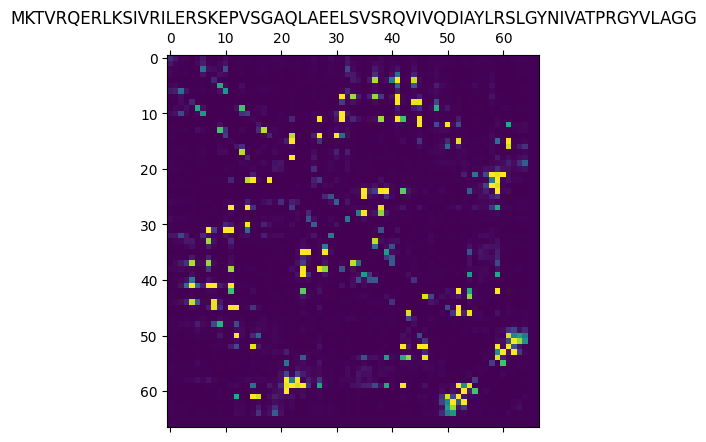

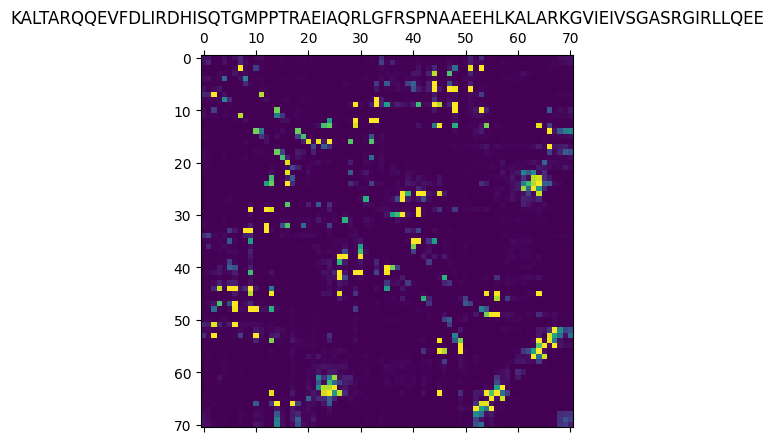

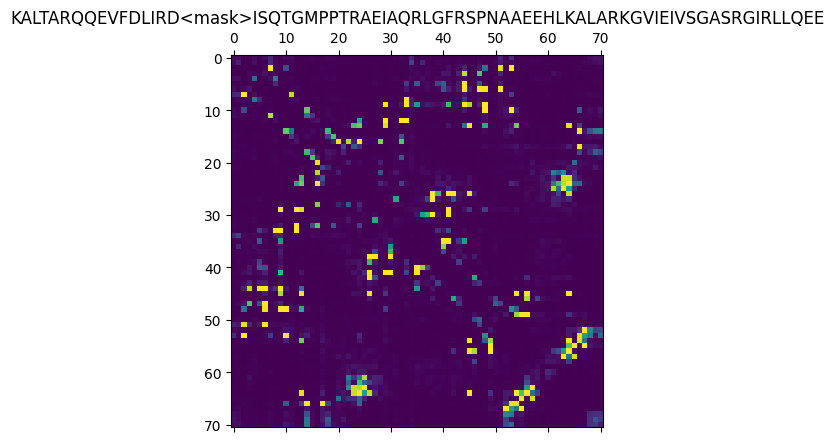

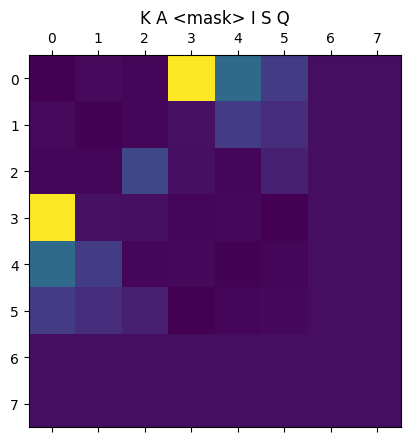

In [ ]:
import torch
import esm

# Load ESM-2 model
model, alphabet = esm.pretrained.esm2_t36_3B_UR50D()
batch_converter = alphabet.get_batch_converter()
model.eval()  # disables dropout for deterministic results

# Prepare data (first 2 sequences from ESMStructuralSplitDataset superfamily / 4)
data = [
    ("protein1", "MKTVRQERLKSIVRILERSKEPVSGAQLAEELSVSRQVIVQDIAYLRSLGYNIVATPRGYVLAGG"),
    ("protein2", "KALTARQQEVFDLIRDHISQTGMPPTRAEIAQRLGFRSPNAAEEHLKALARKGVIEIVSGASRGIRLLQEE"),
    ("protein2 with mask","KALTARQQEVFDLIRD<mask>ISQTGMPPTRAEIAQRLGFRSPNAAEEHLKALARKGVIEIVSGASRGIRLLQEE"),
    ("protein3",  "K A <mask> I S Q"),
]
batch_labels, batch_strs, batch_tokens = batch_converter(data)
batch_lens = (batch_tokens != alphabet.padding_idx).sum(1)

# Extract per-residue representations (on CPU)
with torch.no_grad():
    results = model(batch_tokens, repr_layers=[36], return_contacts=True)
token_representations = results["representations"][36]

# Generate per-sequence representations via averaging
# NOTE: token 0 is always a beginning-of-sequence token, so the first residue is token 1.
sequence_representations = []
for i, tokens_len in enumerate(batch_lens):
    sequence_representations.append(token_representations[i, 1 : tokens_len - 1].mean(0))

# Look at the unsupervised self-attention map contact predictions
import matplotlib.pyplot as plt
for (_, seq), tokens_len, attention_contacts in zip(data, batch_lens, results["contacts"]):
    plt.matshow(attention_contacts[: tokens_len, : tokens_len])
    plt.title(seq)
    plt.show()


## Pepare the dataset

In [77]:
import pandas as pd

# Load the dataset
file_path = "final_dataset/final_dataset_SLC19A2_model_5.pkl"

df = pd.read_pickle(file_path)

# Print the head of the dataframe
print("DataFrame Head:")
df


DataFrame Head:


,#chr,pos,variation,variant_type,snp_id,clinical_significance,validation_status,function_class,gene,frequency,...,Siberian_is_mentioned,Qatari_freq,Qatari_is_mentioned,Avg_Frequency,Max_Frequency,Min_Frequency,Total_Studies,by-frequency,by-alfa,by-cluster
0,1,169476354,T>C,snv,1000230073,NaN,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.000013:2:GnomAD_genomes|C:0.000008:2:TOPME...,...,0,0.000000,0,0.000031,0.000071,0.000008,3,1,1,1
1,1,169476354,T>C,snv,1000230073,normal,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.000013:2:GnomAD_genomes|C:0.000008:2:TOPME...,...,0,0.000000,0,0.082630,0.185311,0.005581,5,1,1,1
2,1,169475878,T>C,snv,1000304891,normal,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.000007:1:GnomAD_genomes|C:0.000008:2:TOPME...,...,0,0.000000,0,0.056416,0.175923,0.004349,11,1,1,1
3,1,169475878,T>C,snv,1000304891,NaN,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.000007:1:GnomAD_genomes|C:0.000008:2:TOPME...,...,0,0.000000,0,0.000007,0.000008,0.000007,2,1,1,1
4,1,169483460,T>C,snv,1000361639,normal,by-frequency;by-alfa,intron_variant,SLC19A2,C:0.:0:ALFA,...,0,0.100872,1,0.058910,0.139787,0.000490,14,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22128,1,169485475,"G>A,C,T",snv,999809738,NaN,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.005137:15:KOREAN|G:0.5:3:Siberian|A:0.0000...,...,0,0.000000,0,0.000015,0.000015,0.000015,1,1,1,1
22129,1,169485475,"G>A,C,T",snv,999809738,NaN,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.005137:15:KOREAN|G:0.5:3:Siberian|A:0.0000...,...,0,0.000000,0,0.005137,0.005137,0.005137,1,1,1,1
22130,1,169485475,"G>A,C,T",snv,999809738,NaN,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.005137:15:KOREAN|G:0.5:3:Siberian|A:0.0000...,...,0,0.000000,0,0.000000,0.000000,0.000000,0,1,1,1
22131,1,169481070,C>A,snv,999949244,normal,by-frequency;by-alfa,intron_variant,SLC19A2,A:0.000004:1:TOPMED|A:0.:0:ALFA,...,0,0.000000,0,0.141436,0.342026,0.015769,9,1,1,1


In [143]:
import pandas as pd
file_path = "custom_mutation.csv"

df = pd.read_csv(file_path)

# Print the head of the dataframe
print("DataFrame Head:")
# df


DataFrame Head:


In [78]:
file_path_2 = 'final_dataset/final_dataset_SLC19A3_model_5.pkl'

df_2 = pd.read_pickle(file_path_2)

# Print the head of the second dataframe
print("DataFrame 2 Head:")
print(df_2.head(), df_2.shape)


DataFrame 2 Head:
  #chr        pos variation variant_type      snp_id clinical_significance  \
0    2  227685064       G>A          snv  1000108682                   NaN   
1    2  227685064       G>A          snv  1000108682                normal   
2    2  227692888       A>T          snv  1000182811                   NaN   
3    2  227692888       A>T          snv  1000182811                normal   
4    2  227702777       T>A          snv  1000236352                   NaN   

                 validation_status       function_class     gene  \
0                              NaN  3_prime_UTR_variant  SLC19A3   
1                              NaN  3_prime_UTR_variant  SLC19A3   
2             by-frequency;by-alfa       intron_variant  SLC19A3   
3             by-frequency;by-alfa       intron_variant  SLC19A3   
4  by-frequency;by-alfa;by-cluster       intron_variant  SLC19A3   

                                           frequency  ... Avg_Frequency  \
0                            

In [61]:
# Find common columns between both dataframes
common_columns = df.columns.intersection(df_2.columns).tolist()
print(f"Common columns found: {len(common_columns)}")
print(f"Columns in df but not in df_2: {set(df.columns) - set(df_2.columns)}")
print(f"Columns in df_2 but not in df: {set(df_2.columns) - set(df.columns)}")

# Keep only common columns in both dataframes
df_common = df[common_columns].copy()
df_2_common = df_2[common_columns].copy()

# Concatenate the dataframes
df_combined = pd.concat([df_common, df_2_common], ignore_index=True)

print(f"\nOriginal df shape: {df.shape}")
print(f"Original df_2 shape: {df_2.shape}")
print(f"Combined dataframe shape: {df_combined.shape}")
print(f"Final number of columns: {len(common_columns)}")

# Remove duplicates if any
df_combined = df_combined.drop_duplicates()
print(f"Shape after removing duplicates: {df_combined.shape}")

Common columns found: 86
Columns in df but not in df_2: {'PharmGKB_is_mentioned', 'PharmGKB_freq'}
Columns in df_2 but not in df: set()

Original df shape: (22133, 88)
Original df_2 shape: (38892, 86)
Combined dataframe shape: (61025, 86)
Final number of columns: 86
Shape after removing duplicates: (55456, 86)


In [5]:
df_combined = df


In [79]:
# Drop any rows that contain error-related words (Error, error, fail, etc.)
print(f"Number of rows before cleaning: {len(df_combined)}")

# Convert all values to string and check for error-related terms case-insensitively
error_pattern = '(?i)(error|fail|exception|invalid|timeout|crash)'
mask = df_combined.astype(str).apply(lambda x: x.str.contains(error_pattern)).any(axis=1)
df_clean = df_combined[~mask]

print(f"Number of rows after cleaning: {len(df_clean)}")
print(f"Removed {len(df_combined) - len(df_clean)} rows containing error-related terms")

# Display the first few rows of the cleaned dataframe
df_clean.head()

Number of rows before cleaning: 55456


/tmp/ipykernel_1461280/1749372498.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = df_combined.astype(str).apply(lambda x: x.str.contains(error_pattern)).any(axis=1)


KeyboardInterrupt: 

In [80]:
#USE THIS if you don't want the bases outside the gene region
# Process the reverse_complement_dna column to remove first 2000 and last 1000 bases

"""
df_clean['reverse_complement_dna'] = df_clean['reverse_complement_dna'].apply(
    lambda seq: seq[2000:-1000] if len(seq) > 3000 else seq
)

# Display the processed dataframe
df_clean
"""

"\ndf_clean['reverse_complement_dna'] = df_clean['reverse_complement_dna'].apply(\n    lambda seq: seq[2000:-1000] if len(seq) > 3000 else seq\n)\n\n# Display the processed dataframe\ndf_clean\n"

In [81]:
df_clean = df_combined.copy()

In [82]:
# Rename the clinical_significance column to original_clinical_sig
if 'clinical_significance' in df_clean.columns and 'original_clinical_sig' not in df_clean.columns:
    df_clean = df_clean.rename(columns={'clinical_significance': 'original_clinical_sig'})
    print("Renamed 'clinical_significance' column to 'original_clinical_sig'")
elif 'original_clinical_sig' in df_clean.columns:
    print("Column 'original_clinical_sig' already exists")
else:
    print("Column 'clinical_significance' not found in the dataframe")

# Rename the generated_dna column to reverse_complement_dna if needed
if 'generated_dna' in df_clean.columns and 'reverse_complement_dna' not in df_clean.columns:
    df_clean = df_clean.rename(columns={'generated_dna': 'reverse_complement_dna'})
    print("Renamed 'generated_dna' column to 'reverse_complement_dna'")
elif 'reverse_complement_dna' in df_clean.columns:
    print("Column 'reverse_complement_dna' already exists")
else:
    print("Column 'generated_dna' not found in the dataframe")


Renamed 'clinical_significance' column to 'original_clinical_sig'
Renamed 'generated_dna' column to 'reverse_complement_dna'


In [83]:
# Identify SNP IDs with labels other than 'normal' and NaN
labeled_snps = df_clean.loc[
    (df_clean['original_clinical_sig'].notna()) & (df_clean['original_clinical_sig'] != 'nan') & (df_clean['original_clinical_sig'] != 'normal'),
    'snp_id'
].unique().tolist()

# Print the number of unique labeled SNP IDs
print(f"Found {len(labeled_snps)} unique SNP IDs with labels other than 'normal' and NaN")

# Filter dataframes based on SNP IDs
snp_id_mask = df_clean['snp_id'].isin(labeled_snps)
df_labeled = df_clean[snp_id_mask].copy()
df_unlabeled = df_clean[~snp_id_mask].copy()

print(f"Labeled data shape: {df_labeled.shape}")
print(f"Unlabeled data shape: {df_unlabeled.shape}")


Found 962 unique SNP IDs with labels other than 'normal' and NaN
Labeled data shape: (2333, 86)
Unlabeled data shape: (53123, 86)


In [84]:
# Count the number of rows before filtering
print(f"Total rows before filtering: {len(df_unlabeled)}")

# Identify rows with 'normal' clinical significance
normal_mask = df_unlabeled['original_clinical_sig'] == 'normal'
normal_indices = df_unlabeled[normal_mask].index
non_normal_indices = df_unlabeled[~normal_mask].index

# Calculate how many 'normal' samples to keep (10%)
keep_count = int(len(normal_indices) * 0.1)

# Randomly select 10% of 'normal' samples to keep
import random
random.seed(42)  # For reproducibility
indices_to_keep = random.sample(list(normal_indices), keep_count) if len(normal_indices) > 0 else []

# Create a new dataframe with reduced 'normal' samples
filtered_indices = list(indices_to_keep) + list(non_normal_indices)
unlabeled_df = df_unlabeled.loc[filtered_indices]

# Count the number of rows after filtering
print(f"Total rows after filtering: {len(unlabeled_df)}")
print(f"Removed {len(normal_indices) - keep_count} 'normal' samples ({90 if len(normal_indices) > 0 else 0}% of normal samples)")

# Display the first few rows


Total rows before filtering: 53123
Total rows after filtering: 31199
Removed 21924 'normal' samples (90% of normal samples)


## continue for training

In [85]:
# clean labels
preprocess = df_labeled.copy()
# First, clean up extra whitespace
preprocess["original_clinical_sig"] = preprocess["original_clinical_sig"].str.strip()

# Define a mapping dictionary for the specific replacements
replacement_mapping = {
    "likely-benign;benign-likely-benign": "likely-benign",
    "likely-pathogenic;pathogenic": "likely-pathogenic",
    "uncertain-significance;likely-pathogenic": "likely-pathogenic",
    "likely-pathogenic;uncertain-significance": "likely-pathogenic",
    "likely-benign;uncertain-significance": "likely-benign",
    "likely-benign;conflicting-interpretations-of-pathogenicity": "likely-benign",
    "pathogenic;pathogenic-likely-pathogenic": "pathogenic",
    "conflicting-interpretations-of-pathogenicity": "uncertain-significance",
    "uncertain-significance;likely-benign": "likely-benign",
    "conflicting-interpretations-of-pathogenicity;uncertain-significance": "uncertain-significance",
    "conflicting-interpretations-of-pathogenicity;benign-likely-benign": "likely-benign",
    "uncertain-significance;likely-benign;conflicting-interpretations-of-pathogenicity;benign": "likely-benign",
    "conflicting-interpretations-of-pathogenicity;likely-benign": "likely-benign",
    "benign-likely-benign;conflicting-interpretations-of-pathogenicity;uncertain-significance": "likely-benign",
    "benign-likely-benign;benign": "likely-benign",
    "benign;likely-benign": "likely-benign",
    "benign;likely-benign;conflicting-interpretations-of-pathogenicity": "likely-benign",
    "benign;likely-benign;conflicting-interpretations-of-pathogenicity;uncertain-significance": "likely-benign",
    "benign;likely-benign;conflicting-interpretations-of-pathogenicity;benign-likely-benign": "likely-benign",
    "benign;likely-benign;conflicting-interpretations-of-pathogenicity;benign": "likely-benign",
    "benign;likely-benign;conflicting-interpretations-of-pathogenicity;benign-likely-benign": "likely-benign",
    "uncertain-significance;pathogenic": "pathogenic",
    "likely-pathogenic;pathogenic-likely-pathogenic": "likely-pathogenic",
    "likely-pathogenic;benign": "uncertain-significance",
    "uncertain-significance;not-provided": "uncertain-significance",
    "uncertain-significance;benign-likely-benign": "likely-benign",
    "likely-benign;uncertain-significance;benign": "likely-benign",
    "benign-likely-benign;uncertain-significance;benign": "likely-benign",
    "pathogenic-likely-pathogenic;likely-pathogenic": "likely-pathogenic",
    "benign;uncertain-significance;likely-benign": "likely-benign",
    "benign;likely-benign;uncertain-significance": "likely-benign",
    "conflicting-interpretations-of-pathogenicity;uncertain-significance;likely-benign": "likely-benign",
    "pathogenic;likely-pathogenic": "likely-pathogenic",
    "uncertain-significance;not-provided": "uncertain-significance",
    "likely-benign;benign": "likely-benign",
    "uncertain-significance;benign-likely-benign": "likely-benign",
    "uncertain-significance;benign-likely-benign": "likely-benign",
    "conflicting-interpretations-of-pathogenicity;uncertain-significance;likely-benign": "likely-benign",
    "pathogenic;uncertain-significance": "likely-pathogenic",
    "benign;uncertain-significance": "likely-benign",
    "uncertain-significance;likely-benign;benign": "likely-benign",
    "pathogenic-likely-pathogenic": "likely-pathogenic",
    " pathogenic-likely-pathogenic;pathogenic": "pathogenic",
    "likely-benign;pathogenic":"uncertain-significance",
    "uncertain-significance;conflicting-interpretations-of-pathogenicity": "uncertain-significance",
    "likely-benign;conflicting-interpretations-of-pathogenicity;uncertain-significance": "likely-benign",
    "benign-likely-benign;uncertain-significance": "likely-benign",
    "pathogenic-likely-pathogenic;likely-benign;pathogenic": "likely-pathogenic",
    "benign;benign-likely-benign": "likely-benign",
    "benign-likely-benign;likely-benign": "likely-benign",
    "uncertain-significance;conflicting-interpretations-of-pathogenicity": "uncertain-significance",
    "pathogenic-likely-pathogenic;pathogenic": "likely-pathogenic",
    "pathogenic;likely-benign":"uncertain-significance",
    "likely-pathogenic;benign-likely-benign;uncertain-significance":"uncertain-significance",
    "benign;conflicting-interpretations-of-pathogenicity;likely-benign":"likely-benign",
    "conflicting-interpretations-of-pathogenicity;benign-likely-benign;likely-benign":"likely-benign",   
    "conflicting-interpretations-of-pathogenicity;likely-benign;uncertain-significance":"uncertain-significance",
}

# Make a copy of the original column to compare later
preprocess["clinical_significance_before"] = preprocess["original_clinical_sig"].copy()

# Replace exact string matches using the mapping
preprocess["original_clinical_sig"] = preprocess["original_clinical_sig"].replace(replacement_mapping)

# Count how many changes were made
changes_count = (preprocess["original_clinical_sig"] != preprocess["clinical_significance_before"]).sum()
print(f"\nNumber of clinical significance labels changed: {changes_count}")

# Drop the temporary column used for comparison
preprocess.drop("clinical_significance_before", axis=1, inplace=True)





Number of clinical significance labels changed: 26


In [86]:
df_processed = preprocess.copy()

# Map clinical significance to continuous labels
clinical_sig_mapping = {
    'normal': 3,
    'benign': 2,
    'likely-benign': 1,
    'uncertain-significance': 0,
    'likely-pathogenic': -1,
    'pathogenic': -2
}

# Create ContinuousLabel column based on original_clinical_sig
df_processed['ContinuousLabel'] = df_processed['original_clinical_sig'].map(clinical_sig_mapping)

# Rename reverse_complement_dna column to sequence
df_processed.rename(columns={'reverse_complement_dna': 'sequence'}, inplace=True)

# Print how many mappings have been done successfully
print(f"Successfully mapped {df_processed['ContinuousLabel'].count()} out of {len(df_processed)} clinical significance values.")

Successfully mapped 2333 out of 2333 clinical significance values.


In [87]:
for index, row in df_processed.iterrows():
    if pd.isna(row['ContinuousLabel']):
        print(f"Row {index} has an unrecognized clinical significance: {row['original_clinical_sig']}")
        print (f"clinical significance: {row['original_clinical_sig']}")

In [88]:
print(df_processed.shape)
df_processed.head()

# Print length of first 10 rows of sequence column
for i in range(min(10, len(df_processed))):
    print(f"Row {i} sequence length: {len(df_processed['sequence'].iloc[i])}")

(2333, 87)
Row 0 sequence length: 26062
Row 1 sequence length: 26062
Row 2 sequence length: 26062
Row 3 sequence length: 26062
Row 4 sequence length: 26062
Row 5 sequence length: 26062
Row 6 sequence length: 26062
Row 7 sequence length: 26062
Row 8 sequence length: 26055
Row 9 sequence length: 26052


In [89]:
# Shuffle and randomize the rows in df_processed
df_processed = df_processed.sample(frac=1, random_state=42).reset_index(drop=True)

# Display the shuffled dataframe
df_processed

,#chr,pos,variation,variant_type,snp_id,original_clinical_sig,validation_status,function_class,gene,frequency,...,Qatari_freq,Qatari_is_mentioned,Avg_Frequency,Max_Frequency,Min_Frequency,Total_Studies,by-frequency,by-alfa,by-cluster,ContinuousLabel
0,1,169470079,A>G,snv,552366444,normal,by-frequency;by-alfa;by-cluster,coding_sequence_variant;synonymous_variant,SLC19A2,G:0.0002:1:1000Genomes|G:0.000312:2:1000Genome...,...,0.112552,1,0.094020,0.391609,0.028547,11,1,1,1,3
1,2,227702267,T>C,snv,1574565534,normal,NaN,missense_variant;5_prime_UTR_variant;coding_se...,SLC19A3,NaN,...,0.000000,0,0.052837,0.106725,0.005606,8,1,1,1,3
2,2,227688250,G>A,snv,1574542050,likely-benign,NaN,synonymous_variant;coding_sequence_variant,SLC19A3,NaN,...,0.000000,0,0.000000,0.000000,0.000000,0,0,0,0,1
3,1,169468260,A>G,snv,751410694,likely-benign,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,G:0.0000087:1:ExAC|G:0.0000021:3:GnomAD_exomes...,...,0.000000,0,0.000006,0.000009,0.000002,4,1,1,1,1
4,2,227695891,T>G,snv,2106325855,normal,by-frequency;by-cluster,coding_sequence_variant;synonymous_variant,SLC19A3,G:0.000007:1:GnomAD_genomes,...,0.000000,0,0.046884,0.267671,0.001133,8,1,1,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2328,2,227688321,T>C,snv,2470555222,likely-benign,NaN,intron_variant,SLC19A3,NaN,...,0.000000,0,0.000000,0.000000,0.000000,0,0,0,0,1
2329,2,227687524,"A>C,G,T",snv,1308805272,normal,by-frequency;by-alfa;by-cluster,coding_sequence_variant;missense_variant,SLC19A3,T:0.00001:1:TOMMO|T:0.:0:ALFA,...,0.236664,1,0.091092,0.236664,0.014392,9,1,1,1,3
2330,2,227699202,"G>A,T",snv,1353757275,uncertain-significance,by-frequency;by-alfa;by-cluster,synonymous_variant;stop_gained;coding_sequence...,SLC19A3,A:0.00005:1:ALFA,...,0.000000,0,0.000000,0.000000,0.000000,0,1,1,1,0
2331,2,227698865,A>G,snv,1553571227,pathogenic,by-frequency;by-alfa;by-cluster,coding_sequence_variant;missense_variant,SLC19A3,G:0.0000014:2:GnomAD_exomes|G:0.:0:GnomAD_geno...,...,0.000000,0,0.000003,0.000004,0.000001,2,1,1,1,-2


## Continue for labeling

In [96]:

df_test = unlabeled_df.copy()
# Rename reverse_complement_dna column to sequence
df_test.rename(columns={'reverse_complement_dna': 'sequence'}, inplace=True)

In [97]:
print(df_test.shape)
df_processed = df_test

(31199, 86)


In [ ]:
# gener

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder 
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd # Make sure pandas is imported if pd.isna is used

# Ensure df_processed exists from the previous cell
if 'df_processed' not in locals():
    raise NameError("df_processed is not defined. Please run the previous cell to generate it.")
# Ensure get_dna_embeddings, model, and tokenizer are defined
if 'get_dna_embeddings' not in locals() or 'model' not in locals() or 'tokenizer' not in locals():
     raise NameError("get_dna_embeddings, model, or tokenizer is not defined. Please ensure they are loaded.")

# Set device to CUDA if available
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Move model to device
model = model.to(device)

# --- 1. Generate Embeddings using df_processed (Splitting Sequences) ---
print("Generating embeddings for processed sequences (splitting into 5 parts)...")
combined_embeddings_list_nn = []
sequences_list_nn = [] # Keep track of original sequences corresponding to embeddings
num_parts = 5
embedding_dim_per_part = -1 # Will be determined by the first successful embedding

# Use mean pooling embeddings for this task (applied to each part)
embedding_type_nn = 'mean' # or 'max' or 'concatenate'

# Limit the number of sequences for faster testing/debugging if needed
# df_subset_nn = df_processed.head(200) # Uncomment for testing
df_subset_nn = df_processed

# Assuming get_dna_embeddings, model, and tokenizer are defined from earlier cells
for index, row in tqdm(df_subset_nn.iterrows(), total=df_subset_nn.shape[0], desc="Processing sequences for NN"):
    sequence = row['sequence']

    # Ensure sequence is a string and not empty
    if not isinstance(sequence, str) or len(sequence) == 0:
        print(f"Skipping row {index}: Invalid sequence '{sequence}'")
        continue

    # Ensure sequence is long enough to be split (optional, depends on desired handling)
    min_len_per_part = 10 # Example minimum length for a part to be meaningful
    if len(sequence) < num_parts * min_len_per_part:
        print(f"Skipping row {index}: Sequence too short ({len(sequence)} bases) to split into {num_parts} parts of min length {min_len_per_part}.")
        continue

    part_embeddings = []
    try:
        # Split sequence into num_parts roughly equal parts
        seq_len = len(sequence)
        part_len = seq_len // num_parts
        start_indices = [i * part_len for i in range(num_parts)]
        # Adjust the last part to include any remainder
        end_indices = [(i + 1) * part_len for i in range(num_parts - 1)] + [seq_len]

        for i in range(num_parts):
            sub_sequence = sequence[start_indices[i]:end_indices[i]]

            if len(sub_sequence) == 0: # Should not happen with the length check above, but good practice
                print(f"Warning: Skipping empty sub-sequence for row {index}, part {i+1}")
                continue # Or handle by padding/zero-vector

            # Get embeddings for the sub-sequence
            emb_mean, emb_max = get_dna_embeddings(sub_sequence, model, tokenizer)

            if embedding_type_nn == 'mean':
                embedding_part = emb_mean.cpu().numpy().flatten() # Flatten in case it's not already 1D
            elif embedding_type_nn == 'max':
                embedding_part = emb_max.cpu().numpy().flatten()
            elif embedding_type_nn == 'concatenate':
                # Concatenate along feature dim (dim=1 if batch dim exists, dim=0 otherwise)
                embedding_part = torch.cat((emb_mean, emb_max), dim=emb_mean.dim()-1).cpu().numpy().flatten()
            else:
                 # Default to mean if type is unknown
                embedding_part = emb_mean.cpu().numpy().flatten()

            if embedding_dim_per_part == -1:
                embedding_dim_per_part = len(embedding_part) # Set the expected dimension

            # Ensure consistent embedding dimension (handle potential errors from get_dna_embeddings)
            if len(embedding_part) != embedding_dim_per_part:
                 raise ValueError(f"Inconsistent embedding dimension for part {i+1} of sequence {index}. Expected {embedding_dim_per_part}, got {len(embedding_part)}.")

            part_embeddings.append(embedding_part)

        # Check if we got the expected number of embeddings
        if len(part_embeddings) == num_parts:
            # Combine the embeddings for the parts (concatenate them)
            combined_embedding = np.concatenate(part_embeddings)
            combined_embeddings_list_nn.append(combined_embedding)
            sequences_list_nn.append(sequence) # Store the original sequence
        else:
             print(f"Skipping row {index}: Could not generate embeddings for all {num_parts} parts (got {len(part_embeddings)}).")


    except Exception as e:
        print(f"Error processing sequence at index {index} ('{sequence[:30]}...'): {e}")
        # Optionally skip problematic sequences or handle differently
        continue

# Convert lists to NumPy arrays
X_nn = np.array(combined_embeddings_list_nn)

if X_nn.shape[0] > 0:
    print(f"\nGenerated {X_nn.shape[0]} combined embeddings of shape {X_nn.shape[1]} (from {num_parts} parts).")
    print(f"Individual part embedding dimension: {embedding_dim_per_part}")
else:
    print("\nNo combined embeddings were generated. Cannot proceed with further processing.")
    # Exit or handle the case where no data is available
    # raise SystemExit("Stopping execution: No embeddings generated.") # Or similar

NameError: get_dna_embeddings, model, or tokenizer is not defined. Please ensure they are loaded.

In [ ]:
# Save DNA-BERT embeddings with timestamp
import time
timestamp = int(time.time())
np.save(f"embeddings/dnabert_embeddings_labeling_external{timestamp}.npy", X_nn)
print(f"Saved DNA-BERT embeddings to embeddings/dnabert_embeddings_labeling_external{timestamp}.npy")

Saved DNA-BERT embeddings to embeddings/dnabert_embeddings_labeling_external1757625280.npy


In [98]:
# Load the specific DNA-BERT embeddings file
import os
import numpy as np

# Load the specific file
file_path = "embeddings/dnabert_embeddings_labeling_external1757407509.npy"
X_nn = np.load(file_path)
print(f"Loaded DNA-BERT embeddings from {file_path}")
print(f"Loaded embedding shape: {X_nn.shape}")


Loaded DNA-BERT embeddings from embeddings/dnabert_embeddings_labeling_external1757407509.npy
Loaded embedding shape: (22, 3840)


In [99]:
# Load the specific DNA-BERT embeddings file
import os
import numpy as np

# Load the specific file
file_path = "embeddings/dnabert_embeddings_labeling_both1754989195.npy"
X_nn = np.load(file_path)
print(f"Loaded DNA-BERT embeddings from {file_path}")
print(f"Loaded embedding shape: {X_nn.shape}")


Loaded DNA-BERT embeddings from embeddings/dnabert_embeddings_labeling_both1754989195.npy
Loaded embedding shape: (31199, 3840)


In [ ]:
# --- 2. Generate Embeddings using ESM-2 model ---
print("Generating embeddings using ESM-2 model...")

# Load ESM-2 model (smaller version for efficiency)
print("Loading ESM-2 model...")
import esm
esm_model, alphabet = esm.pretrained.esm2_t36_3B_UR50D()
batch_converter = alphabet.get_batch_converter()
esm_model.eval()  # disables dropout for deterministic results

# Move model to GPU if available
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
esm_model = esm_model.to(device)

# Function to get ESM-2 embeddings for protein sequences
def get_esm2_embeddings(sequence, model, alphabet, batch_converter, device):
    # Prepare data for ESM-2
    data = [("seq", sequence)]
    batch_labels, batch_strs, batch_tokens = batch_converter(data)
    
    # Move to GPU
    batch_tokens = batch_tokens.to(device)
    
    # Get embeddings
    with torch.no_grad():
        results = model(batch_tokens, repr_layers=[36], return_contacts=True)
    token_representations = results["representations"][36]
    
    # Generate sequence representation via averaging (mean pooling)
    # NOTE: token 0 is always a beginning-of-sequence token, so the first residue is token 1.
    batch_lens = (batch_tokens != alphabet.padding_idx).sum(1)
    sequence_representation = token_representations[0, 1:batch_lens[0]-1].mean(0)
    
    # Also compute max pooling for comparison
    sequence_representation_max = token_representations[0, 1:batch_lens[0]-1].max(0)[0]
    
    return sequence_representation, sequence_representation_max

# Lists to store ESM-2 embeddings
embeddings_list_esm2 = []
sequences_list_esm2 = []
error_snp_ids = []  # Track SNP IDs with errors

# Process sequences with ESM-2
for index, row in tqdm(df_subset_nn.iterrows(), total=df_subset_nn.shape[0], desc="Processing sequences for ESM-2"):
    # Use protein_sequence column instead of sequence
    sequence = row['protein_sequence']
    snp_id = row.get('snp_id', 'unknown')  # Get SNP ID if available
    
    # Ensure sequence is a string and not empty
    if not isinstance(sequence, str) or len(sequence) == 0:
        print(f"Skipping row {index}: Invalid protein sequence '{sequence}'")
        error_snp_ids.append(snp_id)
        continue
    
    try:
        # Get embeddings for the whole sequence using ESM-2
        emb_mean, emb_max = get_esm2_embeddings(sequence, esm_model, alphabet, batch_converter, device)
        
        # Use mean embeddings by default
        embedding = emb_mean.cpu().numpy().flatten()
        
        # Store the embedding and corresponding sequence
        embeddings_list_esm2.append(embedding)
        sequences_list_esm2.append(sequence)
    
    except Exception as e:
        print(f"Error processing protein sequence at index {index} ('{sequence[:30]}...'): {e}")
        error_snp_ids.append(snp_id)
        continue

# Convert lists to NumPy arrays
X_nn_esm2 = np.array(embeddings_list_esm2)

if X_nn_esm2.shape[0] > 0:
    print(f"\nGenerated {X_nn_esm2.shape[0]} ESM-2 embeddings of shape {X_nn_esm2.shape[1]}")
else:
    print("\nNo ESM-2 embeddings were generated. Cannot proceed with ESM-2 model training.")

# Print SNP IDs with errors
if error_snp_ids:
    print("\nSNP IDs with errors during ESM-2 embedding generation:")
    for snp_id in error_snp_ids:
        print(f"  - {snp_id}")


Generating embeddings using ESM-2 model...
Loading ESM-2 model...


ModuleNotFoundError: No module named 'esm'

In [ ]:
# Save the generated ESM-2 embeddings locally
if X_nn_esm2.shape[0] > 0:
    print("\nSaving ESM-2 embeddings to disk...")
    import datetime
    import os
    
    # Generate timestamp for filenames
    timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    
    # Save embeddings and labels with timestamp
    file_path = os.path.join("embeddings", f"labeling_external_data_{timestamp}.npy")
    np.save(file_path, X_nn_esm2)
    print(f"Saved ESM-2 embeddings to {file_path}")
else:
    print("No ESM-2 embeddings to save.")



Saving ESM-2 embeddings to disk...
Saved ESM-2 embeddings to embeddings/labeling_external_data_20250909_014714.npy


In [94]:
# Load the previously saved ESM-2 embeddings
import numpy as np
import os

# Path to the saved embeddings
embeddings_path = "embeddings/labeling_external_data_20250909_014714.npy"

# Check if the file exists
if os.path.exists(embeddings_path):
    print(f"Loading ESM-2 embeddings from {embeddings_path}...")
    X_nn_esm2 = np.load(embeddings_path)
    print(f"Loaded ESM-2 embeddings with shape: {X_nn_esm2.shape}")
else:
    print(f"Error: Could not find embeddings file at {embeddings_path}")
    X_nn_esm2 = np.array([])

Loading ESM-2 embeddings from embeddings/labeling_external_data_20250909_014714.npy...
Loaded ESM-2 embeddings with shape: (22, 2560)


In [100]:
# BIG DATA loading
import numpy as np
import os

# Path to the saved embeddings
embeddings_path = "embeddings/labeling_SLC19A2_X_nn_esm2_20250812_105918.npy"

# Check if the file exists
if os.path.exists(embeddings_path):
    print(f"Loading ESM-2 embeddings from {embeddings_path}...")
    X_nn_esm2 = np.load(embeddings_path)
    print(f"Loaded ESM-2 embeddings with shape: {X_nn_esm2.shape}")
else:
    print(f"Error: Could not find embeddings file at {embeddings_path}")
    X_nn_esm2 = np.array([])

Loading ESM-2 embeddings from embeddings/labeling_SLC19A2_X_nn_esm2_20250812_105918.npy...
Loaded ESM-2 embeddings with shape: (31199, 2560)


In [101]:
print(df_processed.columns.tolist())

['#chr', 'pos', 'variation', 'variant_type', 'snp_id', 'original_clinical_sig', 'validation_status', 'function_class', 'gene', 'frequency', 'original', 'mutant', 'sequence', 'generated_mRNA', 'protein_sequence', 'MGP_freq', 'MGP_is_mentioned', 'HGDP_Stanford_freq', 'HGDP_Stanford_is_mentioned', 'FINRISK_freq', 'FINRISK_is_mentioned', 'Chileans_freq', 'Chileans_is_mentioned', 'GENOME_DK_freq', 'GENOME_DK_is_mentioned', 'GnomAD_exomes_freq', 'GnomAD_exomes_is_mentioned', 'SGDP_PRJ_freq', 'SGDP_PRJ_is_mentioned', 'ExAC_freq', 'ExAC_is_mentioned', 'PAGE_STUDY_freq', 'PAGE_STUDY_is_mentioned', 'Korea1K_freq', 'Korea1K_is_mentioned', 'Estonian_freq', 'Estonian_is_mentioned', 'ALSPAC_freq', 'ALSPAC_is_mentioned', 'Korea4K_freq', 'Korea4K_is_mentioned', 'KOREAN_freq', 'KOREAN_is_mentioned', 'GENOGRAPHIC_freq', 'GENOGRAPHIC_is_mentioned', 'Daghestan_freq', 'Daghestan_is_mentioned', 'GoNL_freq', 'GoNL_is_mentioned', 'TOMMO_freq', 'TOMMO_is_mentioned', '1000Genomes_30X_freq', '1000Genomes_30X_is_

In [102]:
import numpy as np

x_3_columns = ['PRJEB37584_freq', 'PRJEB37584_is_mentioned', 'GoNL_freq', 'GoNL_is_mentioned', 'GnomAD_genomes_freq', 'GnomAD_genomes_is_mentioned', 'TOPMED_freq', 'TOPMED_is_mentioned', 'TWINSUK_freq', 'TWINSUK_is_mentioned', 'ALSPAC_freq', 'ALSPAC_is_mentioned', 'Siberian_freq', 'Siberian_is_mentioned', 'SGDP_PRJ_freq', 'SGDP_PRJ_is_mentioned', 'GENOME_DK_freq', 'GENOME_DK_is_mentioned', 'GoESP_freq', 'GoESP_is_mentioned', 'Chileans_freq', 'Chileans_is_mentioned', 'HGDP_Stanford_freq', 'HGDP_Stanford_is_mentioned', 'HapMap_freq', 'HapMap_is_mentioned', 'NorthernSweden_freq', 'NorthernSweden_is_mentioned', 'Korea4K_freq', 'Korea4K_is_mentioned', 'GnomAD_exomes_freq', 'GnomAD_exomes_is_mentioned', 'Vietnamese_freq', 'Vietnamese_is_mentioned', 'ALFA_freq', 'ALFA_is_mentioned', 'Daghestan_freq', 'Daghestan_is_mentioned', 'GENOGRAPHIC_freq', 'GENOGRAPHIC_is_mentioned', 'Korea1K_freq', 'Korea1K_is_mentioned', 'PAGE_STUDY_freq', 'PAGE_STUDY_is_mentioned', 'Estonian_freq', 'Estonian_is_mentioned', 'TOMMO_freq', 'TOMMO_is_mentioned', 'PRJEB36033_freq', 'PRJEB36033_is_mentioned', '1000Genomes_30X_freq', '1000Genomes_30X_is_mentioned', '1000Genomes_freq', '1000Genomes_is_mentioned', 'Qatari_freq', 'Qatari_is_mentioned', 'KOREAN_freq', 'KOREAN_is_mentioned', 'FINRISK_freq', 'FINRISK_is_mentioned', 'ExAC_freq', 'ExAC_is_mentioned', 'MGP_freq', 'MGP_is_mentioned', 'Avg_Frequency', 'Max_Frequency', 'Min_Frequency', 'Total_Studies', 'by-frequency', 'by-alfa', 'by-cluster']
x_3 = df_processed.values[:, df_processed.columns.isin(x_3_columns)]
# Ensure x_3 is a NumPy array of type float32
x_3 = np.array(x_3, dtype=np.float32)
print("x_3 type:", type(x_3))
print("x_3 dtype:", x_3.dtype)
print("x_3 shape:", x_3.shape)
x_3[0:32,:]


x_3 type: <class 'numpy.ndarray'>
x_3 dtype: float32
x_3 shape: (31199, 71)


array([[0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ],
       [0.01121822, 1.        , 0.        , ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.09765211, ..., 1.        , 1.        ,
        1.        ],
       ...,
       [0.        , 0.        , 0.04334324, ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ]], dtype=float32)

In [103]:
import numpy as np

x_3_columns = ['PRJEB37584_freq', 'PRJEB37584_is_mentioned', 'GoNL_freq', 'GoNL_is_mentioned', 'GnomAD_genomes_freq', 'GnomAD_genomes_is_mentioned', 'TOPMED_freq', 'TOPMED_is_mentioned', 'TWINSUK_freq', 'TWINSUK_is_mentioned', 'ALSPAC_freq', 'ALSPAC_is_mentioned', 'Siberian_freq', 'Siberian_is_mentioned', 'SGDP_PRJ_freq', 'SGDP_PRJ_is_mentioned', 'GENOME_DK_freq', 'GENOME_DK_is_mentioned', 'GoESP_freq', 'GoESP_is_mentioned', 'Chileans_freq', 'Chileans_is_mentioned', 'HGDP_Stanford_freq', 'HGDP_Stanford_is_mentioned', 'HapMap_freq', 'HapMap_is_mentioned', 'NorthernSweden_freq', 'NorthernSweden_is_mentioned', 'Korea4K_freq', 'Korea4K_is_mentioned', 'GnomAD_exomes_freq', 'GnomAD_exomes_is_mentioned', 'Vietnamese_freq', 'Vietnamese_is_mentioned', 'ALFA_freq', 'ALFA_is_mentioned', 'Daghestan_freq', 'Daghestan_is_mentioned', 'GENOGRAPHIC_freq', 'GENOGRAPHIC_is_mentioned', 'Korea1K_freq', 'Korea1K_is_mentioned', 'PAGE_STUDY_freq', 'PAGE_STUDY_is_mentioned', 'Estonian_freq', 'Estonian_is_mentioned', 'TOMMO_freq', 'TOMMO_is_mentioned', 'PRJEB36033_freq', 'PRJEB36033_is_mentioned', '1000Genomes_30X_freq', '1000Genomes_30X_is_mentioned', '1000Genomes_freq', '1000Genomes_is_mentioned', 'Qatari_freq', 'Qatari_is_mentioned', 'KOREAN_freq', 'KOREAN_is_mentioned', 'FINRISK_freq', 'FINRISK_is_mentioned', 'ExAC_freq', 'ExAC_is_mentioned', 'MGP_freq', 'MGP_is_mentioned', 'Avg_Frequency', 'Max_Frequency', 'Min_Frequency', 'Total_Studies', 'by-frequency', 'by-alfa', 'by-cluster']
x_3 = df_processed.values[:, df_processed.columns.isin(x_3_columns)]
# Ensure x_3 is a NumPy array of type float32
x_3 = np.array(x_3, dtype=np.float32)
print("x_3 type:", type(x_3))
print("x_3 dtype:", x_3.dtype)
print("x_3 shape:", x_3.shape)
x_3[0:32,:]


x_3 type: <class 'numpy.ndarray'>
x_3 dtype: float32
x_3 shape: (31199, 71)


array([[0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ],
       [0.01121822, 1.        , 0.        , ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.09765211, ..., 1.        , 1.        ,
        1.        ],
       ...,
       [0.        , 0.        , 0.04334324, ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ]], dtype=float32)

In [104]:
# Ensure that the number of embeddings from both methods match
if X_nn.shape[0] != X_nn_esm2.shape[0]:
    raise ValueError("Mismatch in number of embeddings: DNA embeddings have shape {} while ESM-2 embeddings have shape {}.".format(X_nn.shape, X_nn_esm2.shape))

# Fuse the embeddings by concatenating along the feature dimension (axis=1)
X_fused = np.concatenate((X_nn, X_nn_esm2,x_3), axis=1)

# Print the shape of the fused embeddings
print("Fused embeddings shape:", X_fused.shape)


Fused embeddings shape: (31199, 6471)


## Generating Embeddings (training)

### DNABERT EMBEDDINGS

In [ ]:
# gener

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd # Make sure pandas is imported if pd.isna is used

# Ensure df_processed exists from the previous cell
if 'df_processed' not in locals():
    raise NameError("df_processed is not defined. Please run the previous cell to generate it.")
# Ensure get_dna_embeddings, model, and tokenizer are defined
if 'get_dna_embeddings' not in locals() or 'model' not in locals() or 'tokenizer' not in locals():
     raise NameError("get_dna_embeddings, model, or tokenizer is not defined. Please ensure they are loaded.")

# Set device to CUDA if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Move model to device
model = model.to(device)

# --- 1. Generate Embeddings using df_processed (Splitting Sequences) ---
print("Generating embeddings for processed sequences (splitting into 5 parts)...")
combined_embeddings_list_nn = []
labels_list_nn = []
sequences_list_nn = [] # Keep track of original sequences corresponding to embeddings
num_parts = 5
embedding_dim_per_part = -1 # Will be determined by the first successful embedding

# Use mean pooling embeddings for this task (applied to each part)
embedding_type_nn = 'mean' # or 'max' or 'concatenate'

# Limit the number of sequences for faster testing/debugging if needed
# df_subset_nn = df_processed.head(200) # Uncomment for testing
df_subset_nn = df_processed

# Assuming get_dna_embeddings, model, and tokenizer are defined from earlier cells
for index, row in tqdm(df_subset_nn.iterrows(), total=df_subset_nn.shape[0], desc="Processing sequences for NN"):
    sequence = row['sequence']
    label = row['ContinuousLabel'] # Assuming this is the correct label column

    # Ensure sequence is a string and not empty
    if not isinstance(sequence, str) or len(sequence) == 0:
        print(f"Skipping row {index}: Invalid sequence '{sequence}'")
        continue

    # Ensure label is valid (e.g., not NaN)
    if pd.isna(label):
        print(f"Skipping row {index}: Invalid label '{label}'")
        continue

    # Ensure sequence is long enough to be split (optional, depends on desired handling)
    min_len_per_part = 10 # Example minimum length for a part to be meaningful
    if len(sequence) < num_parts * min_len_per_part:
        print(f"Skipping row {index}: Sequence too short ({len(sequence)} bases) to split into {num_parts} parts of min length {min_len_per_part}.")
        continue

    part_embeddings = []
    try:
        # Split sequence into num_parts roughly equal parts
        seq_len = len(sequence)
        part_len = seq_len // num_parts
        start_indices = [i * part_len for i in range(num_parts)]
        # Adjust the last part to include any remainder
        end_indices = [(i + 1) * part_len for i in range(num_parts - 1)] + [seq_len]

        for i in range(num_parts):
            sub_sequence = sequence[start_indices[i]:end_indices[i]]

            if len(sub_sequence) == 0: # Should not happen with the length check above, but good practice
                print(f"Warning: Skipping empty sub-sequence for row {index}, part {i+1}")
                continue # Or handle by padding/zero-vector

            # Get embeddings for the sub-sequence
            emb_mean, emb_max = get_dna_embeddings(sub_sequence, model, tokenizer)

            if embedding_type_nn == 'mean':
                embedding_part = emb_mean.cpu().numpy().flatten() # Flatten in case it's not already 1D
            elif embedding_type_nn == 'max':
                embedding_part = emb_max.cpu().numpy().flatten()
            elif embedding_type_nn == 'concatenate':
                # Concatenate along feature dim (dim=1 if batch dim exists, dim=0 otherwise)
                embedding_part = torch.cat((emb_mean, emb_max), dim=emb_mean.dim()-1).cpu().numpy().flatten()
            else:
                 # Default to mean if type is unknown
                embedding_part = emb_mean.cpu().numpy().flatten()

            if embedding_dim_per_part == -1:
                embedding_dim_per_part = len(embedding_part) # Set the expected dimension

            # Ensure consistent embedding dimension (handle potential errors from get_dna_embeddings)
            if len(embedding_part) != embedding_dim_per_part:
                 raise ValueError(f"Inconsistent embedding dimension for part {i+1} of sequence {index}. Expected {embedding_dim_per_part}, got {len(embedding_part)}.")

            part_embeddings.append(embedding_part)

        # Check if we got the expected number of embeddings
        if len(part_embeddings) == num_parts:
            # Combine the embeddings for the parts (concatenate them)
            combined_embedding = np.concatenate(part_embeddings)
            combined_embeddings_list_nn.append(combined_embedding)
            labels_list_nn.append(label)
            sequences_list_nn.append(sequence) # Store the original sequence
        else:
             print(f"Skipping row {index}: Could not generate embeddings for all {num_parts} parts (got {len(part_embeddings)}).")


    except Exception as e:
        print(f"Error processing sequence at index {index} ('{sequence[:30]}...'): {e}")
        # Optionally skip problematic sequences or handle differently
        continue

# Convert lists to NumPy arrays
X_nn = np.array(combined_embeddings_list_nn)
y_nn_original = np.array(labels_list_nn)

if X_nn.shape[0] > 0:
    print(f"\nGenerated {X_nn.shape[0]} combined embeddings of shape {X_nn.shape[1]} (from {num_parts} parts).")
    print(f"Individual part embedding dimension: {embedding_dim_per_part}")
    print(f"Corresponding labels shape: {y_nn_original.shape}")
else:
    print("\nNo combined embeddings were generated. Cannot proceed with NN training.")
    # Exit or handle the case where no data is available
    # raise SystemExit("Stopping execution: No embeddings generated.") # Or similar

Using device: cuda
Generating embeddings for processed sequences (splitting into 5 parts)...


Processing sequences for NN:   0%|          | 0/2333 [00:00<?, ?it/s]/home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_layers.py:433: UserWarning: Increasing alibi size from 512 to 1026
  warnings.warn(
Processing sequences for NN:   0%|          | 1/2333 [00:00<16:35,  2.34it/s]/home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_layers.py:433: UserWarning: Increasing alibi size from 1026 to 1410
  warnings.warn(
/home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_layers.py:433: UserWarning: Increasing alibi size from 1410 to 1429
  warnings.warn(
Processing sequences for NN:   3%|▎         | 78/2333 [00:12<06:34,  5.72it/s]/home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_la


Generated 2333 combined embeddings of shape 3840 (from 5 parts).
Individual part embedding dimension: 768
Corresponding labels shape: (2333,)


In [16]:
# Save DNA-BERT embeddings with timestamp
import numpy as np
import time
timestamp = int(time.time())
np.save(f"embeddings/dnabert_embeddings_{timestamp}.npy", X_nn)
print(f"Saved DNA-BERT embeddings to dnabert_embeddings_{timestamp}.npy")

NameError: name 'X_nn' is not defined

In [26]:
import numpy as np

In [27]:
# Load the DNA-BERT embeddings from the specified file
X_nn = np.load("embeddings/dnabert_embeddings_1754981297.npy")
print(f"Loaded DNA-BERT embeddings from embeddings/dnabert_embeddings_1754981297.npy with shape: {X_nn.shape}")

Loaded DNA-BERT embeddings from embeddings/dnabert_embeddings_1754981297.npy with shape: (2333, 3840)


### SM-2 Embeddings

In [ ]:
import numpy as np
# --- 2. Generate Embeddings using ESM-2 model ---
print("Generating embeddings using ESM-2 model...")

# Load ESM-2 model (smaller version for efficiency)
print("Loading ESM-2 model...")
import esm
from tqdm.auto import tqdm

esm_model, alphabet = esm.pretrained.esm2_t36_3B_UR50D()
batch_converter = alphabet.get_batch_converter()
esm_model.eval()  # disables dropout for deterministic results

# Move model to GPU device 1 if available
device = torch.device("cuda:1" if torch.cuda.is_available() and torch.cuda.device_count() > 1 else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
esm_model = esm_model.to(device)
df_subset_nn = df_processed
# Function to get ESM-2 embeddings for protein sequences
def get_esm2_embeddings(sequence, model, alphabet, batch_converter, device):
    # Prepare data for ESM-2
    data = [("seq", sequence)]
    batch_labels, batch_strs, batch_tokens = batch_converter(data)
    
    # Move to GPU
    batch_tokens = batch_tokens.to(device)
    
    # Get embeddings
    with torch.no_grad():
        results = model(batch_tokens, repr_layers=[36], return_contacts=True)
    token_representations = results["representations"][36]
    
    # Generate sequence representation via averaging (mean pooling)
    # NOTE: token 0 is always a beginning-of-sequence token, so the first residue is token 1.
    batch_lens = (batch_tokens != alphabet.padding_idx).sum(1)
    sequence_representation = token_representations[0, 1:batch_lens[0]-1].mean(0)
    
    # Also compute max pooling for comparison
    sequence_representation_max = token_representations[0, 1:batch_lens[0]-1].max(0)[0]
    
    return sequence_representation, sequence_representation_max

# Lists to store ESM-2 embeddings
embeddings_list_esm2 = []
labels_list_esm2 = []
sequences_list_esm2 = []
error_snp_ids = []  # Track SNP IDs with errors

# Process sequences with ESM-2
for index, row in tqdm(df_subset_nn.iterrows(), total=df_subset_nn.shape[0], desc="Processing sequences for ESM-2"):
    # Use protein_sequence column instead of sequence
    sequence = row['protein_sequence']
    label = row['ContinuousLabel']
    snp_id = row.get('snp_id', 'unknown')  # Get SNP ID if available
    
    # Ensure sequence is a string and not empty
    if not isinstance(sequence, str) or len(sequence) == 0:
        print(f"Skipping row {index}: Invalid protein sequence '{sequence}'")
        error_snp_ids.append(snp_id)
        continue
    
    # Ensure label is valid
    if pd.isna(label):
        print(f"Skipping row {index}: Invalid label '{label}'")
        error_snp_ids.append(snp_id)
        continue
    
    try:
        # Get embeddings for the whole sequence using ESM-2
        emb_mean, emb_max = get_esm2_embeddings(sequence, esm_model, alphabet, batch_converter, device)
        
        # Use mean embeddings by default
        embedding = emb_mean.cpu().numpy().flatten()
        
        # Store the embedding and corresponding label
        embeddings_list_esm2.append(embedding)
        labels_list_esm2.append(label)
        sequences_list_esm2.append(sequence)
    
    except Exception as e:
        print(f"Error processing protein sequence at index {index} ('{sequence[:30]}...'): {e}")
        error_snp_ids.append(snp_id)
        continue

# Convert lists to NumPy arrays
X_nn_esm2 = np.array(embeddings_list_esm2)
y_nn_esm2 = np.array(labels_list_esm2)

if X_nn_esm2.shape[0] > 0:
    print(f"\nGenerated {X_nn_esm2.shape[0]} ESM-2 embeddings of shape {X_nn_esm2.shape[1]}")
    print(f"Corresponding labels shape: {y_nn_esm2.shape}")
else:
    print("\nNo ESM-2 embeddings were generated. Cannot proceed with ESM-2 model training.")

# Print SNP IDs with errors
if error_snp_ids:
    print("\nSNP IDs with errors during ESM-2 embedding generation:")
    for snp_id in error_snp_ids:
        print(f"  - {snp_id}")


Generating embeddings using ESM-2 model...
Loading ESM-2 model...
Using device: cuda:1


Processing sequences for ESM-2: 100%|██████████| 2333/2333 [08:28<00:00,  4.59it/s]


Generated 2333 ESM-2 embeddings of shape 2560
Corresponding labels shape: (2333,)


In [ ]:
# Save the generated ESM-2 embeddings locally
if X_nn_esm2.shape[0] > 0:
    print("\nSaving ESM-2 embeddings to disk...")
    import os
    import datetime
    
    # Create directory if it doesn't exist
    save_dir = "embeddings"
    if not os.path.exists(save_dir):
        os.makedirs(save_dir)
        print(f"Created directory: {save_dir}")
    
    # Generate timestamp for filenames
    timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    
    # Save embeddings and labels with timestamp
    np.save(os.path.join(save_dir, f"X_nn_esm2_{timestamp}.npy"), X_nn_esm2)
    np.save(os.path.join(save_dir, f"y_nn_esm2_{timestamp}.npy"), y_nn_esm2)
    
    # Save sequences for reference with timestamp
    with open(os.path.join(save_dir, f"sequences_esm2_{timestamp}.txt"), "w") as f:
        for seq in sequences_list_esm2:
            f.write(f"{seq}\n")
    
    print(f"Saved ESM-2 embeddings to {save_dir}/X_nn_esm2_{timestamp}.npy")
    print(f"Saved labels to {save_dir}/y_nn_esm2_{timestamp}.npy")
    print(f"Saved sequences to {save_dir}/sequences_esm2_{timestamp}.txt")
else:
    print("No ESM-2 embeddings to save.")



Saving ESM-2 embeddings to disk...


╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:22                                                                                   │
│                                                                                                  │
│   19 │                                                                                           │
│   20 │   # Save sequences for reference with timestamp                                           │
│   21 │   with open(os.path.join(save_dir, f"sequences_esm2_{timestamp}.txt"), "w") as f:         │
│ ❱ 22 │   │   for seq in sequences_list_esm2:                                                     │
│   23 │   │   │   f.write(f"{seq}\n")                                                             │
│   24 │                                                                                           │
│   25 │   print(f"Saved ESM-2 embeddings to {save_dir}/X_nn_esm2_{timestamp}.npy")                │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯
NameError: name 'sequences_list_esm2' is not defined

In [28]:
import numpy as np
import os

# Path to the saved ESM-2 embeddings file
embeddings_path_1 = "embeddings/X_nn_esm2_20250811_235944.npy"
embeddings_path_2 = "embeddings/y_nn_esm2_20250811_235944.npy"
X_nn_esm2 = np.load(embeddings_path_1)
y_nn_esm2 = np.load(embeddings_path_2)


### Fusing both embeddings

In [29]:
# fusing x_1 and x_2 only

X_fused = np.concatenate((X_nn, X_nn_esm2), axis=1)

# Print the shape of the fused embeddings
print("Fused embeddings shape:", X_fused.shape)

Fused embeddings shape: (2333, 6400)


In [30]:
print(df_processed.columns.tolist())

['#chr', 'pos', 'variation', 'variant_type', 'snp_id', 'original_clinical_sig', 'validation_status', 'function_class', 'gene', 'frequency', 'original', 'mutant', 'sequence', 'generated_mRNA', 'protein_sequence', 'MGP_freq', 'MGP_is_mentioned', 'HGDP_Stanford_freq', 'HGDP_Stanford_is_mentioned', 'FINRISK_freq', 'FINRISK_is_mentioned', 'Chileans_freq', 'Chileans_is_mentioned', 'GENOME_DK_freq', 'GENOME_DK_is_mentioned', 'GnomAD_exomes_freq', 'GnomAD_exomes_is_mentioned', 'SGDP_PRJ_freq', 'SGDP_PRJ_is_mentioned', 'ExAC_freq', 'ExAC_is_mentioned', 'PAGE_STUDY_freq', 'PAGE_STUDY_is_mentioned', 'Korea1K_freq', 'Korea1K_is_mentioned', 'Estonian_freq', 'Estonian_is_mentioned', 'ALSPAC_freq', 'ALSPAC_is_mentioned', 'Korea4K_freq', 'Korea4K_is_mentioned', 'KOREAN_freq', 'KOREAN_is_mentioned', 'GENOGRAPHIC_freq', 'GENOGRAPHIC_is_mentioned', 'Daghestan_freq', 'Daghestan_is_mentioned', 'GoNL_freq', 'GoNL_is_mentioned', 'TOMMO_freq', 'TOMMO_is_mentioned', '1000Genomes_30X_freq', '1000Genomes_30X_is_

In [31]:
import numpy as np

x_3_columns = ['PRJEB37584_freq', 'PRJEB37584_is_mentioned', 'GoNL_freq', 'GoNL_is_mentioned', 'GnomAD_genomes_freq', 'GnomAD_genomes_is_mentioned', 'TOPMED_freq', 'TOPMED_is_mentioned', 'TWINSUK_freq', 'TWINSUK_is_mentioned', 'ALSPAC_freq', 'ALSPAC_is_mentioned', 'Siberian_freq', 'Siberian_is_mentioned', 'SGDP_PRJ_freq', 'SGDP_PRJ_is_mentioned', 'GENOME_DK_freq', 'GENOME_DK_is_mentioned', 'GoESP_freq', 'GoESP_is_mentioned', 'Chileans_freq', 'Chileans_is_mentioned', 'HGDP_Stanford_freq', 'HGDP_Stanford_is_mentioned', 'HapMap_freq', 'HapMap_is_mentioned', 'NorthernSweden_freq', 'NorthernSweden_is_mentioned', 'Korea4K_freq', 'Korea4K_is_mentioned', 'GnomAD_exomes_freq', 'GnomAD_exomes_is_mentioned', 'Vietnamese_freq', 'Vietnamese_is_mentioned', 'ALFA_freq', 'ALFA_is_mentioned', 'Daghestan_freq', 'Daghestan_is_mentioned', 'GENOGRAPHIC_freq', 'GENOGRAPHIC_is_mentioned', 'Korea1K_freq', 'Korea1K_is_mentioned', 'PAGE_STUDY_freq', 'PAGE_STUDY_is_mentioned', 'Estonian_freq', 'Estonian_is_mentioned', 'TOMMO_freq', 'TOMMO_is_mentioned', 'PRJEB36033_freq', 'PRJEB36033_is_mentioned', '1000Genomes_30X_freq', '1000Genomes_30X_is_mentioned', '1000Genomes_freq', '1000Genomes_is_mentioned', 'Qatari_freq', 'Qatari_is_mentioned', 'KOREAN_freq', 'KOREAN_is_mentioned', 'FINRISK_freq', 'FINRISK_is_mentioned', 'ExAC_freq', 'ExAC_is_mentioned', 'MGP_freq', 'MGP_is_mentioned', 'Avg_Frequency', 'Max_Frequency', 'Min_Frequency', 'Total_Studies', 'by-frequency', 'by-alfa', 'by-cluster']

x_3 = df_processed.values[:, df_processed.columns.isin(x_3_columns)]
# Ensure x_3 is a NumPy array of type float32
x_3 = np.array(x_3, dtype=np.float32)
print("x_3 type:", type(x_3))
print("x_3 dtype:", x_3.dtype)
print("x_3 shape:", x_3.shape)
x_3[0:32,:]


x_3 type: <class 'numpy.ndarray'>
x_3 dtype: float32
x_3 shape: (2333, 71)


array([[0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.00560603, ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.07122172, ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ]], dtype=float32)

In [32]:
# Ensure that the number of embeddings from both methods match
if X_nn.shape[0] != X_nn_esm2.shape[0]:
    raise ValueError("Mismatch in number of embeddings: DNA embeddings have shape {} while ESM-2 embeddings have shape {}.".format(X_nn.shape, X_nn_esm2.shape))

# Fuse the embeddings by concatenating along the feature dimension (axis=1)
X_fused = np.concatenate((X_nn, X_nn_esm2,x_3), axis=1)

# Print the shape of the fused embeddings
print("Fused embeddings shape:", X_fused.shape)


Fused embeddings shape: (2333, 6471)


## Building the Classifier

### Combined

#### GRID SEARCH (High Recall)

Using pre-fused data shape: (2333, 6471)
Inferred dimensions - DNA: 3840, ESM2: 2631

Preparing data for PyTorch...
Filtered out 507 samples with label 0. Remaining: 1826
Labels encoded into 5 classes.
Data split: Train=1278, Val=274, Test=274

Scaling features SEPARATELY...
Scaled & Fused Input dim: 6471

Calculating class counts...
Training set class counts (encoded): [ 59  34 432  79 674]
Pathogenic class indices: [0, 1]

Defining Simple Neural Network Architecture...

--- Setting up Grid Search for FUSED Embeddings with Pathogenic Emphasis ---
Filtering parameter grid...
Initial grid size: 1536
Filtered grid size: 352 combinations
Using device: cuda:1
Fused Input dimension: 6471

--- Grid Search Combination 1/352 ---
Parameters: {'activation_fn': 'ReLU', 'batch_size': 64, 'cb_beta': 0.999, 'dropout_rate': 0.2, 'focal_alpha': 0.25, 'focal_gamma': 1.0, 'hidden_dims': [2048, 1024, 512, 256], 'imbalance_strategy': 'WeightedLossCE', 'label_smoothing': 0.0, 'lr': 0.0005, 'model_type': 'S

 Ep 1 - TrL:0.0918, TrA:0.9124 | VlL:0.2855, VlA:0.9124, PathR:0.7500, Comb:0.9874


 Ep 2 - TrL:0.0851, TrA:0.9304 | VlL:0.2667, VlA:0.9124, PathR:0.6500, Comb:0.9774


 Ep 3 - TrL:0.0726, TrA:0.9382 | VlL:0.2579, VlA:0.9197, PathR:0.6000, Comb:0.9797


 Ep 4 - TrL:0.0790, TrA:0.9304 | VlL:0.2844, VlA:0.8905, PathR:0.5000, Comb:0.9405


...

 Ep 210 - TrL:0.0261, TrA:0.9718 | VlL:0.3990, VlA:0.9051, PathR:0.4500, Comb:0.9501


 Ep 211 - TrL:0.0293, TrA:0.9718 | VlL:0.3915, VlA:0.9051, PathR:0.4500, Comb:0.9501


 Ep 212 - TrL:0.0338, TrA:0.9695 | VlL:0.4007, VlA:0.9051, PathR:0.4500, Comb:0.9501


 Ep 213 - TrL:0.0271, TrA:0.9718 | VlL:0.4083, VlA:0.9015, PathR:0.4500, Comb:0.9465


 Ep 214 - TrL:0.0306, TrA:0.9703 | VlL:0.4052, VlA:0.8978, PathR:0.4500, Comb:0.9428
  Early stopping @ epoch 214

--- Final Training Complete ---
Time: 0.42 min
Loading best model state from RETRAINING - Acc: 0.9307, PathR: 0.7500, Combined: 1.0057

Plotting final training curves...


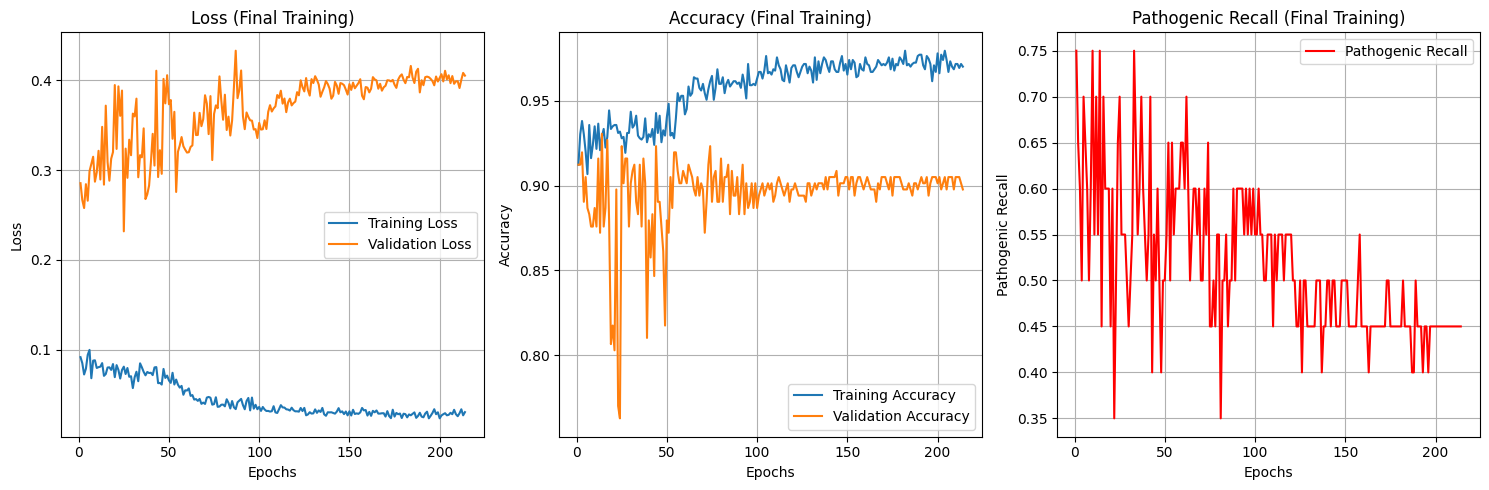


--- Evaluating Final Best Model on Test Set ---


Final Test Evaluation: 100%|██████████| 3/3 [00:00<00:00, 398.32it/s]


FINAL Test Results:
  Test Accuracy: 0.9124
  Pathogenic Recall: 0.8000
  Combined Metric: 0.9924
SUCCESS: Final test accuracy is above 50%!

FINAL Classification Report (Individual Classes):
              precision    recall  f1-score   support

Neg Med (-2)       0.87      1.00      0.93        13
Neg Low (-1)       0.38      0.43      0.40         7
 Pos Low (1)       0.90      0.87      0.89        93
 Pos Med (2)       0.60      0.53      0.56        17
Pos High (3)       0.99      1.00      0.99       144

    accuracy                           0.91       274
   macro avg       0.75      0.77      0.75       274
weighted avg       0.91      0.91      0.91       274


FINAL Confusion Matrix (Individual Classes):


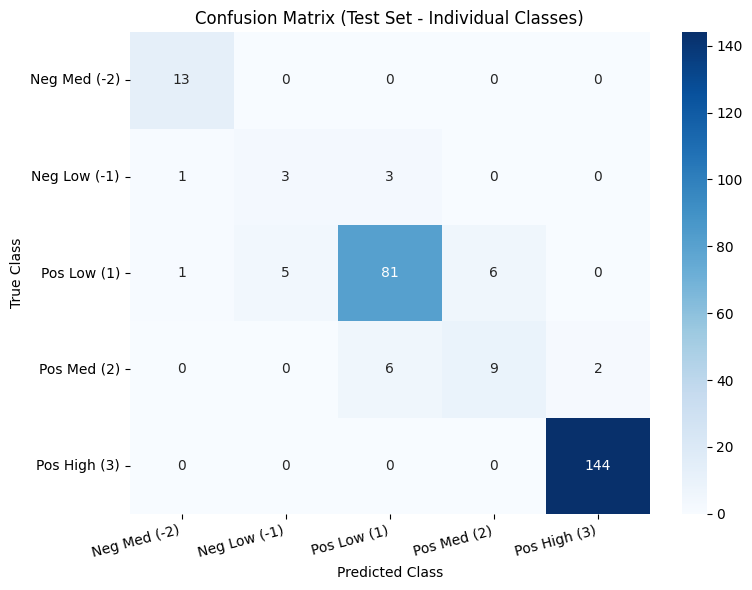


--- Final Group Evaluation ---

Final Grouped Test Accuracy: 0.9599

Final Grouped Classification Report:
                              precision    recall  f1-score   support

        Benign/Likely Benign       0.97      0.93      0.95       110
Pathogenic/Likely Pathogenic       0.74      0.85      0.79        20
                      Others       0.99      1.00      0.99       144

                    accuracy                           0.96       274
                   macro avg       0.90      0.93      0.91       274
                weighted avg       0.96      0.96      0.96       274



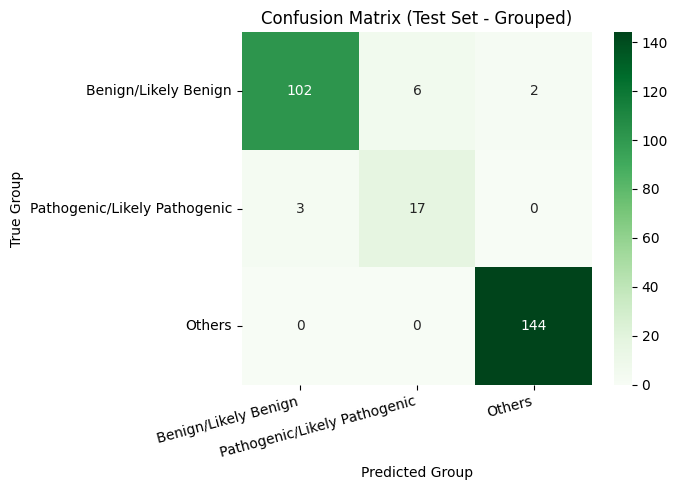


--- End of Fused Embedding Grid Search and Evaluation Script with Pathogenic Emphasis ---


In [187]:
# Cell for Grid Search and Training (Fused DNA-BERT + ESM-2 Embeddings) with Pathogenic Emphasis

# Import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler
import torch.nn.functional as F
import numpy as np
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, recall_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import copy
import time
import gc # Garbage collector

required_vars = ['X_fused', 'y_nn_esm2']
for var in required_vars:
    if var not in locals():
        raise NameError(f"Variable '{var}' not defined. Please ensure fused embeddings are already available.")

if not isinstance(y_nn_esm2, np.ndarray):
    print("Warning: y_nn_esm2 is not a numpy array. Attempting to convert.")
    try:
        y_nn_esm2 = np.array(y_nn_esm2)
    except Exception as e:
        raise TypeError(f"Could not convert y_nn_esm2 to numpy array: {e}")

if X_fused.shape[0] != y_nn_esm2.shape[0]:
    raise ValueError("Mismatch in number of samples between fused embeddings and labels.")

print(f"Using pre-fused data shape: {X_fused.shape}")

# Determine embedding dimensions from fused data (assuming DNA + ESM2)
if 'dna_embedding_dim' not in locals():
    dna_embedding_dim = 768  # Common DNA-BERT dimension
    print(f"Warning: dna_embedding_dim not found, assuming {dna_embedding_dim}")

esm2_embedding_dim = X_fused.shape[1] - dna_embedding_dim
print(f"Inferred dimensions - DNA: {dna_embedding_dim}, ESM2: {esm2_embedding_dim}")

# --- Prepare Data ---
print("\nPreparing data for PyTorch...")
non_zero_indices = y_nn_esm2 != 0
X_filtered = X_fused[non_zero_indices]
y_filtered = y_nn_esm2[non_zero_indices]
print(f"Filtered out {len(y_nn_esm2) - len(y_filtered)} samples with label 0. Remaining: {len(y_filtered)}")
if len(y_filtered) == 0: 
    raise ValueError("No samples remaining after filtering.")

le = LabelEncoder()
y_encoded = le.fit_transform(y_filtered)
num_classes = len(le.classes_)
print(f"Labels encoded into {num_classes} classes.")
class_names_map = {-3: 'Neg High (-3)', -2: 'Neg Med (-2)', -1: 'Neg Low (-1)', 1: 'Pos Low (1)', 2: 'Pos Med (2)', 3: 'Pos High (3)'}
target_names_display = [class_names_map.get(i, f'Unknown({i})') for i in le.classes_]

X_train_val, X_test, y_train_val, y_test = train_test_split(X_filtered, y_encoded, test_size=0.15, random_state=42, stratify=y_encoded)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1765, random_state=42, stratify=y_train_val)
print(f"Data split: Train={len(y_train)}, Val={len(y_val)}, Test={len(y_test)}")

print("\nScaling features SEPARATELY...")
scaler_dna = StandardScaler().fit(X_train[:, :dna_embedding_dim])
scaler_esm2 = StandardScaler().fit(X_train[:, dna_embedding_dim:])

X_train_fused_scaled = np.concatenate((
    scaler_dna.transform(X_train[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_train[:, dna_embedding_dim:])
), axis=1)
X_val_fused_scaled = np.concatenate((
    scaler_dna.transform(X_val[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_val[:, dna_embedding_dim:])
), axis=1)
X_test_fused_scaled = np.concatenate((
    scaler_dna.transform(X_test[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_test[:, dna_embedding_dim:])
), axis=1)
fused_input_dim = X_train_fused_scaled.shape[1]
print(f"Scaled & Fused Input dim: {fused_input_dim}")

X_train_tensor = torch.tensor(X_train_fused_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_val_tensor = torch.tensor(X_val_fused_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_fused_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("\nCalculating class counts...")
class_counts_train = np.bincount(y_train, minlength=num_classes)
print(f"Training set class counts (encoded): {class_counts_train}")

# Create class mapping for pathogenic identification
class_mapping = {encoded_idx: original_class for encoded_idx, original_class in enumerate(le.classes_)}
pathogenic_indices = [encoded_idx for encoded_idx, original_class in class_mapping.items() if original_class in {-2, -1}]
print(f"Pathogenic class indices: {pathogenic_indices}")

use_weights = True  # enable class weighting strategies
eps = 1e-6
class_freq = class_counts_train.astype(np.float32)

# Enhanced class weighting function with pathogenic emphasis
def create_pathogenic_weighted_loss_weights(class_counts, pathogenic_indices, pathogenic_multiplier=3.0):
    """Create class weights with emphasis on pathogenic classes"""
    base_weights = 1.0 / (class_counts.astype(np.float32) + eps)
    base_weights = base_weights / base_weights.sum() * len(base_weights)
    
    # Apply pathogenic multiplier
    enhanced_weights = base_weights.copy()
    for idx in pathogenic_indices:
        enhanced_weights[idx] *= pathogenic_multiplier
    
    return torch.tensor(enhanced_weights, dtype=torch.float32)

# For CrossEntropy weighted loss: inverse-frequency class weights, normalized
loss_weights_base = torch.tensor(1.0 / (class_freq + eps), dtype=torch.float32)
loss_weights_base = loss_weights_base / loss_weights_base.sum() * len(class_freq)

# For WeightedRandomSampler: per-sample weights
sampler_weights_base = torch.tensor(1.0 / (class_freq[y_train] + eps), dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Enhanced Loss Function Implementations
class ClassBalancedLoss(nn.Module):
    def __init__(self, loss_type, samples_per_cls, beta=0.999, gamma=2.0):
        super(ClassBalancedLoss, self).__init__()
        if isinstance(samples_per_cls, np.ndarray): 
            samples_per_cls = torch.from_numpy(samples_per_cls)
        self.samples_per_cls = samples_per_cls.float()
        self.beta = beta
        self.gamma = gamma
        self.num_classes = len(samples_per_cls)
        effective_num = 1.0 - torch.pow(self.beta, self.samples_per_cls)
        weights = (1.0 - self.beta) / (effective_num + 1e-8)
        self.register_buffer('cb_weights', weights / weights.sum() * self.num_classes)
        
        if loss_type == 'CrossEntropy': 
            self.base_loss = nn.CrossEntropyLoss(weight=None, reduction='none')
        elif loss_type == 'Focal': 
            self.base_loss = FocalLoss(alpha=1.0, gamma=self.gamma, reduction='none')
        else: 
            raise ValueError(f"Unsupported loss_type: {loss_type}")
        self.reduction = 'mean'
        
    def forward(self, inputs, targets):
        cb_weights_dev = self.cb_weights.to(inputs.device)
        if isinstance(self.base_loss, nn.CrossEntropyLoss): 
            self.base_loss.weight = cb_weights_dev
        elif isinstance(self.base_loss, FocalLoss): 
            self.base_loss.alpha = cb_weights_dev
        per_sample_loss = self.base_loss(inputs, targets)
        if self.reduction == 'mean': 
            return per_sample_loss.mean()
        elif self.reduction == 'sum': 
            return per_sample_loss.sum()
        else: 
            return per_sample_loss

class FocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0, reduction='mean', weight=None):
        super(FocalLoss, self).__init__()
        self.gamma = gamma
        self.reduction = reduction
        self.alpha = alpha if alpha is not None else 1.0
        self.weight = weight
        
    def forward(self, inputs, targets):
        current_device = inputs.device
        current_ce_weight = self.weight
        if isinstance(current_ce_weight, torch.Tensor): 
            current_ce_weight = current_ce_weight.to(current_device)
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=current_ce_weight)
        pt = torch.exp(-ce_loss)
        alpha_t = self.alpha
        if isinstance(alpha_t, torch.Tensor): 
            alpha_t = alpha_t.to(current_device).gather(0, targets.data.view(-1))
        elif not isinstance(alpha_t, (float, int)): 
            alpha_t = 1.0
        focal_loss = alpha_t * (1 - pt)**self.gamma * ce_loss
        if self.reduction == 'mean': 
            return focal_loss.mean()
        elif self.reduction == 'sum': 
            return focal_loss.sum()
        else: 
            return focal_loss

class PathogenicFocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0, pathogenic_indices=None, pathogenic_weight=3.0):
        super(PathogenicFocalLoss, self).__init__()
        self.gamma = gamma
        self.pathogenic_indices = pathogenic_indices or []
        self.pathogenic_weight = pathogenic_weight
        if isinstance(alpha, torch.Tensor):
            self.alpha = alpha
        else:
            self.alpha = torch.tensor([alpha] * 6, dtype=torch.float32)  # Assuming 6 classes
            
    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        
        # Apply pathogenic weighting
        sample_weights = torch.ones_like(targets, dtype=torch.float32)
        for pathogenic_idx in self.pathogenic_indices:
            pathogenic_mask = (targets == pathogenic_idx)
            sample_weights[pathogenic_mask] = self.pathogenic_weight
        
        focal_loss = self.alpha.to(inputs.device) * (1 - pt)**self.gamma * ce_loss * sample_weights.to(inputs.device)
        return focal_loss.mean()

# Define Simple MLP Architecture
print("\nDefining Simple Neural Network Architecture...")
class SimpleClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dims=[512, 256], output_dim=6, dropout_rate=0.4, activation_fn=nn.ReLU):
        super(SimpleClassifier, self).__init__()
        layers = []
        current_dim = input_dim
        for h_dim in hidden_dims: 
            layers.extend([
                nn.Linear(current_dim, h_dim), 
                nn.BatchNorm1d(h_dim), 
                activation_fn(), 
                nn.Dropout(dropout_rate)
            ])
            current_dim = h_dim
        layers.append(nn.Linear(current_dim, output_dim))
        self.network = nn.Sequential(*layers)
        
    def forward(self, x): 
        return self.network(x)

# Function to calculate pathogenic metrics
def calculate_pathogenic_metrics(y_true, y_pred, pathogenic_indices):
    """Calculate specific metrics for pathogenic classes"""
    if not pathogenic_indices:
        return 0.0, 0.0, 0.0  # No pathogenic classes
    
    # Pathogenic recall
    pathogenic_mask = np.isin(y_true, pathogenic_indices)
    if pathogenic_mask.sum() == 0:
        pathogenic_recall = 0.0
    else:
        pathogenic_true = y_true[pathogenic_mask]
        pathogenic_pred = y_pred[pathogenic_mask]
        pathogenic_recall = np.mean(pathogenic_true == pathogenic_pred)
    
    # Overall accuracy
    overall_accuracy = np.mean(y_true == y_pred)
    
    # Combined metric: accuracy with pathogenic bonus
    combined_metric = overall_accuracy + (0.1 * pathogenic_recall)
    
    return overall_accuracy, pathogenic_recall, combined_metric

# Grid Search Setup for FUSED Data with Pathogenic Emphasis
print("\n--- Setting up Grid Search for FUSED Embeddings with Pathogenic Emphasis ---")
param_grid = {
    'model_type': ['Simple'],
    'lr': [0.0005, 0.001],
    'weight_decay': [0.0, 0.0001],
    'dropout_rate': [0.2, 0.3],
    'optimizer': ['RMSprop'],
    'batch_size': [64],
    'activation_fn': ['ReLU', 'LeakyReLU'],
    'hidden_dims': [
        [2048, 1024, 512, 256]
    ],
    'imbalance_strategy': ['WeightedLossCE', 'PathogenicWeightedCE', 'ClassBalancedCE', 'PathogenicFocalLoss'],
    'cb_beta': [0.999],
    'label_smoothing': [0.0, 0.1],
    'pathogenic_multiplier': [2.0, 3.0, 5.0],  # Pathogenic class emphasis
    'focal_gamma': [1.0, 3.0],
    'focal_alpha': [0.25, 2.0]
}

# Filter grid
print("Filtering parameter grid...")
filtered_grid = []
original_grid = ParameterGrid(param_grid)
total_combinations = len(original_grid)
print(f"Initial grid size: {total_combinations}")

for params in original_grid:
    valid_combo = True
    
    # Skip pathogenic_multiplier for non-pathogenic strategies
    if params['imbalance_strategy'] not in ['PathogenicWeightedCE', 'PathogenicFocalLoss'] and params['pathogenic_multiplier'] != param_grid['pathogenic_multiplier'][0]:
        valid_combo = False
    
    # Skip CB beta for non-CB strategies
    if "ClassBalanced" not in params['imbalance_strategy'] and params['cb_beta'] != param_grid['cb_beta'][0]:
        valid_combo = False
        
    # Skip label smoothing for non-CE strategies
    if "CE" not in params['imbalance_strategy'] and params['label_smoothing'] != param_grid['label_smoothing'][0]:
        valid_combo = False
    
    # Skip focal parameters for non-focal strategies
    if params['imbalance_strategy'] != 'PathogenicFocalLoss':
        if params['focal_gamma'] != param_grid['focal_gamma'][0] or params['focal_alpha'] != param_grid['focal_alpha'][0]:
            valid_combo = False
    
    if valid_combo:
        filtered_grid.append(params)

print(f"Filtered grid size: {len(filtered_grid)} combinations")

# Grid search parameters
grid_search_epochs = 500
grid_search_patience = 100

# Enhanced tracking variables
best_overall_val_acc = 0.0
best_pathogenic_recall = 0.0
best_combined_metric = 0.0
best_overall_params = None
best_overall_model_state = None
best_overall_optimizer_state = None
grid_results = []

device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
input_dim = X_train_tensor.shape[1]
print(f"Fused Input dimension: {input_dim}")

# Grid Search Loop with Pathogenic Emphasis
start_time_grid = time.time()
for i, params in enumerate(filtered_grid):
    print(f"\n--- Grid Search Combination {i+1}/{len(filtered_grid)} ---")
    print(f"Parameters: {params}")
    gc.collect()
    torch.cuda.empty_cache() if device == 'cuda:1' else None

    try:
        # Setup Dataloaders
        current_batch_size = params['batch_size']
        current_imbalance_strategy = params['imbalance_strategy']
        current_train_loader = DataLoader(train_dataset, batch_size=current_batch_size, shuffle=True, num_workers=0)
        current_val_loader = DataLoader(val_dataset, batch_size=current_batch_size * 2, shuffle=False, num_workers=0)

        # Activation
        activation = nn.LeakyReLU if params['activation_fn'] == 'LeakyReLU' else nn.ReLU

        # Model
        nn_model = SimpleClassifier(input_dim, params['hidden_dims'], num_classes, params['dropout_rate'], activation)
        nn_model.to(device)

        # Enhanced Loss Function Selection
        if current_imbalance_strategy == 'PathogenicWeightedCE':
            pathogenic_weights = create_pathogenic_weighted_loss_weights(
                class_counts_train, pathogenic_indices, params['pathogenic_multiplier']
            )
            final_criterion = nn.CrossEntropyLoss(
                weight=pathogenic_weights.to(device), 
                label_smoothing=params.get('label_smoothing', 0.0)
            )
        elif current_imbalance_strategy == 'PathogenicFocalLoss':
            final_criterion = PathogenicFocalLoss(
                alpha=params['focal_alpha'],
                gamma=params['focal_gamma'],
                pathogenic_indices=pathogenic_indices,
                pathogenic_weight=params['pathogenic_multiplier']
            ).to(device)
        elif current_imbalance_strategy == 'ClassBalancedCE':
            if use_weights:
                final_criterion = ClassBalancedLoss(
                    loss_type='CrossEntropy', 
                    samples_per_cls=class_counts_train, 
                    beta=params['cb_beta']
                ).to(device)
            else:
                final_criterion = nn.CrossEntropyLoss()
        else:  # WeightedLossCE
            loss_weights = loss_weights_base.to(device) if use_weights else None
            final_criterion = nn.CrossEntropyLoss(
                weight=loss_weights, 
                label_smoothing=params.get('label_smoothing', 0.0)
            )

        # Optimizer
        optimizer_type = params['optimizer']
        lr = params['lr']
        wd = params['weight_decay']
        if optimizer_type == 'Adam':
            optimizer = optim.Adam(nn_model.parameters(), lr=lr, weight_decay=wd)
        elif optimizer_type == 'RMSprop':
            optimizer = optim.RMSprop(nn_model.parameters(), lr=lr, weight_decay=wd)
        else:
            optimizer = optim.AdamW(nn_model.parameters(), lr=lr, weight_decay=wd)

        # Scheduler
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.2, patience=15)

        # Training Loop with Enhanced Metrics
        current_best_val_acc = 0.0
        current_best_pathogenic_recall = 0.0
        current_best_combined_metric = 0.0
        best_model_state_current = None
        best_optimizer_state_current = None
        epochs_no_improve = 0
        
        for epoch in range(grid_search_epochs):
            nn_model.train()
            running_loss = 0.0
            total_train = 0
            
            for inputs, labels in current_train_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                outputs = nn_model(inputs)
                loss = final_criterion(outputs, labels)
                
                if torch.isnan(loss) or torch.isinf(loss):
                    print(f"NaN/Inf loss")
                    current_best_combined_metric = -1
                    break
                    
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * inputs.size(0)
                total_train += inputs.size(0)
            
            if current_best_combined_metric == -1:
                break
                
            epoch_train_loss = running_loss / total_train if total_train > 0 else 0

            # Validation with enhanced metrics
            nn_model.eval()
            val_predictions = []
            val_true_labels = []
            running_val_loss = 0.0
            total_val = 0
            
            with torch.no_grad():
                for inputs_val, labels_val in current_val_loader:
                    inputs_val, labels_val = inputs_val.to(device), labels_val.to(device)
                    outputs_val = nn_model(inputs_val)
                    loss_val = final_criterion(outputs_val, labels_val)
                    
                    if torch.isnan(loss_val) or torch.isinf(loss_val):
                        current_best_combined_metric = -1
                        break
                        
                    running_val_loss += loss_val.item() * inputs_val.size(0)
                    total_val += labels_val.size(0)
                    
                    _, predicted_val = torch.max(outputs_val.data, 1)
                    val_predictions.extend(predicted_val.cpu().numpy())
                    val_true_labels.extend(labels_val.cpu().numpy())
            
            if current_best_combined_metric == -1:
                break
                
            epoch_val_loss = running_val_loss / total_val if total_val > 0 else 0
            
            # Calculate enhanced metrics
            val_acc, pathogenic_recall, combined_metric = calculate_pathogenic_metrics(
                np.array(val_true_labels), np.array(val_predictions), pathogenic_indices
            )

            if (epoch + 1) % 50 == 0 or epoch == 0 or (epoch + 1) == grid_search_epochs:
                print(f" E{epoch+1} - TrL:{epoch_train_loss:.3f}, VlL:{epoch_val_loss:.3f}, VlA:{val_acc:.4f}, PathR:{pathogenic_recall:.4f}, Comb:{combined_metric:.4f}")
            
            scheduler.step(val_acc)  # Use accuracy for scheduler
            
            # Enhanced model selection: primarily accuracy, with pathogenic recall as tiebreaker
            if combined_metric > current_best_combined_metric:
                current_best_val_acc = val_acc
                current_best_pathogenic_recall = pathogenic_recall
                current_best_combined_metric = combined_metric
                epochs_no_improve = 0
                best_model_state_current = copy.deepcopy(nn_model.state_dict())
                best_optimizer_state_current = copy.deepcopy(optimizer.state_dict())
            else:
                epochs_no_improve += 1
                
            if epochs_no_improve >= grid_search_patience:
                print(f" EStop@{epoch+1}")
                break

        if current_best_combined_metric <= 0:
            current_best_val_acc = 0.0
            current_best_pathogenic_recall = 0.0
            current_best_combined_metric = 0.0
            
        print(f"Combo {i+1} - Val Acc: {current_best_val_acc:.4f}, Pathogenic Recall: {current_best_pathogenic_recall:.4f}, Combined: {current_best_combined_metric:.4f}")
        
        grid_results.append({
            'params': params, 
            'best_val_acc': current_best_val_acc, 
            'pathogenic_recall': current_best_pathogenic_recall,
            'combined_metric': current_best_combined_metric,
            'epochs_run': epoch + 1
        })
        
        # Enhanced best model selection
        if current_best_combined_metric > best_combined_metric:
            print(f"!!! New Best Overall: Acc={current_best_val_acc:.4f}, PathR={current_best_pathogenic_recall:.4f}, Combined={current_best_combined_metric:.4f} !!!")
            best_overall_val_acc = current_best_val_acc
            best_pathogenic_recall = current_best_pathogenic_recall
            best_combined_metric = current_best_combined_metric
            best_overall_params = params
            best_overall_model_state = best_model_state_current
            best_overall_optimizer_state = best_optimizer_state_current

    except Exception as e:
        print(f"ERROR processing Combination {i+1}: {e}")
        grid_results.append({
            'params': params, 
            'best_val_acc': 0.0, 
            'pathogenic_recall': 0.0,
            'combined_metric': 0.0,
            'epochs_run': 0, 
            'error': str(e)
        })

# End Grid Search
end_time_grid = time.time()
print(f"\n--- Fused Grid Search Complete ---")
print(f"Time: {(end_time_grid - start_time_grid)/60:.2f} min")

# Sort by combined metric (accuracy + pathogenic recall bonus)
grid_results.sort(key=lambda x: x['combined_metric'], reverse=True)

print("\nTop 10 Fused Grid Search Results (Combined Metric):")
for res in grid_results[:10]:
    print(f"  Combined: {res['combined_metric']:.4f} | Acc: {res['best_val_acc']:.4f} | PathR: {res['pathogenic_recall']:.4f} | Ep: {res['epochs_run']}")
    print(f"    Params: {res['params']}")

if best_overall_params is None or best_overall_val_acc <= 0:
    raise SystemExit("Error: Fused Grid search failed.")

print(f"\nBest hyperparameters found: {best_overall_params}")
print(f"Best validation accuracy: {best_overall_val_acc:.4f}")
print(f"Best pathogenic recall: {best_pathogenic_recall:.4f}")
print(f"Best combined metric: {best_combined_metric:.4f}")

if best_overall_val_acc > 0.50:
    print("Convergence Goal (>50%) MET!")
else:
    print("WARNING: Convergence Goal (>50%) NOT MET.")

# --- Retrain Best Fused Model Fully ---
print("\n--- Retraining Best Fused Model Configuration Fully ---")
final_best_params = best_overall_params

# Instantiate Activation
final_activation = nn.LeakyReLU if final_best_params['activation_fn'] == 'LeakyReLU' else nn.ReLU

# Instantiate Model
final_model = SimpleClassifier(input_dim, final_best_params['hidden_dims'], num_classes, final_best_params['dropout_rate'], final_activation)

# Load Best Model State
if best_overall_model_state:
    print("Loading best model state found during grid search...")
    final_model.load_state_dict(best_overall_model_state)
else:
    print("Warning: No best model state saved from grid search!")
    exit()
final_model.to(device)

# Define Final Loss Function (matching best strategy)
final_imbalance_strategy = final_best_params['imbalance_strategy']
if final_imbalance_strategy == 'PathogenicWeightedCE':
    pathogenic_weights = create_pathogenic_weighted_loss_weights(
        class_counts_train, pathogenic_indices, final_best_params['pathogenic_multiplier']
    )
    final_criterion = nn.CrossEntropyLoss(
        weight=pathogenic_weights.to(device), 
        label_smoothing=final_best_params['label_smoothing']
    )
elif final_imbalance_strategy == 'PathogenicFocalLoss':
    final_criterion = PathogenicFocalLoss(
        alpha=final_best_params['focal_alpha'],
        gamma=final_best_params['focal_gamma'],
        pathogenic_indices=pathogenic_indices,
        pathogenic_weight=final_best_params['pathogenic_multiplier']
    ).to(device)
elif final_imbalance_strategy == 'ClassBalancedCE':
    if use_weights:
        final_criterion = ClassBalancedLoss(
            loss_type='CrossEntropy', 
            samples_per_cls=class_counts_train, 
            beta=final_best_params['cb_beta']
        ).to(device)
    else:
        final_criterion = nn.CrossEntropyLoss()
else:  # WeightedLossCE
    final_ce_weights = loss_weights_base.to(device) if use_weights else None
    final_criterion = nn.CrossEntropyLoss(
        weight=final_ce_weights, 
        label_smoothing=final_best_params['label_smoothing']
    )
print(f"Using final loss strategy: {final_imbalance_strategy}")

# Define Final Optimizer
final_lr_retrain = final_best_params['lr']
print(f"Using Final Retraining LR: {final_lr_retrain}")
final_wd = final_best_params['weight_decay']
final_optimizer_type = final_best_params['optimizer']
if final_optimizer_type == 'Adam':
    final_optimizer = optim.Adam(final_model.parameters(), lr=final_lr_retrain, weight_decay=final_wd)
elif final_optimizer_type == 'RMSprop':
    final_optimizer = optim.RMSprop(final_model.parameters(), lr=final_lr_retrain, weight_decay=final_wd)
else:
    final_optimizer = optim.AdamW(final_model.parameters(), lr=final_lr_retrain, weight_decay=final_wd)
print(f"Using Optimizer: {final_optimizer_type}")

# Load Optimizer State
if best_overall_optimizer_state:
    print("Loading best optimizer state found during grid search...")
    final_optimizer.load_state_dict(best_overall_optimizer_state)
    print("Optimizer state loaded.")
else:
    print("Warning: No optimizer state saved from grid search. Starting optimizer from scratch.")

# Scheduler
final_scheduler = optim.lr_scheduler.ReduceLROnPlateau(final_optimizer, mode='max', factor=0.2, patience=40)

# Create final data loaders
train_loader = DataLoader(train_dataset, batch_size=final_best_params['batch_size'], shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=final_best_params['batch_size'] * 2, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=final_best_params['batch_size'] * 2, shuffle=False, num_workers=0)

# Final Training Loop
final_num_epochs = 500
final_patience_early_stopping = 200
final_epochs_no_improve = 0
final_best_val_acc = 0.0
final_best_pathogenic_recall = 0.0
final_best_combined_metric = 0.0
final_best_model_state_retrain = None
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'pathogenic_recall': []}
print(f"Starting final training for up to {final_num_epochs} epochs...")
start_time_final = time.time()

# Get initial validation metrics with loaded model state
final_model.eval()
val_predictions = []
val_true_labels = []
with torch.no_grad():
    for inputs_val, labels_val in val_loader:
        inputs_val, labels_val = inputs_val.to(device), labels_val.to(device)
        outputs_val = final_model(inputs_val)
        _, predicted_val = torch.max(outputs_val.data, 1)
        val_predictions.extend(predicted_val.cpu().numpy())
        val_true_labels.extend(labels_val.cpu().numpy())

initial_val_acc, initial_pathogenic_recall, initial_combined = calculate_pathogenic_metrics(
    np.array(val_true_labels), np.array(val_predictions), pathogenic_indices
)
final_best_val_acc = initial_val_acc
final_best_pathogenic_recall = initial_pathogenic_recall
final_best_combined_metric = initial_combined
final_best_model_state_retrain = copy.deepcopy(final_model.state_dict())
print(f"Initial Metrics - Acc: {initial_val_acc:.4f}, PathR: {initial_pathogenic_recall:.4f}, Combined: {initial_combined:.4f}")

for epoch in range(final_num_epochs):
    final_model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    progress_bar_final = tqdm(train_loader, desc=f"Retrain Epoch {epoch+1}/{final_num_epochs}", leave=False)
    for inputs, labels in progress_bar_final:
        inputs, labels = inputs.to(device), labels.to(device)
        final_optimizer.zero_grad()
        outputs = final_model(inputs)
        loss = final_criterion(outputs, labels)
        
        if torch.isnan(loss) or torch.isinf(loss):
            print(f"NaN/Inf loss")
            final_best_combined_metric = -1
            break
            
        loss.backward()
        final_optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        progress_bar_final.set_postfix({'loss': loss.item(), 'lr': final_optimizer.param_groups[0]['lr']})
    
    if final_best_combined_metric <= -1:
        break
        
    epoch_train_loss = running_loss / total_train if total_train > 0 else 0
    epoch_train_acc = correct_train / total_train if total_train > 0 else 0
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)

    # Validation with enhanced metrics
    final_model.eval()
    val_predictions = []
    val_true_labels = []
    running_val_loss = 0.0
    total_val = 0
    
    with torch.no_grad():
        for inputs_val, labels_val in val_loader:
            inputs_val, labels_val = inputs_val.to(device), labels_val.to(device)
            outputs_val = final_model(inputs_val)
            loss_val = final_criterion(outputs_val, labels_val)
            
            if torch.isnan(loss_val) or torch.isinf(loss_val):
                final_best_combined_metric = -1
                break
                
            running_val_loss += loss_val.item() * inputs_val.size(0)
            total_val += labels_val.size(0)
            _, predicted_val = torch.max(outputs_val.data, 1)
            val_predictions.extend(predicted_val.cpu().numpy())
            val_true_labels.extend(labels_val.cpu().numpy())
    
    if final_best_combined_metric <= -1:
        break
        
    epoch_val_loss = running_val_loss / total_val if total_val > 0 else 0
    epoch_val_acc, epoch_pathogenic_recall, epoch_combined = calculate_pathogenic_metrics(
        np.array(val_true_labels), np.array(val_predictions), pathogenic_indices
    )
    
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)
    history['pathogenic_recall'].append(epoch_pathogenic_recall)

    print(f" Ep {epoch+1} - TrL:{epoch_train_loss:.4f}, TrA:{epoch_train_acc:.4f} | VlL:{epoch_val_loss:.4f}, VlA:{epoch_val_acc:.4f}, PathR:{epoch_pathogenic_recall:.4f}, Comb:{epoch_combined:.4f}")
    final_scheduler.step(epoch_val_acc)

    # Early Stopping based on combined metric
    if epoch_combined > final_best_combined_metric:
        print(f"  -> Combined metric improved ({final_best_combined_metric:.4f} --> {epoch_combined:.4f})")
        final_best_val_acc = epoch_val_acc
        final_best_pathogenic_recall = epoch_pathogenic_recall
        final_best_combined_metric = epoch_combined
        final_epochs_no_improve = 0
        final_best_model_state_retrain = copy.deepcopy(final_model.state_dict())
    else:
        final_epochs_no_improve += 1
        
    if final_epochs_no_improve >= final_patience_early_stopping:
        print(f"  Early stopping @ epoch {epoch + 1}")
        break

# End Final Training Loop
end_time_final = time.time()
print(f"\n--- Final Training Complete ---")
print(f"Time: {(end_time_final - start_time_final)/60:.2f} min")

if final_best_model_state_retrain:
    print(f"Loading best model state from RETRAINING - Acc: {final_best_val_acc:.4f}, PathR: {final_best_pathogenic_recall:.4f}, Combined: {final_best_combined_metric:.4f}")
    final_model.load_state_dict(final_best_model_state_retrain)
elif best_overall_model_state:
    print(f"WARNING: Retraining did not improve. Loading best state from GRID SEARCH - Acc: {best_overall_val_acc:.4f}")
    final_model.load_state_dict(best_overall_model_state)
else:
    raise SystemExit("ERROR: No valid model state found after training. Cannot evaluate.")

# Plot Final Training Curves
print("\nPlotting final training curves...")
epochs_ran = range(1, len(history['train_loss']) + 1)
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.plot(epochs_ran, history['train_loss'], label='Training Loss')
plt.plot(epochs_ran, history['val_loss'], label='Validation Loss')
plt.title('Loss (Final Training)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(epochs_ran, history['train_acc'], label='Training Accuracy')
plt.plot(epochs_ran, history['val_acc'], label='Validation Accuracy')
plt.title('Accuracy (Final Training)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(epochs_ran, history['pathogenic_recall'], label='Pathogenic Recall', color='red')
plt.title('Pathogenic Recall (Final Training)')
plt.xlabel('Epochs')
plt.ylabel('Pathogenic Recall')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Final Evaluation on Test Set with Enhanced Metrics
print("\n--- Evaluating Final Best Model on Test Set ---")
final_model.eval()
y_pred_list = []
y_true_list = []

with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Final Test Evaluation"):
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = final_model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        y_pred_list.extend(predicted.cpu().numpy())
        y_true_list.extend(labels.cpu().numpy())

y_pred_final = np.array(y_pred_list)
y_test_final = np.array(y_true_list)

# Calculate final test metrics
test_accuracy, test_pathogenic_recall, test_combined = calculate_pathogenic_metrics(
    y_test_final, y_pred_final, pathogenic_indices
)

print(f"\nFINAL Test Results:")
print(f"  Test Accuracy: {test_accuracy:.4f}")
print(f"  Pathogenic Recall: {test_pathogenic_recall:.4f}")
print(f"  Combined Metric: {test_combined:.4f}")

if test_accuracy > 0.50:
    print("SUCCESS: Final test accuracy is above 50%!")
else:
    print("NOTE: Final test accuracy did not exceed 50%.")

print("\nFINAL Classification Report (Individual Classes):")
eval_labels = np.arange(num_classes)
eval_target_names = target_names_display
print(classification_report(y_test_final, y_pred_final, labels=eval_labels, target_names=eval_target_names, zero_division=0))

print("\nFINAL Confusion Matrix (Individual Classes):")
cm_final = confusion_matrix(y_test_final, y_pred_final, labels=eval_labels)
try:
    import seaborn as sns
    sns_available_final = True
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', xticklabels=eval_target_names, yticklabels=eval_target_names)
    plt.xlabel('Predicted Class')
    plt.ylabel('True Class')
    plt.title('Confusion Matrix (Test Set - Individual Classes)')
    plt.xticks(rotation=15, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
except ImportError:
    sns_available_final = False
    print("Seaborn not installed.")
    print(pd.DataFrame(cm_final, index=eval_target_names, columns=eval_target_names) if 'pd' in locals() else cm_final)

print("\n--- Final Group Evaluation ---")
try:
    group_mapping = {}
    benign_labels = {1, 2}
    pathogenic_labels = {-1, -2}
    for encoded_idx, original_class in enumerate(le.classes_):
        if original_class in benign_labels:
            group_mapping[encoded_idx] = 0
        elif original_class in pathogenic_labels:
            group_mapping[encoded_idx] = 1
        else:
            group_mapping[encoded_idx] = 2
    
    group_names = ['Benign/Likely Benign', 'Pathogenic/Likely Pathogenic', 'Others']
    y_true_grouped_final = np.array([group_mapping[label] for label in y_test_final])
    y_pred_grouped_final = np.array([group_mapping[pred] for pred in y_pred_final])
    unique_groups_final = sorted(list(set(y_true_grouped_final) | set(y_pred_grouped_final)))
    target_names_grouped = [group_names[g] for g in unique_groups_final if g < len(group_names)]
    
    if len(target_names_grouped) != len(unique_groups_final):
        print("Warning: Mismatch between unique groups and group names!")
    
    accuracy_grouped = accuracy_score(y_true_grouped_final, y_pred_grouped_final)
    print(f"\nFinal Grouped Test Accuracy: {accuracy_grouped:.4f}")
    print("\nFinal Grouped Classification Report:")
    print(classification_report(y_true_grouped_final, y_pred_grouped_final, labels=unique_groups_final, target_names=target_names_grouped, zero_division=0))
    
    cm_grouped_final = confusion_matrix(y_true_grouped_final, y_pred_grouped_final, labels=unique_groups_final)
    if sns_available_final:
        plt.figure(figsize=(7, 5))
        sns.heatmap(cm_grouped_final, annot=True, fmt='d', cmap='Greens', xticklabels=target_names_grouped, yticklabels=target_names_grouped)
        plt.xlabel('Predicted Group')
        plt.ylabel('True Group')
        plt.title('Confusion Matrix (Test Set - Grouped)')
        plt.xticks(rotation=15, ha='right')
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.show()
    else:
        print("\nGrouped Confusion Matrix:\n", pd.DataFrame(cm_grouped_final, index=target_names_grouped, columns=target_names_grouped) if 'pd' in locals() else cm_grouped_final)
        
except Exception as e:
    print(f"Error during grouped evaluation: {e}")

print("\n--- End of Fused Embedding Grid Search and Evaluation Script with Pathogenic Emphasis ---")

### Model of THe Grid SEarch (high recal)

🎯 TRAINING FINAL MODEL WITH BEST HYPERPARAMETERS
📋 Using Best Parameters:
   activation_fn: LeakyReLU
   batch_size: 64
   cb_beta: 0.999
   dropout_rate: 0.2
   focal_alpha: 0.25
   focal_gamma: 1.0
   hidden_dims: [2048, 1024, 512, 256]
   imbalance_strategy: ClassBalancedCE
   label_smoothing: 0.1
   lr: 0.0005
   model_type: Simple
   optimizer: RMSprop
   pathogenic_multiplier: 2.0
   weight_decay: 0.0001

📊 Data Info:
   Input shape: (2333, 6471)
   Labels shape: (2333,)
   ESM2 embedding dim: 5703
   Filtered samples: 1826 (removed 507 zero labels)
   Number of classes: 5
   Class labels: [-2 -1  1  2  3]
   Pathogenic class indices: [0, 1]
   Benign class indices: [2, 3]
   Train: 1278, Val: 274, Test: 274
   Training class distribution: [ 59  34 432  79 674]

🏗️  Building Model with Best Architecture...
   Using device: cuda:1
   Model architecture: 6471 -> 2048 -> 1024 -> 512 -> 256 -> 5
   Total parameters: 16,017,925
   Loss function: ClassBalancedLoss (beta=0.999)
   Optim

Epoch   1 | TrL: 0.5211 | TrA: 0.2746 | VlL: 0.4778 | VlA: 0.4124 | PathR: 0.4500 | BenR: 0.4091 | Comb: 0.4574
   ✅ New best combined metric: 0.4574


   ✅ New best combined metric: 0.6760


   ✅ New best combined metric: 0.8118


Epoch  10 | TrL: 0.3446 | TrA: 0.6573 | VlL: 0.4918 | VlA: 0.3285 | PathR: 0.3000 | BenR: 0.5091 | Comb: 0.3585


...

Epoch 140 | TrL: 0.0437 | TrA: 0.9577 | VlL: 0.2624 | VlA: 0.8942 | PathR: 0.6500 | BenR: 0.8000 | Comb: 0.9592


Epoch 00145: reducing learning rate of group 0 to 8.0000e-07.


Epoch 150 | TrL: 0.0509 | TrA: 0.9531 | VlL: 0.2672 | VlA: 0.8942 | PathR: 0.6500 | BenR: 0.8000 | Comb: 0.9592


Epoch 160 | TrL: 0.0421 | TrA: 0.9601 | VlL: 0.2713 | VlA: 0.8978 | PathR: 0.6500 | BenR: 0.8091 | Comb: 0.9628


   ⏹️  Early stopping at epoch 167

✅ Training completed in 0.34 minutes
   Best combined metric: 1.0020
   Loaded best model state

📊 Plotting training curves...


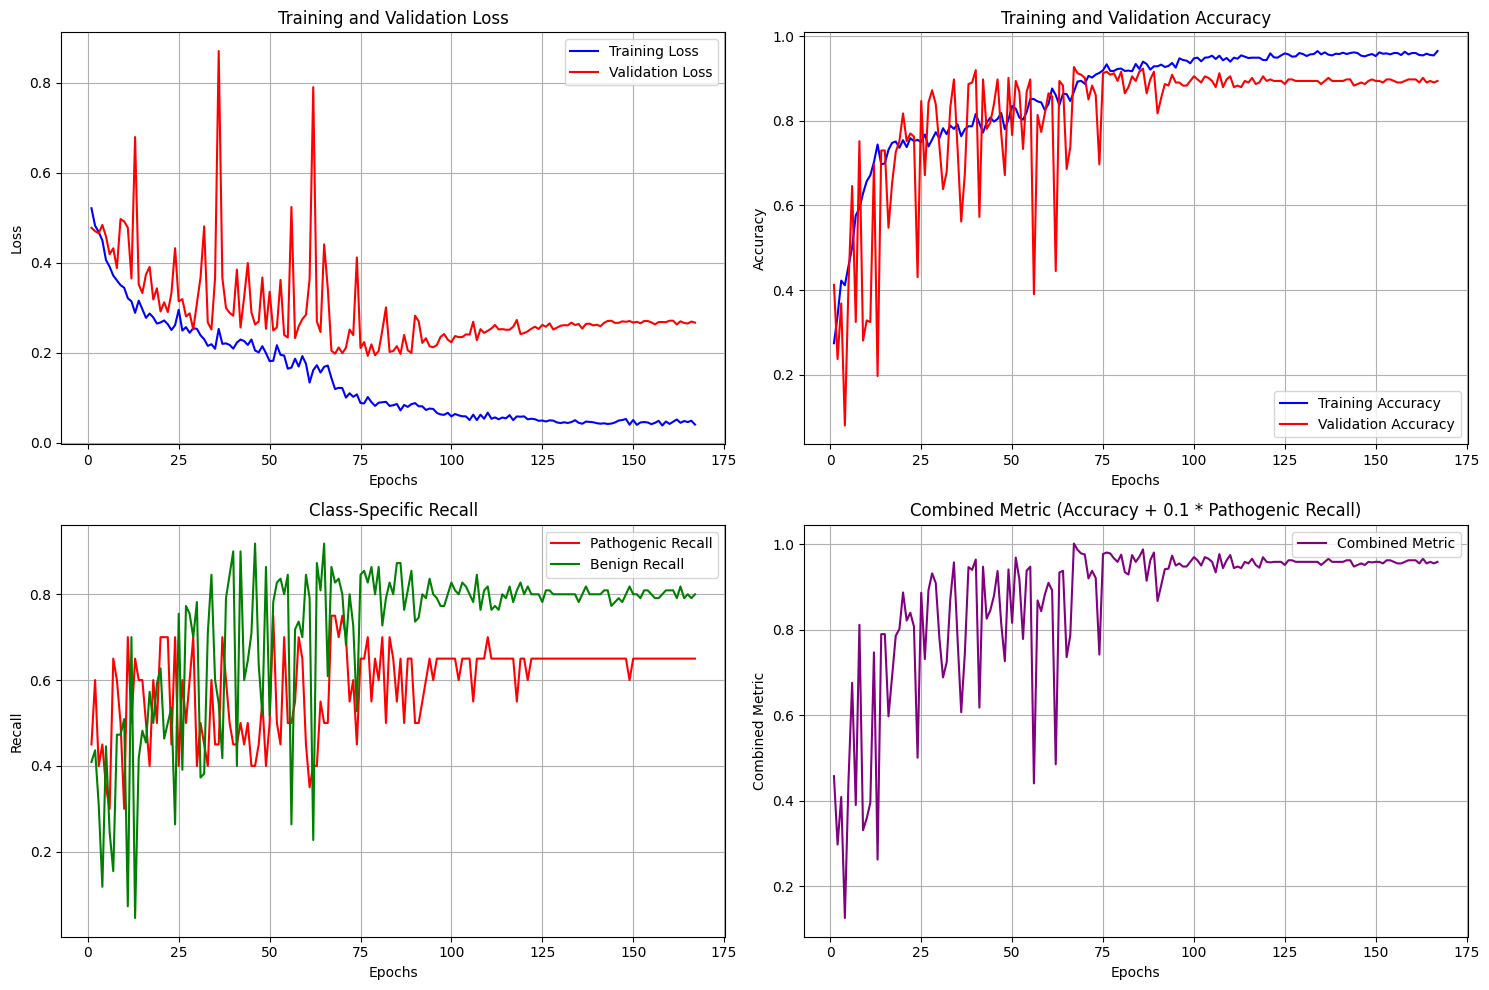


🧪 Final Test Evaluation...


Testing: 100%|██████████| 3/3 [00:00<00:00, 692.24it/s]


🎯 FINAL TEST RESULTS:
   Overall Accuracy: 0.9234 (92.34%)
   Pathogenic Recall: 0.8000 (80.00%)
   Benign Recall: 0.8455 (84.55%)
   Combined Metric: 1.0034

📋 Detailed Classification Report:
              precision    recall  f1-score   support

    Class -2       0.87      1.00      0.93        13
    Class -1       0.43      0.43      0.43         7
     Class 1       0.91      0.88      0.90        93
     Class 2       0.65      0.65      0.65        17
     Class 3       0.99      1.00      1.00       144

    accuracy                           0.92       274
   macro avg       0.77      0.79      0.78       274
weighted avg       0.92      0.92      0.92       274


📊 Confusion Matrix:
[[ 13   0   0   0   0]
 [  1   3   3   0   0]
 [  1   4  82   6   0]
 [  0   0   5  11   1]
 [  0   0   0   0 144]]

🏥 Grouped Analysis (Benign vs Pathogenic vs Others):
   Grouped Accuracy: 0.9672 (96.72%)

   Grouped Classification Report:
                              precision    recall  f1-

In [45]:
# Cell: Train Final Model with Best Hyperparameters from Grid Search
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torch.nn.functional as F
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import copy
import time

print("🎯 TRAINING FINAL MODEL WITH BEST HYPERPARAMETERS")
print("="*60)

# Best hyperparameters from grid search
best_params = {
    'activation_fn': 'LeakyReLU',
    'batch_size': 64,
    'cb_beta': 0.999,
    'dropout_rate': 0.2,
    'focal_alpha': 0.25,
    'focal_gamma': 1.0,
    'hidden_dims': [2048, 1024, 512, 256],
    'imbalance_strategy': 'ClassBalancedCE',
    'label_smoothing': 0.1,
    'lr': 0.0005,
    'model_type': 'Simple',
    'optimizer': 'RMSprop',
    'pathogenic_multiplier': 2.0,
    'weight_decay': 0.0001
}

print(f"📋 Using Best Parameters:")
for key, value in best_params.items():
    print(f"   {key}: {value}")

# Verify required data
required_vars = ['X_fused', 'y_nn_esm2']
for var in required_vars:
    if var not in locals():
        raise NameError(f"Variable '{var}' not defined. Please ensure fused embeddings are available.")

print(f"\n📊 Data Info:")
print(f"   Input shape: {X_fused.shape}")
print(f"   Labels shape: {y_nn_esm2.shape}")

# Data preparation
if 'dna_embedding_dim' not in locals():
    dna_embedding_dim = 768
    print(f"   DNA embedding dim: {dna_embedding_dim} (assumed)")

esm2_embedding_dim = X_fused.shape[1] - dna_embedding_dim
print(f"   ESM2 embedding dim: {esm2_embedding_dim}")

# Filter and encode data
non_zero_indices = y_nn_esm2 != 0
X_filtered = X_fused[non_zero_indices]
y_filtered = y_nn_esm2[non_zero_indices]
print(f"   Filtered samples: {len(y_filtered)} (removed {len(y_nn_esm2) - len(y_filtered)} zero labels)")

le = LabelEncoder()
y_encoded = le.fit_transform(y_filtered)
num_classes = len(le.classes_)
print(f"   Number of classes: {num_classes}")
print(f"   Class labels: {le.classes_}")

# Create class mapping for pathogenic identification
class_mapping = {encoded_idx: original_class for encoded_idx, original_class in enumerate(le.classes_)}
pathogenic_indices = [encoded_idx for encoded_idx, original_class in class_mapping.items() if original_class in {-2, -1}]
benign_indices = [encoded_idx for encoded_idx, original_class in class_mapping.items() if original_class in {1, 2}]
print(f"   Pathogenic class indices: {pathogenic_indices}")
print(f"   Benign class indices: {benign_indices}")

# Split data
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_filtered, y_encoded, test_size=0.15, random_state=42, stratify=y_encoded
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1765, random_state=42, stratify=y_train_val
)
print(f"   Train: {len(y_train)}, Val: {len(y_val)}, Test: {len(y_test)}")

# Scale features
scaler_dna = StandardScaler().fit(X_train[:, :dna_embedding_dim])
scaler_esm2 = StandardScaler().fit(X_train[:, dna_embedding_dim:])

X_train_scaled = np.concatenate((
    scaler_dna.transform(X_train[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_train[:, dna_embedding_dim:])
), axis=1)
X_val_scaled = np.concatenate((
    scaler_dna.transform(X_val[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_val[:, dna_embedding_dim:])
), axis=1)
X_test_scaled = np.concatenate((
    scaler_dna.transform(X_test[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_test[:, dna_embedding_dim:])
), axis=1)

# Convert to tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# Create datasets and data loaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=best_params['batch_size'], shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=best_params['batch_size'] * 2, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=best_params['batch_size'] * 2, shuffle=False, num_workers=0)

# Class counts for loss weighting
class_counts_train = np.bincount(y_train, minlength=num_classes)
print(f"   Training class distribution: {class_counts_train}")

# Define loss functions
class ClassBalancedLoss(nn.Module):
    def __init__(self, loss_type, samples_per_cls, beta=0.999, gamma=2.0):
        super(ClassBalancedLoss, self).__init__()
        if isinstance(samples_per_cls, np.ndarray): 
            samples_per_cls = torch.from_numpy(samples_per_cls)
        self.samples_per_cls = samples_per_cls.float()
        self.beta = beta
        self.gamma = gamma
        self.num_classes = len(samples_per_cls)
        effective_num = 1.0 - torch.pow(self.beta, self.samples_per_cls)
        weights = (1.0 - self.beta) / (effective_num + 1e-8)
        self.register_buffer('cb_weights', weights / weights.sum() * self.num_classes)
        
        if loss_type == 'CrossEntropy': 
            self.base_loss = nn.CrossEntropyLoss(weight=None, reduction='none')
        self.reduction = 'mean'
        
    def forward(self, inputs, targets):
        cb_weights_dev = self.cb_weights.to(inputs.device)
        self.base_loss.weight = cb_weights_dev
        per_sample_loss = self.base_loss(inputs, targets)
        return per_sample_loss.mean()

# Define model architecture
class SimpleClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dims, output_dim, dropout_rate, activation_fn):
        super(SimpleClassifier, self).__init__()
        layers = []
        current_dim = input_dim
        for h_dim in hidden_dims: 
            layers.extend([
                nn.Linear(current_dim, h_dim), 
                nn.BatchNorm1d(h_dim), 
                activation_fn(), 
                nn.Dropout(dropout_rate)
            ])
            current_dim = h_dim
        layers.append(nn.Linear(current_dim, output_dim))
        self.network = nn.Sequential(*layers)
        
    def forward(self, x): 
        return self.network(x)

# Metrics calculation function
def calculate_detailed_metrics(y_true, y_pred, pathogenic_indices, benign_indices):
    """Calculate comprehensive metrics including pathogenic-specific ones"""
    overall_accuracy = np.mean(y_true == y_pred)
    
    # Pathogenic metrics
    pathogenic_mask = np.isin(y_true, pathogenic_indices)
    if pathogenic_mask.sum() > 0:
        pathogenic_true = y_true[pathogenic_mask]
        pathogenic_pred = y_pred[pathogenic_mask]
        pathogenic_recall = np.mean(pathogenic_true == pathogenic_pred)
    else:
        pathogenic_recall = 0.0
    
    # Benign metrics
    benign_mask = np.isin(y_true, benign_indices)
    if benign_mask.sum() > 0:
        benign_true = y_true[benign_mask]
        benign_pred = y_pred[benign_mask]
        benign_recall = np.mean(benign_true == benign_pred)
    else:
        benign_recall = 0.0
    
    # Combined metric
    combined_metric = overall_accuracy + (0.1 * pathogenic_recall)
    
    return overall_accuracy, pathogenic_recall, benign_recall, combined_metric

print(f"\n🏗️  Building Model with Best Architecture...")

# Set device
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
print(f"   Using device: {device}")

# Initialize model
activation_fn = nn.LeakyReLU if best_params['activation_fn'] == 'LeakyReLU' else nn.ReLU
input_dim = X_train_tensor.shape[1]

model = SimpleClassifier(
    input_dim=input_dim,
    hidden_dims=best_params['hidden_dims'],
    output_dim=num_classes,
    dropout_rate=best_params['dropout_rate'],
    activation_fn=activation_fn
)
model.to(device)

print(f"   Model architecture: {input_dim} -> {' -> '.join(map(str, best_params['hidden_dims']))} -> {num_classes}")
print(f"   Total parameters: {sum(p.numel() for p in model.parameters()):,}")

# Initialize loss function
criterion = ClassBalancedLoss(
    loss_type='CrossEntropy',
    samples_per_cls=class_counts_train,
    beta=best_params['cb_beta']
).to(device)

# Initialize optimizer
optimizer = optim.RMSprop(
    model.parameters(),
    lr=best_params['lr'],
    weight_decay=best_params['weight_decay']
)

# Initialize scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.2, patience=25, verbose=True
)

print(f"   Loss function: ClassBalancedLoss (beta={best_params['cb_beta']})")
print(f"   Optimizer: RMSprop (lr={best_params['lr']}, wd={best_params['weight_decay']})")

# Training parameters
num_epochs = 300
patience = 100
best_val_combined = 0.0
best_model_state = None
epochs_no_improve = 0

# Training history
history = {
    'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [],
    'pathogenic_recall': [], 'benign_recall': [], 'combined_metric': []
}

print(f"\n🚀 Starting Training for {num_epochs} epochs...")
print(f"   Early stopping patience: {patience}")
start_time = time.time()

for epoch in range(num_epochs):
    # Training phase
    model.train()
    train_loss = 0.0
    correct_train = 0
    total_train = 0
    
    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}", leave=False)
    for inputs, labels in train_pbar:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        if torch.isnan(loss) or torch.isinf(loss):
            print(f"❌ NaN/Inf loss detected at epoch {epoch+1}")
            break
            
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
        train_pbar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'acc': f'{100 * correct_train / total_train:.2f}%',
            'lr': f'{optimizer.param_groups[0]["lr"]:.2e}'
        })
    
    epoch_train_loss = train_loss / total_train
    epoch_train_acc = correct_train / total_train
    
    # Validation phase
    model.eval()
    val_loss = 0.0
    val_predictions = []
    val_true_labels = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_predictions.extend(predicted.cpu().numpy())
            val_true_labels.extend(labels.cpu().numpy())
    
    epoch_val_loss = val_loss / len(val_dataset)
    val_acc, pathogenic_recall, benign_recall, combined_metric = calculate_detailed_metrics(
        np.array(val_true_labels), np.array(val_predictions), pathogenic_indices, benign_indices
    )
    
    # Update history
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(val_acc)
    history['pathogenic_recall'].append(pathogenic_recall)
    history['benign_recall'].append(benign_recall)
    history['combined_metric'].append(combined_metric)
    
    # Scheduler step
    scheduler.step(val_acc)
    
    # Print progress
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:3d} | "
              f"TrL: {epoch_train_loss:.4f} | TrA: {epoch_train_acc:.4f} | "
              f"VlL: {epoch_val_loss:.4f} | VlA: {val_acc:.4f} | "
              f"PathR: {pathogenic_recall:.4f} | BenR: {benign_recall:.4f} | "
              f"Comb: {combined_metric:.4f}")
    
    # Early stopping and best model saving
    if combined_metric > best_val_combined:
        best_val_combined = combined_metric
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
        print(f"   ✅ New best combined metric: {combined_metric:.4f}")
    else:
        epochs_no_improve += 1
    
    if epochs_no_improve >= patience:
        print(f"   ⏹️  Early stopping at epoch {epoch+1}")
        break

end_time = time.time()
training_time = (end_time - start_time) / 60
print(f"\n✅ Training completed in {training_time:.2f} minutes")
print(f"   Best combined metric: {best_val_combined:.4f}")

# Load best model
if best_model_state:
    model.load_state_dict(best_model_state)
    print("   Loaded best model state")

# Plot training curves
print("\n📊 Plotting training curves...")
epochs_range = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Loss plot
axes[0, 0].plot(epochs_range, history['train_loss'], 'b-', label='Training Loss')
axes[0, 0].plot(epochs_range, history['val_loss'], 'r-', label='Validation Loss')
axes[0, 0].set_title('Training and Validation Loss')
axes[0, 0].set_xlabel('Epochs')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True)

# Accuracy plot
axes[0, 1].plot(epochs_range, history['train_acc'], 'b-', label='Training Accuracy')
axes[0, 1].plot(epochs_range, history['val_acc'], 'r-', label='Validation Accuracy')
axes[0, 1].set_title('Training and Validation Accuracy')
axes[0, 1].set_xlabel('Epochs')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True)

# Class-specific recalls
axes[1, 0].plot(epochs_range, history['pathogenic_recall'], 'r-', label='Pathogenic Recall')
axes[1, 0].plot(epochs_range, history['benign_recall'], 'g-', label='Benign Recall')
axes[1, 0].set_title('Class-Specific Recall')
axes[1, 0].set_xlabel('Epochs')
axes[1, 0].set_ylabel('Recall')
axes[1, 0].legend()
axes[1, 0].grid(True)

# Combined metric
axes[1, 1].plot(epochs_range, history['combined_metric'], 'purple', label='Combined Metric')
axes[1, 1].set_title('Combined Metric (Accuracy + 0.1 * Pathogenic Recall)')
axes[1, 1].set_xlabel('Epochs')
axes[1, 1].set_ylabel('Combined Metric')
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

# Final test evaluation
print("\n🧪 Final Test Evaluation...")
model.eval()
test_predictions = []
test_true_labels = []

with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Testing"):
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        test_predictions.extend(predicted.cpu().numpy())
        test_true_labels.extend(labels.cpu().numpy())

test_predictions = np.array(test_predictions)
test_true_labels = np.array(test_true_labels)

# Calculate final metrics
test_acc, test_pathogenic_recall, test_benign_recall, test_combined = calculate_detailed_metrics(
    test_true_labels, test_predictions, pathogenic_indices, benign_indices
)

print(f"\n🎯 FINAL TEST RESULTS:")
print(f"   Overall Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"   Pathogenic Recall: {test_pathogenic_recall:.4f} ({test_pathogenic_recall*100:.2f}%)")
print(f"   Benign Recall: {test_benign_recall:.4f} ({test_benign_recall*100:.2f}%)")
print(f"   Combined Metric: {test_combined:.4f}")

# Classification report
class_names = [f'Class {cls}' for cls in le.classes_]
print(f"\n📋 Detailed Classification Report:")
print(classification_report(test_true_labels, test_predictions, target_names=class_names, zero_division=0))

# Confusion matrix
print(f"\n📊 Confusion Matrix:")
cm = confusion_matrix(test_true_labels, test_predictions)
print(cm)

# Grouped analysis
print(f"\n🏥 Grouped Analysis (Benign vs Pathogenic vs Others):")
group_mapping = {}
for encoded_idx, original_class in class_mapping.items():
    if original_class in {1, 2}:  # Benign
        group_mapping[encoded_idx] = 0
    elif original_class in {-1, -2}:  # Pathogenic
        group_mapping[encoded_idx] = 1
    else:  # Others
        group_mapping[encoded_idx] = 2

y_true_grouped = np.array([group_mapping[label] for label in test_true_labels])
y_pred_grouped = np.array([group_mapping[pred] for pred in test_predictions])

group_names = ['Benign/Likely Benign', 'Pathogenic/Likely Pathogenic', 'Others']
unique_groups = sorted(list(set(y_true_grouped) | set(y_pred_grouped)))
target_names_grouped = [group_names[g] for g in unique_groups if g < len(group_names)]

grouped_accuracy = accuracy_score(y_true_grouped, y_pred_grouped)
print(f"   Grouped Accuracy: {grouped_accuracy:.4f} ({grouped_accuracy*100:.2f}%)")
print(f"\n   Grouped Classification Report:")
print(classification_report(y_true_grouped, y_pred_grouped, 
                          labels=unique_groups, target_names=target_names_grouped, zero_division=0))

# Binary analysis (Benign vs Pathogenic only)
print(f"\n⚖️  Binary Analysis (Benign vs Pathogenic only):")
binary_mask = (y_true_grouped != 2) & (y_pred_grouped != 2)
if binary_mask.sum() > 0:
    y_true_binary = y_true_grouped[binary_mask]
    y_pred_binary = y_pred_grouped[binary_mask]
    
    binary_accuracy = accuracy_score(y_true_binary, y_pred_binary)
    binary_precision = precision_score(y_true_binary, y_pred_binary, average='binary', pos_label=1)
    binary_recall = recall_score(y_true_binary, y_pred_binary, average='binary', pos_label=1)
    binary_f1 = f1_score(y_true_binary, y_pred_binary, average='binary', pos_label=1)
    
    tn, fp, fn, tp = confusion_matrix(y_true_binary, y_pred_binary).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    print(f"   Binary Accuracy: {binary_accuracy:.4f} ({binary_accuracy*100:.2f}%)")
    print(f"   Precision (Pathogenic): {binary_precision:.4f} ({binary_precision*100:.2f}%)")
    print(f"   Recall (Pathogenic): {binary_recall:.4f} ({binary_recall*100:.2f}%)")
    print(f"   Specificity (Benign): {specificity:.4f} ({specificity*100:.2f}%)")
    print(f"   F1-Score: {binary_f1:.4f} ({binary_f1*100:.2f}%)")
    
    print(f"\n   Binary Confusion Matrix:")
    print(f"                    Predicted")
    print(f"                    Benign  Pathogenic")
    print(f"   Actual  Benign    {tn:4d}     {fp:4d}")
    print(f"        Pathogenic   {fn:4d}     {tp:4d}")

print(f"\n🎉 Model training and evaluation completed successfully!")
print(f"   Model achieved {test_acc*100:.1f}% overall accuracy on test set")
if test_acc > 0.5:
    print(f"   ✅ Exceeded 50% accuracy threshold!")
else:
    print(f"   ⚠️  Did not exceed 50% accuracy threshold")

### Report

🎯 BINARY CLASSIFICATION: BENIGN vs PATHOGENIC ANALYSIS WITH AUC
📊 Preparing Binary Classification Data...
   Found 130 binary classification samples
📈 Dataset Statistics:
   Total samples: 130
   Benign (1,2) samples: 110
   Pathogenic (-1,-2) samples: 20
   Class balance: 0.154 (pathogenic ratio)

🔮 Getting Model Predictions and Probabilities...
   Binary predictions obtained: 130 samples
   Pathogenic probability range: [0.000, 1.000]

📊 BINARY CLASSIFICATION METRICS:
--------------------------------------------------
✅ Accuracy:      0.9385 (93.85%)
🎯 Precision:     0.7727 (77.27%) - Pathogenic prediction reliability
🔍 Recall:        0.8500 (85.00%) - Pathogenic detection rate
🔍 Sensitivity:   0.8500 (85.00%) - Same as recall
🛡️  Specificity:   0.9545 (95.45%) - Benign detection rate
📊 F1-Score:      0.8095 (80.95%) - Harmonic mean of precision and recall
📈 PPV:           0.7727 (77.27%) - Positive Predictive Value
📉 NPV:           0.9722 (97.22%) - Negative Predictive Value
📈 ROC-A

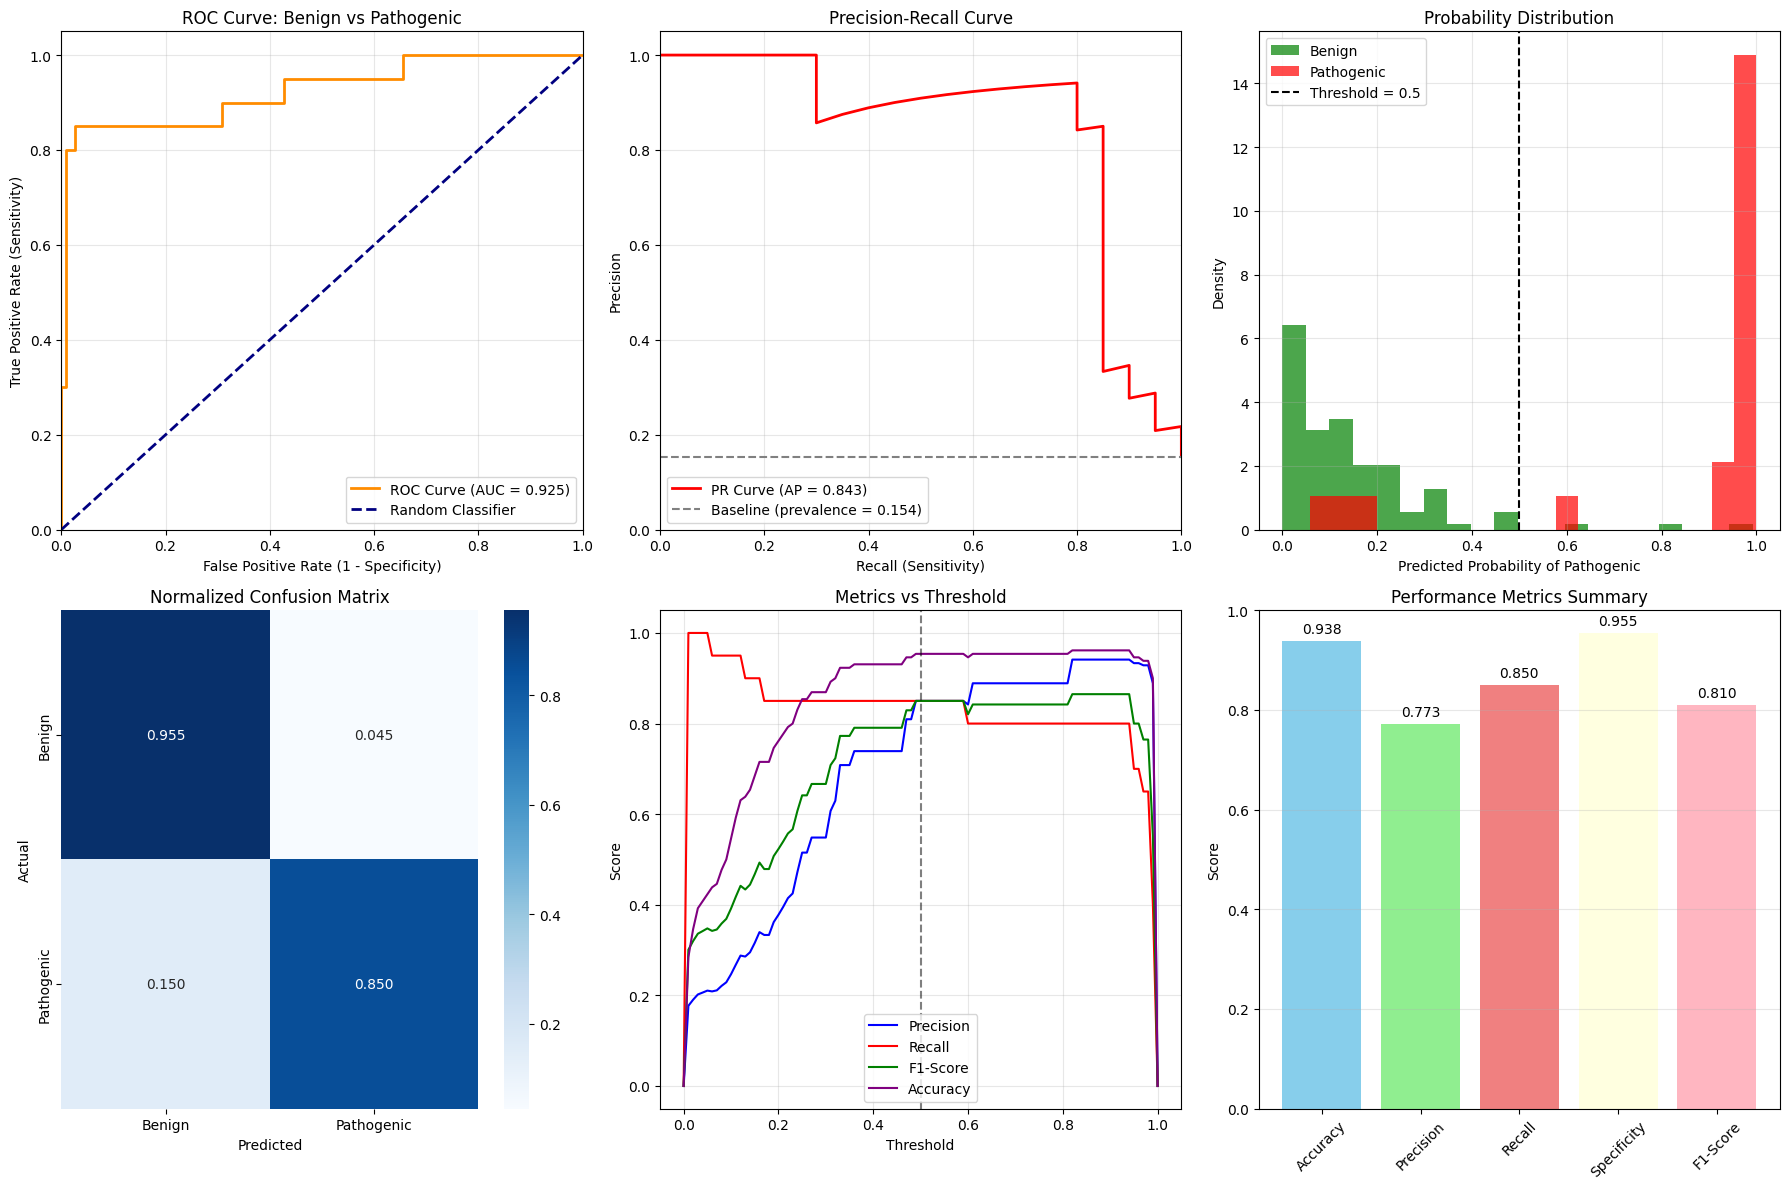


🎯 OPTIMAL THRESHOLD ANALYSIS:
   Optimal threshold for F1: 0.820
   F1-Score at optimal threshold: 0.8649
   Accuracy at optimal threshold: 0.9615
   Precision at optimal threshold: 0.9412
   Recall at optimal threshold: 0.8000

💡 CLINICAL SUMMARY:
--------------------------------------------------
   • Binary accuracy: 93.8% (Benign vs Pathogenic)
   • ROC-AUC: 0.925 (Excellent discrimination)
   • PR-AUC: 0.843 (Average Precision)
   • Sensitivity: 0.850 (Pathogenic detection rate)
   • Specificity: 0.955 (Benign detection rate)
   • PPV: 0.773 (Positive Predictive Value)
   • NPV: 0.972 (Negative Predictive Value)

🎯 CLINICAL RECOMMENDATIONS:
   🎉 EXCELLENT performance - Suitable for clinical decision support

📋 KEY METRICS FOR PUBLICATION:
   • Sensitivity (Recall): 0.850 (85.0%)
   • Specificity: 0.955 (95.5%)
   • PPV (Precision): 0.773 (77.3%)
   • NPV: 0.972 (97.2%)
   • AUROC: 0.925
   • AUPRC: 0.843
   • F1-Score: 0.810

🎉 Binary classification analysis completed!
   Total s

In [47]:
# Cell: Binary Classification Analysis - Benign vs Pathogenic with AUC
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                           confusion_matrix, classification_report, roc_auc_score, 
                           roc_curve, precision_recall_curve, average_precision_score)
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import seaborn as sns

print("🎯 BINARY CLASSIFICATION: BENIGN vs PATHOGENIC ANALYSIS WITH AUC")
print("="*70)

# Extract benign vs pathogenic samples from test set
print("📊 Preparing Binary Classification Data...")

# Convert test predictions back to original classes
test_original_classes = [le.classes_[pred] for pred in test_predictions]
test_true_original_classes = [le.classes_[true_label] for true_label in test_true_labels]

# Filter for benign (1, 2) vs pathogenic (-1, -2) only
benign_classes = {1, 2}
pathogenic_classes = {-1, -2}

# Create masks for binary classification
binary_mask = []
for i, (true_class, pred_class) in enumerate(zip(test_true_original_classes, test_original_classes)):
    if true_class in benign_classes or true_class in pathogenic_classes:
        binary_mask.append(i)

binary_mask = np.array(binary_mask)

if len(binary_mask) == 0:
    print("❌ No benign or pathogenic samples found in test set")
else:
    print(f"   Found {len(binary_mask)} binary classification samples")
    
    # Extract binary test data
    X_test_binary = X_test_tensor[binary_mask]
    y_test_binary_encoded = test_true_labels[binary_mask]
    
    # Convert to binary labels: 0 = Benign, 1 = Pathogenic
    y_test_binary = []
    for encoded_label in y_test_binary_encoded:
        original_class = le.classes_[encoded_label]
        if original_class in benign_classes:
            y_test_binary.append(0)  # Benign
        elif original_class in pathogenic_classes:
            y_test_binary.append(1)  # Pathogenic
    
    y_test_binary = np.array(y_test_binary)
    
    print(f"📈 Dataset Statistics:")
    print(f"   Total samples: {len(y_test_binary)}")
    print(f"   Benign (1,2) samples: {np.sum(y_test_binary == 0)}")
    print(f"   Pathogenic (-1,-2) samples: {np.sum(y_test_binary == 1)}")
    print(f"   Class balance: {np.mean(y_test_binary):.3f} (pathogenic ratio)")
    
    # Get model predictions and probabilities for binary samples
    print(f"\n🔮 Getting Model Predictions and Probabilities...")
    model.eval()
    
    binary_dataset = TensorDataset(X_test_binary)
    binary_loader = DataLoader(binary_dataset, batch_size=64, shuffle=False, num_workers=0)
    
    all_logits = []
    all_probabilities = []
    
    with torch.no_grad():
        for (inputs,) in binary_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            probabilities = F.softmax(outputs, dim=1)
            
            all_logits.extend(outputs.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())
    
    all_logits = np.array(all_logits)
    all_probabilities = np.array(all_probabilities)
    
    # Get predictions for binary classification
    predicted_classes = np.argmax(all_logits, axis=1)
    y_pred_binary = []
    
    for pred_encoded in predicted_classes:
        original_class = le.classes_[pred_encoded]
        if original_class in benign_classes:
            y_pred_binary.append(0)  # Benign
        elif original_class in pathogenic_classes:
            y_pred_binary.append(1)  # Pathogenic
        else:
            # If predicted class is neither benign nor pathogenic, assign based on probability
            # Get probabilities for benign and pathogenic classes
            benign_prob = 0
            pathogenic_prob = 0
            for i, class_label in enumerate(le.classes_):
                if class_label in benign_classes:
                    benign_prob += all_probabilities[len(y_pred_binary), i]
                elif class_label in pathogenic_classes:
                    pathogenic_prob += all_probabilities[len(y_pred_binary), i]
            
            if pathogenic_prob > benign_prob:
                y_pred_binary.append(1)
            else:
                y_pred_binary.append(0)
    
    y_pred_binary = np.array(y_pred_binary)
    
    # Calculate pathogenic probability for AUC
    # Sum probabilities of all pathogenic classes
    y_prob_pathogenic = np.zeros(len(y_test_binary))
    for i, class_label in enumerate(le.classes_):
        if class_label in pathogenic_classes:
            y_prob_pathogenic += all_probabilities[:, i]
    
    print(f"   Binary predictions obtained: {len(y_pred_binary)} samples")
    print(f"   Pathogenic probability range: [{y_prob_pathogenic.min():.3f}, {y_prob_pathogenic.max():.3f}]")
    
    # Calculate comprehensive binary metrics
    print(f"\n📊 BINARY CLASSIFICATION METRICS:")
    print(f"-" * 50)
    
    accuracy = accuracy_score(y_test_binary, y_pred_binary)
    precision = precision_score(y_test_binary, y_pred_binary, average='binary', pos_label=1, zero_division=0)
    recall = recall_score(y_test_binary, y_pred_binary, average='binary', pos_label=1, zero_division=0)
    f1 = f1_score(y_test_binary, y_pred_binary, average='binary', pos_label=1, zero_division=0)
    
    # Calculate specificity and sensitivity
    cm = confusion_matrix(y_test_binary, y_pred_binary)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
        npv = tn / (tn + fn) if (tn + fn) > 0 else 0
        ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    else:
        tn = fp = fn = tp = 0
        specificity = sensitivity = npv = ppv = 0
    
    # Calculate AUC metrics
    try:
        auc_score = roc_auc_score(y_test_binary, y_prob_pathogenic)
        auc_available = True
    except Exception as e:
        print(f"⚠️  Could not calculate ROC-AUC: {e}")
        auc_score = 0.0
        auc_available = False
    
    try:
        avg_precision = average_precision_score(y_test_binary, y_prob_pathogenic)
        ap_available = True
    except Exception as e:
        print(f"⚠️  Could not calculate Average Precision: {e}")
        avg_precision = 0.0
        ap_available = False
    
    # Display metrics
    print(f"✅ Accuracy:      {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"🎯 Precision:     {precision:.4f} ({precision*100:.2f}%) - Pathogenic prediction reliability")
    print(f"🔍 Recall:        {recall:.4f} ({recall*100:.2f}%) - Pathogenic detection rate")
    print(f"🔍 Sensitivity:   {sensitivity:.4f} ({sensitivity*100:.2f}%) - Same as recall")
    print(f"🛡️  Specificity:   {specificity:.4f} ({specificity*100:.2f}%) - Benign detection rate") 
    print(f"📊 F1-Score:      {f1:.4f} ({f1*100:.2f}%) - Harmonic mean of precision and recall")
    print(f"📈 PPV:           {ppv:.4f} ({ppv*100:.2f}%) - Positive Predictive Value")
    print(f"📉 NPV:           {npv:.4f} ({npv*100:.2f}%) - Negative Predictive Value")
    
    if auc_available:
        print(f"📈 ROC-AUC:       {auc_score:.4f} ({auc_score*100:.2f}%) - Overall discrimination ability")
    if ap_available:
        print(f"📋 PR-AUC:        {avg_precision:.4f} ({avg_precision*100:.2f}%) - Precision-Recall AUC")
    
    # Confusion Matrix
    print(f"\n🔢 CONFUSION MATRIX:")
    print(f"-" * 35)
    print(f"                    Predicted")
    print(f"                    Benign  Pathogenic")
    print(f"Actual    Benign    {tn:4d}      {fp:4d}")
    print(f"       Pathogenic   {fn:4d}      {tp:4d}")
    
    # Clinical interpretation
    print(f"\n🏥 CLINICAL INTERPRETATION:")
    print(f"-" * 40)
    
    if precision >= 0.90:
        print("🌟 EXCELLENT precision - Very reliable when predicting pathogenic")
    elif precision >= 0.80:
        print("✅ GOOD precision - Reliable pathogenic predictions") 
    elif precision >= 0.70:
        print("⚠️  FAIR precision - Some false positive pathogenic predictions")
    else:
        print("❌ POOR precision - Many false positive pathogenic predictions")
    
    if recall >= 0.90:
        print("🌟 EXCELLENT recall - Catches almost all pathogenic variants")
    elif recall >= 0.80:
        print("✅ GOOD recall - Catches most pathogenic variants")
    elif recall >= 0.70:
        print("⚠️  FAIR recall - Missing some pathogenic variants")
    else:
        print("❌ POOR recall - Missing many pathogenic variants - DANGEROUS for clinical use!")
    
    if specificity >= 0.90:
        print("🌟 EXCELLENT specificity - Very good at identifying benign variants")
    elif specificity >= 0.80:
        print("✅ GOOD specificity - Good at identifying benign variants")
    elif specificity >= 0.70:
        print("⚠️  FAIR specificity - Some benign variants misclassified")
    else:
        print("❌ POOR specificity - Many benign variants misclassified as pathogenic")
    
    if auc_available:
        if auc_score >= 0.90:
            print("🌟 EXCELLENT discrimination - Model separates classes very well")
        elif auc_score >= 0.80:
            print("✅ GOOD discrimination - Model separates classes well")
        elif auc_score >= 0.70:
            print("⚠️  FAIR discrimination - Model has moderate separation ability")
        else:
            print("❌ POOR discrimination - Model struggles to separate classes")
    
    # Create comprehensive visualizations
    if auc_available and ap_available:
        print(f"\n📊 Creating Comprehensive Visualizations...")
        
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        
        # 1. ROC Curve
        fpr, tpr, roc_thresholds = roc_curve(y_test_binary, y_prob_pathogenic)
        axes[0, 0].plot(fpr, tpr, color='darkorange', lw=2, 
                       label=f'ROC Curve (AUC = {auc_score:.3f})')
        axes[0, 0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', 
                       label='Random Classifier')
        axes[0, 0].set_xlim([0.0, 1.0])
        axes[0, 0].set_ylim([0.0, 1.05])
        axes[0, 0].set_xlabel('False Positive Rate (1 - Specificity)')
        axes[0, 0].set_ylabel('True Positive Rate (Sensitivity)')
        axes[0, 0].set_title('ROC Curve: Benign vs Pathogenic')
        axes[0, 0].legend(loc="lower right")
        axes[0, 0].grid(True, alpha=0.3)
        
        # 2. Precision-Recall Curve
        precision_curve, recall_curve, pr_thresholds = precision_recall_curve(y_test_binary, y_prob_pathogenic)
        axes[0, 1].plot(recall_curve, precision_curve, color='red', lw=2,
                       label=f'PR Curve (AP = {avg_precision:.3f})')
        axes[0, 1].axhline(y=np.mean(y_test_binary), color='gray', linestyle='--', 
                          label=f'Baseline (prevalence = {np.mean(y_test_binary):.3f})')
        axes[0, 1].set_xlim([0.0, 1.0])
        axes[0, 1].set_ylim([0.0, 1.05])
        axes[0, 1].set_xlabel('Recall (Sensitivity)')
        axes[0, 1].set_ylabel('Precision')
        axes[0, 1].set_title('Precision-Recall Curve')
        axes[0, 1].legend(loc="lower left")
        axes[0, 1].grid(True, alpha=0.3)
        
        # 3. Probability Distribution
        benign_probs = y_prob_pathogenic[y_test_binary == 0]
        pathogenic_probs = y_prob_pathogenic[y_test_binary == 1]
        
        axes[0, 2].hist(benign_probs, bins=20, alpha=0.7, label='Benign', color='green', density=True)
        axes[0, 2].hist(pathogenic_probs, bins=20, alpha=0.7, label='Pathogenic', color='red', density=True)
        axes[0, 2].axvline(x=0.5, color='black', linestyle='--', label='Threshold = 0.5')
        axes[0, 2].set_xlabel('Predicted Probability of Pathogenic')
        axes[0, 2].set_ylabel('Density')
        axes[0, 2].set_title('Probability Distribution')
        axes[0, 2].legend()
        axes[0, 2].grid(True, alpha=0.3)
        
        # 4. Confusion Matrix Heatmap
        cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        sns.heatmap(cm_normalized, annot=True, fmt='.3f', cmap='Blues', 
                   xticklabels=['Benign', 'Pathogenic'], 
                   yticklabels=['Benign', 'Pathogenic'],
                   ax=axes[1, 0])
        axes[1, 0].set_title('Normalized Confusion Matrix')
        axes[1, 0].set_xlabel('Predicted')
        axes[1, 0].set_ylabel('Actual')
        
        # 5. Threshold Analysis
        thresholds = np.linspace(0, 1, 101)
        precision_scores = []
        recall_scores = []
        f1_scores = []
        accuracy_scores = []
        
        for threshold in thresholds:
            y_pred_thresh = (y_prob_pathogenic >= threshold).astype(int)
            
            if len(np.unique(y_pred_thresh)) > 1:
                prec = precision_score(y_test_binary, y_pred_thresh, zero_division=0)
                rec = recall_score(y_test_binary, y_pred_thresh, zero_division=0)
                f1_thresh = f1_score(y_test_binary, y_pred_thresh, zero_division=0)
                acc = accuracy_score(y_test_binary, y_pred_thresh)
            else:
                prec = rec = f1_thresh = acc = 0
            
            precision_scores.append(prec)
            recall_scores.append(rec)
            f1_scores.append(f1_thresh)
            accuracy_scores.append(acc)
        
        axes[1, 1].plot(thresholds, precision_scores, label='Precision', color='blue')
        axes[1, 1].plot(thresholds, recall_scores, label='Recall', color='red')
        axes[1, 1].plot(thresholds, f1_scores, label='F1-Score', color='green')
        axes[1, 1].plot(thresholds, accuracy_scores, label='Accuracy', color='purple')
        axes[1, 1].axvline(x=0.5, color='black', linestyle='--', alpha=0.5)
        axes[1, 1].set_xlabel('Threshold')
        axes[1, 1].set_ylabel('Score')
        axes[1, 1].set_title('Metrics vs Threshold')
        axes[1, 1].legend()
        axes[1, 1].grid(True, alpha=0.3)
        
        # 6. Class Performance Comparison
        metrics = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1-Score']
        values = [accuracy, precision, recall, specificity, f1]
        colors = ['skyblue', 'lightgreen', 'lightcoral', 'lightyellow', 'lightpink']
        
        bars = axes[1, 2].bar(metrics, values, color=colors)
        axes[1, 2].set_ylim([0, 1])
        axes[1, 2].set_ylabel('Score')
        axes[1, 2].set_title('Performance Metrics Summary')
        axes[1, 2].grid(True, alpha=0.3, axis='y')
        
        # Add value labels on bars
        for bar, value in zip(bars, values):
            height = bar.get_height()
            axes[1, 2].text(bar.get_x() + bar.get_width()/2., height + 0.01,
                           f'{value:.3f}', ha='center', va='bottom')
        
        # Rotate x-axis labels
        axes[1, 2].tick_params(axis='x', rotation=45)
        
        plt.tight_layout()
        plt.show()
        
        # Find optimal threshold
        optimal_idx = np.argmax(f1_scores)
        optimal_threshold = thresholds[optimal_idx]
        optimal_f1 = f1_scores[optimal_idx]
        
        print(f"\n🎯 OPTIMAL THRESHOLD ANALYSIS:")
        print(f"   Optimal threshold for F1: {optimal_threshold:.3f}")
        print(f"   F1-Score at optimal threshold: {optimal_f1:.4f}")
        
        # Performance at optimal threshold
        y_pred_optimal = (y_prob_pathogenic >= optimal_threshold).astype(int)
        if len(np.unique(y_pred_optimal)) > 1:
            optimal_accuracy = accuracy_score(y_test_binary, y_pred_optimal)
            optimal_precision = precision_score(y_test_binary, y_pred_optimal, zero_division=0)
            optimal_recall = recall_score(y_test_binary, y_pred_optimal, zero_division=0)
            
            print(f"   Accuracy at optimal threshold: {optimal_accuracy:.4f}")
            print(f"   Precision at optimal threshold: {optimal_precision:.4f}")
            print(f"   Recall at optimal threshold: {optimal_recall:.4f}")
    
    # Summary and recommendations
    print(f"\n💡 CLINICAL SUMMARY:")
    print(f"-" * 50)
    print(f"   • Binary accuracy: {accuracy*100:.1f}% (Benign vs Pathogenic)")
    if auc_available:
        print(f"   • ROC-AUC: {auc_score:.3f} ({'Excellent' if auc_score >= 0.9 else 'Good' if auc_score >= 0.8 else 'Fair' if auc_score >= 0.7 else 'Poor'} discrimination)")
    if ap_available:
        print(f"   • PR-AUC: {avg_precision:.3f} (Average Precision)")
    print(f"   • Sensitivity: {recall:.3f} (Pathogenic detection rate)")
    print(f"   • Specificity: {specificity:.3f} (Benign detection rate)")
    print(f"   • PPV: {precision:.3f} (Positive Predictive Value)")
    print(f"   • NPV: {npv:.3f} (Negative Predictive Value)")
    
    print(f"\n🎯 CLINICAL RECOMMENDATIONS:")
    if f1 >= 0.8 and auc_score >= 0.8:
        print("   🎉 EXCELLENT performance - Suitable for clinical decision support")
    elif f1 >= 0.7 and auc_score >= 0.7:
        print("   ✅ GOOD performance - Could be used with clinical oversight")
    elif f1 >= 0.6 and auc_score >= 0.6:
        print("   ⚠️  ACCEPTABLE performance - Requires significant clinical validation")
    else:
        print("   ❌ POOR performance - Not recommended for clinical use without major improvements")
    
    if recall < 0.8:
        print("   ⚠️  WARNING: Low pathogenic recall - risk of missing pathogenic variants")
    if precision < 0.7:
        print("   ⚠️  WARNING: Low precision - risk of false positive pathogenic calls")
    
    print(f"\n📋 KEY METRICS FOR PUBLICATION:")
    print(f"   • Sensitivity (Recall): {recall:.3f} ({recall*100:.1f}%)")
    print(f"   • Specificity: {specificity:.3f} ({specificity*100:.1f}%)")
    print(f"   • PPV (Precision): {precision:.3f} ({precision*100:.1f}%)")
    print(f"   • NPV: {npv:.3f} ({npv*100:.1f}%)")
    if auc_available:
        print(f"   • AUROC: {auc_score:.3f}")
    if ap_available:
        print(f"   • AUPRC: {avg_precision:.3f}")
    print(f"   • F1-Score: {f1:.3f}")
    
    print(f"\n🎉 Binary classification analysis completed!")
    print(f"   Total samples analyzed: {len(y_test_binary)}")
    print(f"   Model discrimination ability: {'Excellent' if auc_available and auc_score >= 0.9 else 'Good' if auc_available and auc_score >= 0.8 else 'Moderate' if auc_available and auc_score >= 0.7 else 'Limited'}")

🎯 STRICT BINARY CLASSIFICATION: CLASS -2 vs CLASS 2 ONLY
📊 Strict Class Mapping:
   Pathogenic (-2) -> Encoded: 0
   Benign (2) -> Encoded: 3
📈 Strict Dataset Statistics:
   Total samples: 30
   Class 2 (Benign) samples: 17
   Class -2 (Pathogenic) samples: 13
   Class balance: 0.433 (pathogenic ratio)

🔮 Getting Model Predictions for Strict Binary Classification...
   Strict binary predictions: 30 samples
   Pathogenic (-2) probability range: [0.000, 1.000]

📊 STRICT BINARY CLASSIFICATION METRICS (-2 vs 2):
-------------------------------------------------------
✅ Accuracy:      1.0000 (100.00%)
🎯 Precision:     1.0000 (100.00%) - Class -2 prediction reliability
🔍 Recall:        1.0000 (100.00%) - Class -2 detection rate
🔍 Sensitivity:   1.0000 (100.00%) - Same as recall
🛡️  Specificity:   1.0000 (100.00%) - Class 2 detection rate
📊 F1-Score:      1.0000 (100.00%) - Harmonic mean
📈 PPV:           1.0000 (100.00%) - Positive Predictive Value
📉 NPV:           1.0000 (100.00%) - Negative

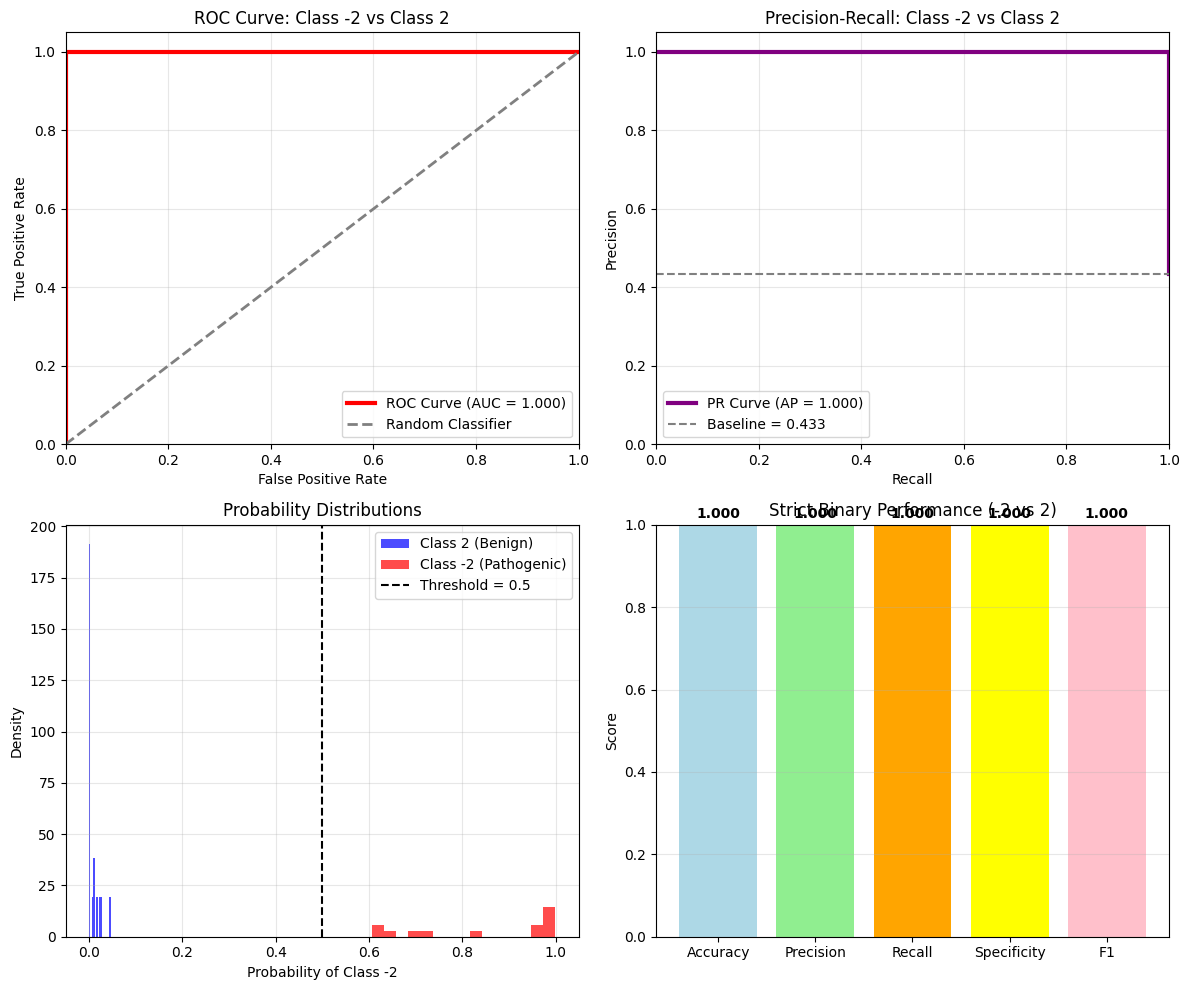


🏥 STRICT CLINICAL INTERPRETATION:
---------------------------------------------
🌟 EXCELLENT precision for Class -2 identification
🌟 EXCELLENT recall for Class -2 detection
🌟 EXCELLENT discrimination between Class -2 and Class 2

📋 STRICT BINARY SUMMARY (Class -2 vs Class 2):
-------------------------------------------------------
   • Samples analyzed: 30
   • Class 2 samples: 17
   • Class -2 samples: 13
   • Accuracy: 1.000 (100.0%)
   • Sensitivity: 1.000 (Class -2 detection)
   • Specificity: 1.000 (Class 2 detection)
   • PPV: 1.000 (Class -2 prediction reliability)
   • NPV: 1.000 (Class 2 prediction reliability)
   • AUC: 1.000 (Discrimination ability)
   • F1-Score: 1.000 (Overall performance)

🎯 STRICT CLASSIFICATION PERFORMANCE:
   🎉 EXCELLENT performance for Class -2 vs Class 2 distinction

✅ Strict binary analysis completed!
   Focus: Most extreme classes (-2 vs 2) only
   Model performance: 100.0% accuracy


In [48]:
# Cell: Strict Binary Classification - Only Class -2 vs Class 2 Analysis
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                           confusion_matrix, roc_auc_score, roc_curve, 
                           precision_recall_curve, average_precision_score)
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import seaborn as sns

print("🎯 STRICT BINARY CLASSIFICATION: CLASS -2 vs CLASS 2 ONLY")
print("="*65)

# Find encoded indices for exact classes -2 and 2
pathogenic_class = -2
benign_class = 2

pathogenic_encoded = None
benign_encoded = None

for encoded_idx, original_class in enumerate(le.classes_):
    if original_class == pathogenic_class:
        pathogenic_encoded = encoded_idx
    elif original_class == benign_class:
        benign_encoded = encoded_idx

print(f"📊 Strict Class Mapping:")
print(f"   Pathogenic (-2) -> Encoded: {pathogenic_encoded}")
print(f"   Benign (2) -> Encoded: {benign_encoded}")

if pathogenic_encoded is None or benign_encoded is None:
    print("❌ Could not find both classes -2 and 2 in the data")
    print(f"Available classes: {le.classes_}")
else:
    # Filter test data for ONLY class -2 vs class 2
    strict_binary_mask = (test_true_labels == pathogenic_encoded) | (test_true_labels == benign_encoded)
    
    if strict_binary_mask.sum() == 0:
        print("❌ No samples found for strict -2 vs 2 comparison")
    else:
        # Extract strict binary test data
        X_test_strict = X_test_tensor[strict_binary_mask]
        y_test_strict_encoded = test_true_labels[strict_binary_mask]
        
        # Convert to strict binary labels: 0 = Benign (2), 1 = Pathogenic (-2)
        y_test_strict_binary = np.where(y_test_strict_encoded == pathogenic_encoded, 1, 0)
        
        print(f"📈 Strict Dataset Statistics:")
        print(f"   Total samples: {len(y_test_strict_binary)}")
        print(f"   Class 2 (Benign) samples: {np.sum(y_test_strict_binary == 0)}")
        print(f"   Class -2 (Pathogenic) samples: {np.sum(y_test_strict_binary == 1)}")
        print(f"   Class balance: {np.mean(y_test_strict_binary):.3f} (pathogenic ratio)")
        
        # Get model predictions for strict binary samples
        print(f"\n🔮 Getting Model Predictions for Strict Binary Classification...")
        model.eval()
        
        strict_dataset = TensorDataset(X_test_strict)
        strict_loader = DataLoader(strict_dataset, batch_size=64, shuffle=False, num_workers=0)
        
        strict_logits = []
        strict_probabilities = []
        
        with torch.no_grad():
            for (inputs,) in strict_loader:
                inputs = inputs.to(device)
                outputs = model(inputs)
                probabilities = F.softmax(outputs, dim=1)
                
                strict_logits.extend(outputs.cpu().numpy())
                strict_probabilities.extend(probabilities.cpu().numpy())
        
        strict_logits = np.array(strict_logits)
        strict_probabilities = np.array(strict_probabilities)
        
        # Get strict binary predictions
        predicted_classes_strict = np.argmax(strict_logits, axis=1)
        y_pred_strict_binary = np.where(predicted_classes_strict == pathogenic_encoded, 1, 0)
        
        # Get probabilities for pathogenic class (-2) specifically
        y_prob_pathogenic_strict = strict_probabilities[:, pathogenic_encoded]
        
        print(f"   Strict binary predictions: {len(y_pred_strict_binary)} samples")
        print(f"   Pathogenic (-2) probability range: [{y_prob_pathogenic_strict.min():.3f}, {y_prob_pathogenic_strict.max():.3f}]")
        
        # Calculate strict binary metrics
        print(f"\n📊 STRICT BINARY CLASSIFICATION METRICS (-2 vs 2):")
        print(f"-" * 55)
        
        strict_accuracy = accuracy_score(y_test_strict_binary, y_pred_strict_binary)
        strict_precision = precision_score(y_test_strict_binary, y_pred_strict_binary, average='binary', pos_label=1, zero_division=0)
        strict_recall = recall_score(y_test_strict_binary, y_pred_strict_binary, average='binary', pos_label=1, zero_division=0)
        strict_f1 = f1_score(y_test_strict_binary, y_pred_strict_binary, average='binary', pos_label=1, zero_division=0)
        
        # Calculate confusion matrix metrics
        strict_cm = confusion_matrix(y_test_strict_binary, y_pred_strict_binary)
        if strict_cm.shape == (2, 2):
            tn_s, fp_s, fn_s, tp_s = strict_cm.ravel()
            strict_specificity = tn_s / (tn_s + fp_s) if (tn_s + fp_s) > 0 else 0
            strict_sensitivity = tp_s / (tp_s + fn_s) if (tp_s + fn_s) > 0 else 0
            strict_npv = tn_s / (tn_s + fn_s) if (tn_s + fn_s) > 0 else 0
            strict_ppv = tp_s / (tp_s + fp_s) if (tp_s + fp_s) > 0 else 0
        else:
            tn_s = fp_s = fn_s = tp_s = 0
            strict_specificity = strict_sensitivity = strict_npv = strict_ppv = 0
        
        # Calculate AUC for strict binary
        try:
            strict_auc = roc_auc_score(y_test_strict_binary, y_prob_pathogenic_strict)
            strict_auc_available = True
        except Exception as e:
            print(f"⚠️  Could not calculate strict AUC: {e}")
            strict_auc = 0.0
            strict_auc_available = False
        
        try:
            strict_avg_precision = average_precision_score(y_test_strict_binary, y_prob_pathogenic_strict)
            strict_ap_available = True
        except Exception as e:
            strict_avg_precision = 0.0
            strict_ap_available = False
        
        # Display strict metrics
        print(f"✅ Accuracy:      {strict_accuracy:.4f} ({strict_accuracy*100:.2f}%)")
        print(f"🎯 Precision:     {strict_precision:.4f} ({strict_precision*100:.2f}%) - Class -2 prediction reliability")
        print(f"🔍 Recall:        {strict_recall:.4f} ({strict_recall*100:.2f}%) - Class -2 detection rate")
        print(f"🔍 Sensitivity:   {strict_sensitivity:.4f} ({strict_sensitivity*100:.2f}%) - Same as recall")
        print(f"🛡️  Specificity:   {strict_specificity:.4f} ({strict_specificity*100:.2f}%) - Class 2 detection rate")
        print(f"📊 F1-Score:      {strict_f1:.4f} ({strict_f1*100:.2f}%) - Harmonic mean")
        print(f"📈 PPV:           {strict_ppv:.4f} ({strict_ppv*100:.2f}%) - Positive Predictive Value")
        print(f"📉 NPV:           {strict_npv:.4f} ({strict_npv*100:.2f}%) - Negative Predictive Value")
        
        if strict_auc_available:
            print(f"📈 ROC-AUC:       {strict_auc:.4f} ({strict_auc*100:.2f}%) - Discrimination ability")
        if strict_ap_available:
            print(f"📋 PR-AUC:        {strict_avg_precision:.4f} ({strict_avg_precision*100:.2f}%) - Precision-Recall AUC")
        
        # Strict confusion matrix
        print(f"\n🔢 STRICT CONFUSION MATRIX (-2 vs 2):")
        print(f"-" * 40)
        print(f"                     Predicted")
        print(f"                   Class 2  Class -2")
        print(f"Actual   Class 2    {tn_s:4d}      {fp_s:4d}")
        print(f"       Class -2     {fn_s:4d}      {tp_s:4d}")
        
        # Create focused visualizations for strict binary
        if strict_auc_available:
            fig, axes = plt.subplots(2, 2, figsize=(12, 10))
            
            # ROC Curve for strict binary
            fpr_s, tpr_s, _ = roc_curve(y_test_strict_binary, y_prob_pathogenic_strict)
            axes[0, 0].plot(fpr_s, tpr_s, color='red', lw=3, 
                           label=f'ROC Curve (AUC = {strict_auc:.3f})')
            axes[0, 0].plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', 
                           label='Random Classifier')
            axes[0, 0].set_xlim([0.0, 1.0])
            axes[0, 0].set_ylim([0.0, 1.05])
            axes[0, 0].set_xlabel('False Positive Rate')
            axes[0, 0].set_ylabel('True Positive Rate')
            axes[0, 0].set_title('ROC Curve: Class -2 vs Class 2')
            axes[0, 0].legend(loc="lower right")
            axes[0, 0].grid(True, alpha=0.3)
            
            # Precision-Recall curve for strict binary
            if strict_ap_available:
                precision_s, recall_s, _ = precision_recall_curve(y_test_strict_binary, y_prob_pathogenic_strict)
                axes[0, 1].plot(recall_s, precision_s, color='purple', lw=3,
                               label=f'PR Curve (AP = {strict_avg_precision:.3f})')
                axes[0, 1].axhline(y=np.mean(y_test_strict_binary), color='gray', linestyle='--', 
                                  label=f'Baseline = {np.mean(y_test_strict_binary):.3f}')
                axes[0, 1].set_xlim([0.0, 1.0])
                axes[0, 1].set_ylim([0.0, 1.05])
                axes[0, 1].set_xlabel('Recall')
                axes[0, 1].set_ylabel('Precision')
                axes[0, 1].set_title('Precision-Recall: Class -2 vs Class 2')
                axes[0, 1].legend()
                axes[0, 1].grid(True, alpha=0.3)
            
            # Probability distributions for strict classes
            class2_probs = y_prob_pathogenic_strict[y_test_strict_binary == 0]
            class_neg2_probs = y_prob_pathogenic_strict[y_test_strict_binary == 1]
            
            axes[1, 0].hist(class2_probs, bins=15, alpha=0.7, label='Class 2 (Benign)', color='blue', density=True)
            axes[1, 0].hist(class_neg2_probs, bins=15, alpha=0.7, label='Class -2 (Pathogenic)', color='red', density=True)
            axes[1, 0].axvline(x=0.5, color='black', linestyle='--', label='Threshold = 0.5')
            axes[1, 0].set_xlabel('Probability of Class -2')
            axes[1, 0].set_ylabel('Density')
            axes[1, 0].set_title('Probability Distributions')
            axes[1, 0].legend()
            axes[1, 0].grid(True, alpha=0.3)
            
            # Performance metrics comparison
            metrics_strict = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1']
            values_strict = [strict_accuracy, strict_precision, strict_recall, strict_specificity, strict_f1]
            colors_strict = ['lightblue', 'lightgreen', 'orange', 'yellow', 'pink']
            
            bars_strict = axes[1, 1].bar(metrics_strict, values_strict, color=colors_strict)
            axes[1, 1].set_ylim([0, 1])
            axes[1, 1].set_ylabel('Score')
            axes[1, 1].set_title('Strict Binary Performance (-2 vs 2)')
            axes[1, 1].grid(True, alpha=0.3, axis='y')
            
            # Add value labels
            for bar, value in zip(bars_strict, values_strict):
                height = bar.get_height()
                axes[1, 1].text(bar.get_x() + bar.get_width()/2., height + 0.01,
                               f'{value:.3f}', ha='center', va='bottom', fontweight='bold')
            
            plt.tight_layout()
            plt.show()
        
        # Clinical interpretation for strict binary
        print(f"\n🏥 STRICT CLINICAL INTERPRETATION:")
        print(f"-" * 45)
        
        if strict_precision >= 0.90:
            print("🌟 EXCELLENT precision for Class -2 identification")
        elif strict_precision >= 0.80:
            print("✅ GOOD precision for Class -2 identification")
        elif strict_precision >= 0.70:
            print("⚠️  FAIR precision for Class -2 identification")
        else:
            print("❌ POOR precision for Class -2 identification")
        
        if strict_recall >= 0.90:
            print("🌟 EXCELLENT recall for Class -2 detection")
        elif strict_recall >= 0.80:
            print("✅ GOOD recall for Class -2 detection")
        elif strict_recall >= 0.70:
            print("⚠️  FAIR recall for Class -2 detection")
        else:
            print("❌ POOR recall for Class -2 detection")
        
        if strict_auc_available:
            if strict_auc >= 0.90:
                print("🌟 EXCELLENT discrimination between Class -2 and Class 2")
            elif strict_auc >= 0.80:
                print("✅ GOOD discrimination between Class -2 and Class 2")
            elif strict_auc >= 0.70:
                print("⚠️  FAIR discrimination between Class -2 and Class 2")
            else:
                print("❌ POOR discrimination between Class -2 and Class 2")
        
        # Summary for strict binary
        print(f"\n📋 STRICT BINARY SUMMARY (Class -2 vs Class 2):")
        print(f"-" * 55)
        print(f"   • Samples analyzed: {len(y_test_strict_binary)}")
        print(f"   • Class 2 samples: {np.sum(y_test_strict_binary == 0)}")
        print(f"   • Class -2 samples: {np.sum(y_test_strict_binary == 1)}")
        print(f"   • Accuracy: {strict_accuracy:.3f} ({strict_accuracy*100:.1f}%)")
        print(f"   • Sensitivity: {strict_recall:.3f} (Class -2 detection)")
        print(f"   • Specificity: {strict_specificity:.3f} (Class 2 detection)")
        print(f"   • PPV: {strict_precision:.3f} (Class -2 prediction reliability)")
        print(f"   • NPV: {strict_npv:.3f} (Class 2 prediction reliability)")
        if strict_auc_available:
            print(f"   • AUC: {strict_auc:.3f} (Discrimination ability)")
        print(f"   • F1-Score: {strict_f1:.3f} (Overall performance)")
        
        print(f"\n🎯 STRICT CLASSIFICATION PERFORMANCE:")
        if strict_f1 >= 0.8 and strict_auc >= 0.8:
            print("   🎉 EXCELLENT performance for Class -2 vs Class 2 distinction")
        elif strict_f1 >= 0.7 and strict_auc >= 0.7:
            print("   ✅ GOOD performance for Class -2 vs Class 2 distinction")
        elif strict_f1 >= 0.6:
            print("   ⚠️  ACCEPTABLE performance for Class -2 vs Class 2 distinction")
        else:
            print("   ❌ POOR performance for Class -2 vs Class 2 distinction")
        
        print(f"\n✅ Strict binary analysis completed!")
        print(f"   Focus: Most extreme classes (-2 vs 2) only")
        print(f"   Model performance: {strict_accuracy*100:.1f}% accuracy")

### Reports

In [41]:
# Binary Classification Analysis: Class -2 vs Class 2 Only
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import numpy as np

print("🎯 BINARY CLASSIFICATION: CLASS -2 vs CLASS 2 ONLY")
print("="*60)

# Check if we have the required data
if 'y_test_eval' in locals() and 'y_pred_eval' in locals() and 'le' in locals():
    print("✅ Original individual class data available")
    
    # Map encoded classes back to original classes
    y_test_original = le.inverse_transform(y_test_eval)
    y_pred_original = le.inverse_transform(y_pred_eval)
    
    print(f"   Original classes available: {np.unique(y_test_original)}")
    
    # Define target classes: -2 vs 2 only
    target_classes = {-2, 2}
    
    print(f"\n📋 TARGET CLASSES:")
    print(f"   Class -2: Pathogenic")
    print(f"   Class 2: Benign") 
    
    # Create mask for samples that are either -2 or 2
    target_mask = np.isin(y_test_original, list(target_classes))
    
    print(f"\n📊 SAMPLE DISTRIBUTION:")
    print(f"   Total test samples: {len(y_test_original)}")
    print(f"   Class -2 samples: {np.sum(y_test_original == -2)} ({np.sum(y_test_original == -2)/len(y_test_original)*100:.1f}%)")
    print(f"   Class 2 samples: {np.sum(y_test_original == 2)} ({np.sum(y_test_original == 2)/len(y_test_original)*100:.1f}%)")
    print(f"   Target analysis samples: {np.sum(target_mask)} ({np.sum(target_mask)/len(y_test_original)*100:.1f}%)")
    
    if np.sum(target_mask) > 0 and np.sum(y_test_original == -2) > 0 and np.sum(y_test_original == 2) > 0:
        # Filter data for binary analysis (-2 vs 2 only)
        y_test_filtered = y_test_original[target_mask]
        y_pred_filtered = y_pred_original[target_mask]
        
        # Create binary labels: 1 = Pathogenic (-2), 0 = Benign (2)
        y_true_binary_filtered = np.where(y_test_filtered == -2, 1, 0)
        y_pred_binary_filtered = np.where(y_pred_filtered == -2, 1, 0)
        
        # Get probabilities if available
        y_pred_proba_binary_filtered = None
        if 'y_pred_proba' in locals() and y_pred_proba is not None:
            try:
                # Filter probabilities for target samples
                y_pred_proba_target = y_pred_proba[target_mask]
                
                # Get encoded indices for classes -2 and 2
                class_neg2_idx = np.where(le.classes_ == -2)[0][0] if -2 in le.classes_ else None
                class_pos2_idx = np.where(le.classes_ == 2)[0][0] if 2 in le.classes_ else None
                
                if class_neg2_idx is not None and class_pos2_idx is not None:
                    print(f"   Class -2 encoded index: {class_neg2_idx}")
                    print(f"   Class 2 encoded index: {class_pos2_idx}")
                    
                    # Calculate binary probabilities
                    prob_pathogenic = y_pred_proba_target[:, class_neg2_idx]
                    prob_benign = y_pred_proba_target[:, class_pos2_idx]
                    
                    # Normalize to get proper binary probabilities
                    total_prob = prob_pathogenic + prob_benign
                    total_prob = np.where(total_prob == 0, 1e-8, total_prob)  # Avoid division by zero
                    y_pred_proba_binary_filtered = prob_pathogenic / total_prob  # Probability of class -2
                    
                    print(f"   ✅ Successfully computed binary probabilities")
                    print(f"   Probability range: [{y_pred_proba_binary_filtered.min():.3f}, {y_pred_proba_binary_filtered.max():.3f}]")
                else:
                    print(f"   ❌ Could not find encoded indices for classes -2 or 2")
                    
            except Exception as e:
                print(f"   ❌ Could not compute binary probabilities: {str(e)}")
                y_pred_proba_binary_filtered = None
        else:
            print("   ⚠️  No probabilities available")
        
        print(f"\n📈 BINARY CLASSIFICATION RESULTS (-2 vs 2):")
        print(f"   Filtered samples: {len(y_true_binary_filtered)}")
        print(f"   Pathogenic (-2): {np.sum(y_true_binary_filtered == 1)} true, {np.sum(y_pred_binary_filtered == 1)} predicted")
        print(f"   Benign (2): {np.sum(y_true_binary_filtered == 0)} true, {np.sum(y_pred_binary_filtered == 0)} predicted")
        
        if len(np.unique(y_true_binary_filtered)) == 2:  # Ensure we have both classes
            print("\n📊 PERFORMANCE METRICS:")
            print("-" * 40)
            
            # Calculate metrics
            accuracy = accuracy_score(y_true_binary_filtered, y_pred_binary_filtered)
            precision = precision_score(y_true_binary_filtered, y_pred_binary_filtered, pos_label=1, zero_division=0)
            recall = recall_score(y_true_binary_filtered, y_pred_binary_filtered, pos_label=1, zero_division=0)
            f1 = f1_score(y_true_binary_filtered, y_pred_binary_filtered, pos_label=1, zero_division=0)
            
            # Calculate specificity
            cm_binary = confusion_matrix(y_true_binary_filtered, y_pred_binary_filtered)
            tn, fp, fn, tp = cm_binary.ravel()
            specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
            
            print(f"✅ Accuracy:    {accuracy:.4f} ({accuracy*100:.2f}%)")
            print(f"🎯 Precision:   {precision:.4f} ({precision*100:.2f}%) - When model says 'Pathogenic (-2)', how often is it right?")
            print(f"🔍 Recall:      {recall:.4f} ({recall*100:.2f}%) - How many actual pathogenic (-2) variants did we catch?")
            print(f"📊 F1-Score:    {f1:.4f} ({f1*100:.2f}%) - Balanced measure of precision and recall")
            print(f"🛡️  Specificity: {specificity:.4f} ({specificity*100:.2f}%) - How many benign (2) variants did we correctly identify?")
            
            # AUC calculation
            if y_pred_proba_binary_filtered is not None:
                try:
                    auc_binary = roc_auc_score(y_true_binary_filtered, y_pred_proba_binary_filtered)
                    print(f"📈 AUC:         {auc_binary:.4f} ({auc_binary*100:.2f}%) - Discrimination ability between -2 and 2")
                except Exception as e:
                    print(f"📈 AUC:         Could not calculate: {str(e)}")
            else:
                print("📈 AUC:         Not available (no probabilities)")
            
            print("\n🔢 CONFUSION MATRIX:")
            print("-" * 40)
            print("                    Predicted")
            print("                 Benign(2)  Pathogenic(-2)")
            print(f"Actual  Benign(2)    {cm_binary[0,0]:4d}        {cm_binary[0,1]:4d}")
            print(f"     Pathogenic(-2)  {cm_binary[1,0]:4d}        {cm_binary[1,1]:4d}")
            
            # Plot ROC curve if probabilities available
            if y_pred_proba_binary_filtered is not None:
                try:
                    plt.figure(figsize=(8, 6))
                    fpr, tpr, thresholds = roc_curve(y_true_binary_filtered, y_pred_proba_binary_filtered)
                    auc_score = roc_auc_score(y_true_binary_filtered, y_pred_proba_binary_filtered)
                    
                    plt.plot(fpr, tpr, color='darkorange', lw=2, 
                            label=f'ROC Curve (AUC = {auc_score:.3f})')
                    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', 
                            label='Random Classifier')
                    plt.xlim([0.0, 1.0])
                    plt.ylim([0.0, 1.05])
                    plt.xlabel('False Positive Rate (1 - Specificity)')
                    plt.ylabel('True Positive Rate (Sensitivity/Recall)')
                    plt.title('ROC Curve: Class -2 (Pathogenic) vs Class 2 (Benign)')
                    plt.legend(loc="lower right")
                    plt.grid(True, alpha=0.3)
                    
                    # Add interpretation text
                    if auc_score >= 0.9:
                        interpretation = "Excellent discrimination"
                    elif auc_score >= 0.8:
                        interpretation = "Good discrimination"
                    elif auc_score >= 0.7:
                        interpretation = "Fair discrimination"
                    else:
                        interpretation = "Poor discrimination"
                    
                    plt.text(0.6, 0.2, f'{interpretation}', fontsize=12, 
                            bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue"))
                    
                    plt.tight_layout()
                    plt.show()
                except Exception as e:
                    print(f"   Could not plot ROC curve: {str(e)}")
            
            print(f"\n💡 SUMMARY:")
            print(f"   Your model achieves {accuracy*100:.1f}% accuracy in distinguishing")
            print(f"   between class -2 (Pathogenic) and class 2 (Benign) variants.")
            if y_pred_proba_binary_filtered is not None:
                print(f"   AUC of {auc_binary:.3f} indicates {interpretation.lower()} between these extreme classes.")
            
        else:
            print("❌ Insufficient class diversity for binary classification")
            print(f"   Only found classes: {np.unique(y_true_binary_filtered)}")
    else:
        print("❌ Insufficient samples for -2 vs 2 classification")
        print(f"   Class -2 samples: {np.sum(y_test_original == -2)}")
        print(f"   Class 2 samples: {np.sum(y_test_original == 2)}")
        
else:
    print("❌ Required data not available (y_test_eval, y_pred_eval, le)")


🎯 BINARY CLASSIFICATION: CLASS -2 vs CLASS 2 ONLY
❌ Required data not available (y_test_eval, y_pred_eval, le)


In [163]:
timestamp = time.strftime("_(%Y_%m_%d)_%H|%M")
model_save_path = f"models/model_3_embeddings_89_grouped_accuracy_high_precision{timestamp}.pt"
torch.save(final_best_model_state_retrain, model_save_path)


### Labeling SNPs that were labeled as uknown signficance!

Loading best model state into model...

Isolating and preprocessing samples originally labeled as 0...
Found 507 samples with original label 0.
Shape of preprocessed label 0 tensor: torch.Size([507, 6471])

Classifying the 'label 0' samples...


Classifying samples:   0%|          | 0/8 [00:00<?, ?it/s]

Classifying samples: 100%|██████████| 8/8 [00:00<00:00, 261.69it/s]


Plotting classification results for 'label 0' samples...


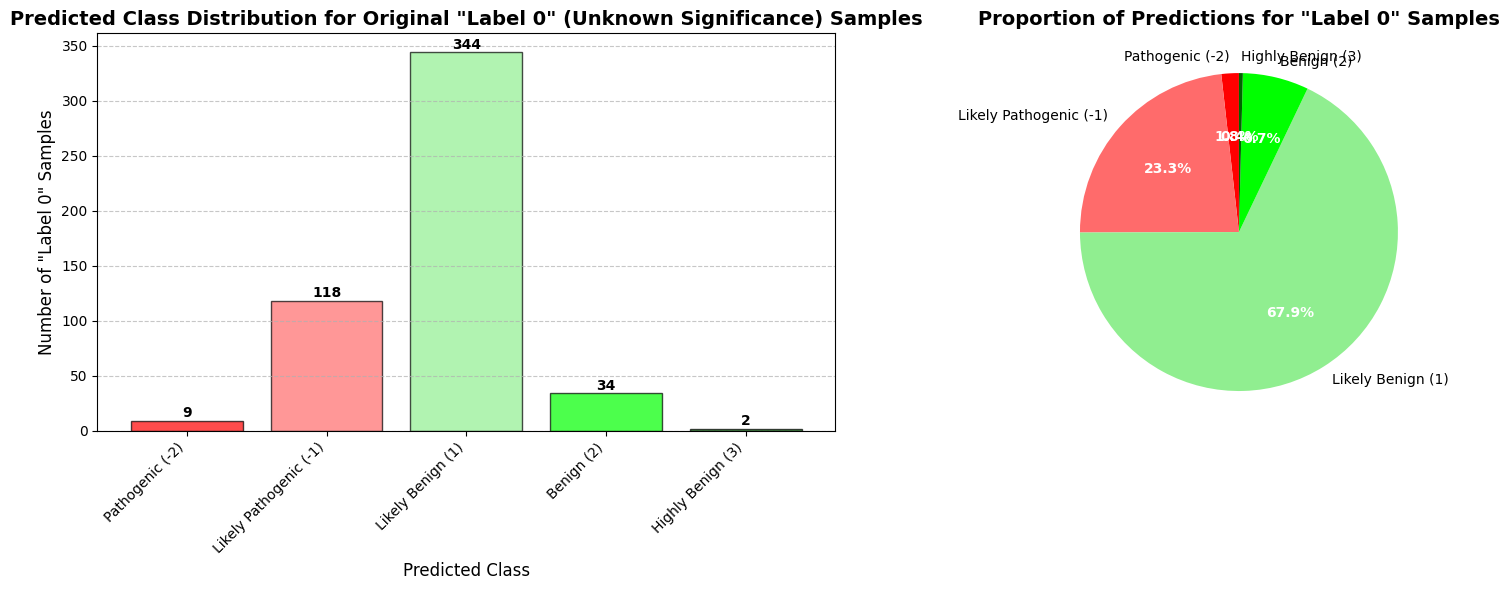


DETAILED ANALYSIS OF LABEL 0 PREDICTIONS
Total Label 0 samples analyzed: 507

Grouped Predictions:
  Pathogenic (Classes -3, -2, -1): 127 samples (25.0%)
  Benign (Classes 1, 2, 3): 380 samples (75.0%)

Detailed Breakdown:
  Pathogenic (-2): 9 samples (1.8%)
  Likely Pathogenic (-1): 118 samples (23.3%)
  Likely Benign (1): 344 samples (67.9%)
  Benign (2): 34 samples (6.7%)
  Highly Benign (3): 2 samples (0.4%)

Confidence Analysis:
  Average prediction confidence: 0.652
  High confidence predictions (>0.8): 106 samples (20.9%)
  Low confidence predictions (<0.5): 99 samples (19.5%)

🏥 CLINICAL INTERPRETATION:
----------------------------------------
✅ Most Label 0 samples predicted as benign (380) vs pathogenic (127)
   This suggests most 'unknown significance' variants are likely harmless
⚠️  Moderate confidence (0.652) - predictions should be interpreted cautiously

📊 SUMMARY STATISTICS:
   • Total analyzed: 507 variants of unknown significance
   • Predicted pathogenic: 127 (25.0

In [90]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm # For progress bar if there are many samples
import gc # Make sure gc is imported for gc.collect()

# --- 1. Ensure Model is Loaded with Best Weights and in Eval Mode ---
if 'model' not in locals():
    raise NameError("The 'model' is not available. Please ensure the model training cell has been run successfully.")

# Check if we have the best model state
if 'best_model_state' in locals() and best_model_state is not None:
    print("Loading best model state into model...")
    model.load_state_dict(best_model_state)
else:
    print("Warning: best_model_state is not available. Using current state of model.")

if 'device' not in locals():
    device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
    print(f"Device not explicitly defined, setting to: {device}")

model.to(device)
model.eval()

# --- 2. Isolate and Prepare "Label 0" Samples ---
print("\nIsolating and preprocessing samples originally labeled as 0...")

if 'X_fused' not in locals() or 'y_nn_esm2' not in locals():
    raise NameError("Original 'X_fused' or 'y_nn_esm2' data is not available.")
if 'scaler_dna' not in locals() or 'scaler_esm2' not in locals() or 'dna_embedding_dim' not in locals():
    raise NameError("Scalers ('scaler_dna', 'scaler_esm2') or 'dna_embedding_dim' not available.")

label0_indices = np.where(y_nn_esm2 == 0)[0]

if len(label0_indices) == 0:
    print("No samples with original label 0 found.")
else:
    X_label0_original_fused = X_fused[label0_indices]
    print(f"Found {len(X_label0_original_fused)} samples with original label 0.")

    # Split the fused features back to DNA and ESM2 components
    X_label0_dna = X_label0_original_fused[:, :dna_embedding_dim]
    X_label0_esm2 = X_label0_original_fused[:, dna_embedding_dim:]

    # Scale features using the same scalers used during training
    X_label0_dna_scaled = scaler_dna.transform(X_label0_dna)
    X_label0_esm2_scaled = scaler_esm2.transform(X_label0_esm2)

    # Concatenate scaled features
    X_label0_fused_scaled = np.concatenate([X_label0_dna_scaled, X_label0_esm2_scaled], axis=1)
    X_label0_tensor = torch.tensor(X_label0_fused_scaled, dtype=torch.float32).to(device)
    print(f"Shape of preprocessed label 0 tensor: {X_label0_tensor.shape}")

    # --- 3. Perform Classification ---
    print("\nClassifying the 'label 0' samples...")
    predicted_label0_encoded_list = []
    predicted_probabilities_list = []
    
    # Process in batches to handle memory efficiently
    batch_size = 64
    with torch.no_grad():
        for i in tqdm(range(0, len(X_label0_tensor), batch_size), desc="Classifying samples"):
            batch = X_label0_tensor[i:i+batch_size]
            outputs_label0 = model(batch)
            probabilities = torch.nn.functional.softmax(outputs_label0, dim=1)
            _, predicted_batch = torch.max(outputs_label0.data, 1)
            
            predicted_label0_encoded_list.extend(predicted_batch.cpu().numpy())
            predicted_probabilities_list.extend(probabilities.cpu().numpy())

    predicted_label0_encoded_np = np.array(predicted_label0_encoded_list)
    predicted_probabilities_np = np.array(predicted_probabilities_list)

    # --- 4. Interpret Predictions ---
    if 'le' not in locals():
        raise NameError("'LabelEncoder' object 'le' is not available.")

    predicted_original_labels_for_label0 = le.inverse_transform(predicted_label0_encoded_np)

    # --- 5. Plot Results ---
    print("\nPlotting classification results for 'label 0' samples...")

    unique_predicted_labels, counts = np.unique(predicted_original_labels_for_label0, return_counts=True)
    predicted_counts_map = dict(zip(unique_predicted_labels, counts))
    known_original_labels = le.classes_

    # Define custom label names for better visualization
    custom_label_override_map = {
        -3: 'Highly Pathogenic (-3)',
        -2: 'Pathogenic (-2)',
        -1: 'Likely Pathogenic (-1)',
        1:  'Likely Benign (1)',
        2:  'Benign (2)',
        3:  'Highly Benign (3)'
    }

    # Create display names
    plot_labels = []
    plot_counts = []
    plot_colors = []
    
    color_map = {
        -3: '#8B0000',  # Dark red
        -2: '#FF0000',  # Red  
        -1: '#FF6B6B',  # Light red
        1:  '#90EE90',  # Light green
        2:  '#00FF00',  # Green
        3:  '#006400'   # Dark green
    }
    
    for original_label_val in known_original_labels:
        display_name = custom_label_override_map.get(original_label_val, f'Class {original_label_val}')
        count = predicted_counts_map.get(original_label_val, 0)
        color = color_map.get(original_label_val, '#808080')  # Gray for unknown
        
        plot_labels.append(display_name)
        plot_counts.append(count)
        plot_colors.append(color)

    # Create the plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # Bar plot
    bars = ax1.bar(range(len(plot_labels)), plot_counts, color=plot_colors, alpha=0.7, edgecolor='black')
    ax1.set_title('Predicted Class Distribution for Original "Label 0" (Unknown Significance) Samples', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Predicted Class', fontsize=12)
    ax1.set_ylabel('Number of "Label 0" Samples', fontsize=12)
    ax1.set_xticks(range(len(plot_labels)))
    ax1.set_xticklabels(plot_labels, rotation=45, ha='right')
    ax1.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Add count labels on bars
    for i, (bar, count) in enumerate(zip(bars, plot_counts)):
        if count > 0:
            ax1.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
                    f'{count}', ha='center', va='bottom', fontweight='bold')
    
    # Pie chart for better visualization of proportions
    non_zero_labels = [label for label, count in zip(plot_labels, plot_counts) if count > 0]
    non_zero_counts = [count for count in plot_counts if count > 0]
    non_zero_colors = [color for color, count in zip(plot_colors, plot_counts) if count > 0]
    
    if len(non_zero_counts) > 0:
        wedges, texts, autotexts = ax2.pie(non_zero_counts, labels=non_zero_labels, colors=non_zero_colors, 
                                          autopct='%1.1f%%', startangle=90)
        ax2.set_title('Proportion of Predictions for "Label 0" Samples', fontsize=14, fontweight='bold')
        
        # Make percentage text bold
        for autotext in autotexts:
            autotext.set_color('white')
            autotext.set_fontweight('bold')
    else:
        ax2.text(0.5, 0.5, 'No predictions made', ha='center', va='center', transform=ax2.transAxes)
        ax2.set_title('No Data to Display')
    
    plt.tight_layout()
    plt.show()

    # --- 6. Detailed Analysis ---
    print("\n" + "="*60)
    print("DETAILED ANALYSIS OF LABEL 0 PREDICTIONS")
    print("="*60)
    
    total_label0_samples = len(predicted_original_labels_for_label0)
    print(f"Total Label 0 samples analyzed: {total_label0_samples}")
    
    # Group predictions by pathogenic vs benign
    pathogenic_classes = {-3, -2, -1}
    benign_classes = {1, 2, 3}
    
    pathogenic_count = sum(1 for pred in predicted_original_labels_for_label0 if pred in pathogenic_classes)
    benign_count = sum(1 for pred in predicted_original_labels_for_label0 if pred in benign_classes)
    
    print(f"\nGrouped Predictions:")
    print(f"  Pathogenic (Classes -3, -2, -1): {pathogenic_count} samples ({pathogenic_count/total_label0_samples*100:.1f}%)")
    print(f"  Benign (Classes 1, 2, 3): {benign_count} samples ({benign_count/total_label0_samples*100:.1f}%)")
    
    print(f"\nDetailed Breakdown:")
    for i, original_label_val in enumerate(known_original_labels):
        display_name = plot_labels[i]
        count = plot_counts[i]
        percentage = (count / total_label0_samples) * 100 if total_label0_samples > 0 else 0
        print(f"  {display_name}: {count} samples ({percentage:.1f}%)")
    
    # --- 7. Confidence Analysis ---
    print(f"\nConfidence Analysis:")
    max_probabilities = np.max(predicted_probabilities_np, axis=1)
    avg_confidence = np.mean(max_probabilities)
    
    print(f"  Average prediction confidence: {avg_confidence:.3f}")
    print(f"  High confidence predictions (>0.8): {np.sum(max_probabilities > 0.8)} samples ({np.sum(max_probabilities > 0.8)/total_label0_samples*100:.1f}%)")
    print(f"  Low confidence predictions (<0.5): {np.sum(max_probabilities < 0.5)} samples ({np.sum(max_probabilities < 0.5)/total_label0_samples*100:.1f}%)")
    
    # --- 8. Clinical Interpretation ---
    print(f"\n🏥 CLINICAL INTERPRETATION:")
    print(f"-" * 40)
    
    if pathogenic_count > benign_count:
        print(f"⚠️  ALERT: More Label 0 samples predicted as pathogenic ({pathogenic_count}) than benign ({benign_count})")
        print(f"   This suggests many 'unknown significance' variants may actually be harmful")
    elif benign_count > pathogenic_count:
        print(f"✅ Most Label 0 samples predicted as benign ({benign_count}) vs pathogenic ({pathogenic_count})")
        print(f"   This suggests most 'unknown significance' variants are likely harmless")
    else:
        print(f"⚖️  Equal distribution between pathogenic and benign predictions")
    
    if avg_confidence > 0.7:
        print(f"✅ High average confidence ({avg_confidence:.3f}) suggests reliable predictions")
    elif avg_confidence > 0.5:
        print(f"⚠️  Moderate confidence ({avg_confidence:.3f}) - predictions should be interpreted cautiously")
    else:
        print(f"❌ Low confidence ({avg_confidence:.3f}) - predictions are highly uncertain")
    
    print(f"\n📊 SUMMARY STATISTICS:")
    print(f"   • Total analyzed: {total_label0_samples} variants of unknown significance")
    print(f"   • Predicted pathogenic: {pathogenic_count} ({pathogenic_count/total_label0_samples*100:.1f}%)")
    print(f"   • Predicted benign: {benign_count} ({benign_count/total_label0_samples*100:.1f}%)")
    print(f"   • Average confidence: {avg_confidence:.3f}")
    print(f"   • High confidence (>80%): {np.sum(max_probabilities > 0.8)} variants")
    
    # Clean up
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    
    print(f"\n✅ Analysis of Label 0 samples completed successfully!")

In [94]:
import os

import pandas as pd # Ensure pandas is imported if not already
import torch # Ensure torch is imported if not already

# --- 1. Ensure all required variables are available ---
# predictions: predicted_original_labels_for_label0 (array of predicted labels for label 0 samples)
# label0_indices: indices of label 0 samples in the original dataset
# df_processed or the original dataframe: contains snp_id and other columns

if 'predicted_original_labels_for_label0' not in locals():
    raise NameError("predicted_original_labels_for_label0 not found. Run the prediction cell for label 0 samples.")
if 'label0_indices' not in locals():
    raise NameError("label0_indices not found. This should be the indices of label 0 samples in the original data.")
if 'df_processed' not in locals():
    # Attempt to load df_processed if it's a common name for the processed dataframe
    # This is a fallback, ideally it's already loaded and named df_processed
    if 'df' in locals(): # A common default dataframe name
        print("Warning: 'df_processed' not found, using 'df' instead. Ensure this is the correct dataframe.")
        df_processed = df
    else:
        raise NameError("df_processed (or a suitable original dataframe) not found. This should be your original dataframe with snp_id and other columns.")

# --- 2. Extract the relevant rows from the original dataframe ---
# Ensure df_processed is a pandas DataFrame
if not isinstance(df_processed, pd.DataFrame):
    raise TypeError("df_processed is not a pandas DataFrame.")

df_label0 = df_processed.iloc[label0_indices].copy()

# --- 3. Add predictions to the dataframe ---
df_label0['Predicted_Label'] = predicted_original_labels_for_label0

# Define the custom mapping for descriptive names, similar to what's used in other cells
# This map provides the most descriptive terms.
custom_label_override_map = {
    -3: 'Highly Pathogenic', # Example if -3 is used and needs a specific name
    -2: 'Pathogenic',
    -1: 'Likely Pathogenic',
    1:  'Likely Benign',
    2:  'Benign',
    3:  'Normal Sequence'
    # Add other mappings if necessary based on your le.classes_
}

final_label_display_map = {}
if 'le' in locals() and hasattr(le, 'classes_'):
    # Prepare a base map from target_names_display if it's valid
    base_display_map_from_target_names = {}
    if 'target_names_display' in locals() and len(target_names_display) == len(le.classes_):
        base_display_map_from_target_names = dict(zip(le.classes_, target_names_display))
    else:
        if 'target_names_display' in locals(): # It exists but is misaligned
            print("Warning: 'target_names_display' is present but misaligned with 'le.classes_'. It will not be used as the primary source for non-custom mapped labels.")

    for original_label_val in le.classes_:
        if original_label_val in custom_label_override_map:
            final_label_display_map[original_label_val] = custom_label_override_map[original_label_val]
        elif original_label_val in base_display_map_from_target_names: # Fallback to target_names_display
            final_label_display_map[original_label_val] = base_display_map_from_target_names[original_label_val]
        else: # Fallback to string representation of the label
            final_label_display_map[original_label_val] = str(original_label_val)
            
    df_label0['Predicted_Label_Display'] = df_label0['Predicted_Label'].map(final_label_display_map)
    
    
elif len(custom_label_override_map) > 0:
    print("Warning: 'le' or 'le.classes_' not found. Attempting to map 'Predicted_Label' directly using 'custom_label_override_map'.")
    df_label0['Predicted_Label_Display'] = df_label0['Predicted_Label'].map(custom_label_override_map)
    if df_label0['Predicted_Label_Display'].isnull().any():
        unmapped_labels = df_label0[df_label0['Predicted_Label_Display'].isnull()]['Predicted_Label'].unique()
        print(f"Warning: Some predicted labels could not be mapped using only 'custom_label_override_map': {unmapped_labels}.")
        df_label0['Predicted_Label_Display'].fillna(df_label0['Predicted_Label'].astype(str), inplace=True)
else:
    print("Warning: Could not map predicted labels to display names. 'le' (LabelEncoder) is missing or 'custom_label_override_map' is empty. 'Predicted_Label_Display' will contain stringified original labels.")
    df_label0['Predicted_Label_Display'] = df_label0['Predicted_Label'].astype(str)



# --- 4. Add prediction confidence ---
if 'predicted_probabilities_np' in locals():
    # Use the probabilities from the prediction analysis
    max_probs = np.max(predicted_probabilities_np, axis=1)
    df_label0['Prediction_Confidence'] = max_probs
else:
    print("Warning: 'predicted_probabilities_np' not found. Cannot calculate prediction confidence.")

# --- 5. Select columns to export ---
# Define a base set of columns you expect from df_processed
# Adjust these based on the actual columns in your df_processed
expected_original_cols = ['snp_id', 'protein_sequence', 'variant_type', 'pos', 'gene','original','mutant'] 
# Filter to only include columns that actually exist in df_label0 (derived from df_processed)
columns_to_export = [col for col in expected_original_cols if col in df_label0.columns]

# Add the newly created prediction columns
columns_to_export.append('Predicted_Label')
if 'Predicted_Label_Display' in df_label0.columns:
    columns_to_export.append('Predicted_Label_Display')
if 'Prediction_Confidence' in df_label0.columns:
    columns_to_export.append('Prediction_Confidence')

# Ensure no duplicate columns and maintain order
final_columns_to_export = []
for col in columns_to_export:
    if col not in final_columns_to_export:
        final_columns_to_export.append(col)

# --- 6. Export to CSV ---
# Ensure the results directory exists
results_dir = "results"
if not os.path.exists(results_dir):
    os.makedirs(results_dir)
    print(f"Created directory: {results_dir}")

export_path = os.path.join(results_dir, "predictions_label0_with_details_final.csv")

try:
    df_label0_export = df_label0[final_columns_to_export]
    df_label0_export.to_csv(export_path, index=False)
    print(f"Exported label 0 predictions with details to: {export_path}")
    print(f"Columns exported: {df_label0_export.columns.tolist()}")
except KeyError as e:
    print(f"KeyError during export: {e}. One or more columns in 'final_columns_to_export' not found in df_label0.")
    print(f"Available columns in df_label0: {df_label0.columns.tolist()}")
    print(f"Attempted to export: {final_columns_to_export}")
    # Fallback: export all columns of df_label0
    fallback_export_path = os.path.join(results_dir, "predictions_label0_ALL_COLUMNS.csv")
    df_label0.to_csv(fallback_export_path, index=False)
    print(f"As a fallback, all columns of df_label0 exported to: {fallback_export_path}")

# Display the first few rows of the dataframe that was prepared for export
if 'df_label0_export' in locals():
    print("\nFirst 5 rows of the exported data:")
    print(df_label0_export.head())
elif 'df_label0' in locals() and final_columns_to_export:
     print("\nFirst 5 rows of the data intended for export (some columns might have been missed due to KeyError):")
     print(df_label0[[col for col in final_columns_to_export if col in df_label0.columns]].head())

Exported label 0 predictions with details to: results/predictions_label0_with_details_final.csv
Columns exported: ['snp_id', 'protein_sequence', 'variant_type', 'pos', 'gene', 'original', 'mutant', 'Predicted_Label', 'Predicted_Label_Display', 'Prediction_Confidence']

First 5 rows of the exported data:
        snp_id                                   protein_sequence  \
8   1342774605  MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...   
17  1658133770  MDVPGPVSRRAAAAAATVLLRTARVRRECWFLPTALLCAYGFFASL...   
26   886045530  MDVAGPVSRRAAAAAATVLLRTARVRRECWFLPTALLCAYGFFASL...   
32   555334820  MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...   
34   138868959  MDVPGPVSRRAAAAAATVLLRTARVRRECWFLPTALLCAYGFFASL...   

   variant_type        pos     gene original mutant  Predicted_Label  \
8           snv  227699403  SLC19A3        C      A                1   
17          snv  169470122  SLC19A2        G      T                1   
26          snv  169485757  SLC19A2        G      C             

In [95]:

def map_labels_to_descriptive_terms(df, Predicted_Label_Display):
    for index, row in df.iterrows():
        the_thing_to_be_changed = row[Predicted_Label_Display] 
        if the_thing_to_be_changed == 'Neg Med (-2)':
            df.at[index, 'Predicted_Label_Display'] = 'Pathogenic'
        elif the_thing_to_be_changed == 'Neg Low (-1)':
            df.at[index, 'Predicted_Label_Display'] = 'Likely Pathogenic'
        elif the_thing_to_be_changed == 'Pos Low (1)':
            df.at[index, 'Predicted_Label_Display'] = 'Likely Benign'
        elif the_thing_to_be_changed == 'Pos Med (2)':
            df.at[index, 'Predicted_Label_Display'] = 'Benign'
        elif the_thing_to_be_changed == 'Pos High (3)':
            df.at[index, 'Predicted_Label_Display'] = 'Normal'
    return df

df_label0_export = map_labels_to_descriptive_terms(df_label0_export, 'Predicted_Label_Display')
df_label0_export.to_csv(export_path, index=False)


#### It looks like vast majoriy of uknonwn signficance ones are likely benign!

## Predicting

### Loading Final Model

### Predicting 2 embedings only

### Predicting 3 Embeddings 2 Labels 

Loading best model state into model...
Using device: cuda:1

Preprocessing all samples from X_fused for prediction...
Found 22 samples in X_fused to process.
Processed 22 samples with 6471 features.
✓ Feature dimensions match: 6471 features
Shape of preprocessed tensor for prediction: torch.Size([22, 6471])

Calculating probabilities for all classes...

🎯 BINARY CLASSIFICATION: CLASS -2 vs CLASS 2 ONLY
Original classes available: [-2 -1  1  2  3]

📋 TARGET CLASSES:
   Class -2: Pathogenic
   Class 2: Benign
   Class -2 encoded index: 0
   Class 2 encoded index: 3

📊 BINARY PREDICTION DISTRIBUTION:
   Total samples: 22
   Predicted Pathogenic (-2): 20 (90.9%)
   Predicted Benign (2): 2 (9.1%)

📈 PROBABILITY STATISTICS:
   Pathogenic probability range: [0.323, 0.979]
   Benign probability range: [0.021, 0.677]
   Average pathogenic probability: 0.820
   Average benign probability: 0.180

📋 BINARY RESULTS PREVIEW:
   Sample_Index Predicted_Class  Predicted_Label  Pathogenic_Probability  \

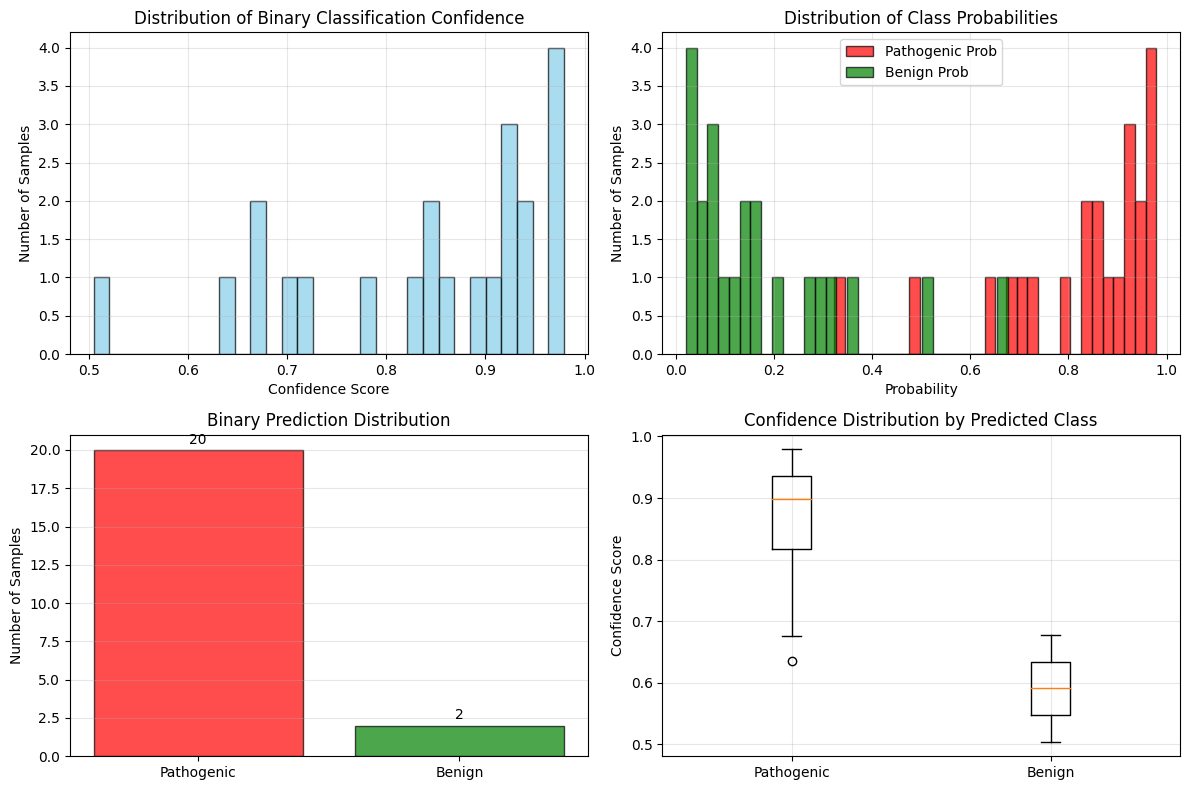


BINARY CLASSIFICATION SUMMARY REPORT
📊 OVERALL STATISTICS:
   Total samples processed: 22
   Pathogenic predictions: 20 (90.9%)
   Benign predictions: 2 (9.1%)
   Average confidence: 0.837
   Median confidence: 0.873
   Min confidence: 0.504
   Max confidence: 0.979

🎯 CONFIDENCE BREAKDOWN:
   High confidence (≥0.8): 68.2%
   Medium confidence (0.6-0.8): 27.3%
   Low confidence (<0.6): 4.5%

✅ Results stored in variables:
   - external_binary_predictions: Binary predictions (1=Pathogenic, 0=Benign)
   - external_binary_probabilities: Probabilities for pathogenic class
   - external_binary_results_df: Complete results DataFrame

--- Binary Classification Analysis Complete ---


34138

In [153]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import gc
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve

# --- 1. Ensure Model is Loaded ---
if 'model' not in locals() or 'best_model_state' not in locals():
    raise NameError("The 'model' or 'best_model_state' is not available.")

if best_model_state:
    print("Loading best model state into model...")
    model.load_state_dict(best_model_state)
else:
    print("Warning: best_model_state is None.")

# Set device to cuda:1
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model.to(device)
model.eval()

# --- 2. Prepare All Samples for Prediction ---
print("\nPreprocessing all samples from X_fused for prediction...")

if 'X_fused' not in locals():
    raise NameError("Original 'X_fused' data is not available.")
if 'scaler_dna' not in locals() or 'scaler_esm2' not in locals() or 'dna_embedding_dim' not in locals():
    raise NameError("Scalers 'scaler_dna', 'scaler_esm2' or 'dna_embedding_dim' not available.")

X_to_predict_original_fused = X_fused
print(f"Found {len(X_to_predict_original_fused)} samples in X_fused to process.")

# Split the fused features back to DNA and ESM2 components
X_to_predict_dna = X_to_predict_original_fused[:, :dna_embedding_dim]
X_to_predict_esm2 = X_to_predict_original_fused[:, dna_embedding_dim:]

# Scale features using the same scalers used during training
X_to_predict_dna_scaled = scaler_dna.transform(X_to_predict_dna)
X_to_predict_esm2_scaled = scaler_esm2.transform(X_to_predict_esm2)

# Concatenate scaled features
X_to_predict_fused_scaled = np.concatenate([X_to_predict_dna_scaled, X_to_predict_esm2_scaled], axis=1)
print(f"Processed {X_to_predict_fused_scaled.shape[0]} samples with {X_to_predict_fused_scaled.shape[1]} features.")

# Verify dimensions match the model's expected input
if 'input_dim' in locals():
    if X_to_predict_fused_scaled.shape[1] != input_dim:
        print(f"CRITICAL WARNING: Final preprocessed data has {X_to_predict_fused_scaled.shape[1]} features, "
              f"but the model was trained on {input_dim} features.")
    else:
        print(f"✓ Feature dimensions match: {X_to_predict_fused_scaled.shape[1]} features")
else:
    print("Warning: 'input_dim' not found. Cannot verify final feature dimension.")
    
X_to_predict_tensor = torch.tensor(X_to_predict_fused_scaled, dtype=torch.float32).to(device)
print(f"Shape of preprocessed tensor for prediction: {X_to_predict_tensor.shape}")

# --- 3. Get Probabilities for All Classes ---
print("\nCalculating probabilities for all classes...")

with torch.no_grad():
    outputs_all = model(X_to_predict_tensor)
    all_class_probabilities = F.softmax(outputs_all, dim=1)

# Convert to numpy for easier handling
all_class_probabilities_np = all_class_probabilities.cpu().numpy()

# --- 4. Binary Classification Setup ---
if 'le' not in locals():
    raise NameError("'LabelEncoder' object 'le' is not available.")

print("\n🎯 BINARY CLASSIFICATION: CLASS -2 vs CLASS 2 ONLY")
print("="*60)

# Get class labels
known_original_labels = le.classes_
print(f"Original classes available: {known_original_labels}")

# Define target classes: -2 vs 2 only
target_classes = {-2, 2}

print(f"\n📋 TARGET CLASSES:")
print(f"   Class -2: Pathogenic")
print(f"   Class 2: Benign") 

# Check if we have both target classes
has_class_neg2 = -2 in known_original_labels
has_class_pos2 = 2 in known_original_labels

if not (has_class_neg2 and has_class_pos2):
    print(f"❌ Required classes not found in label encoder!")
    print(f"   Has class -2: {has_class_neg2}")
    print(f"   Has class 2: {has_class_pos2}")
    print(f"   Available classes: {known_original_labels}")
else:
    # Get encoded indices for classes -2 and 2
    class_neg2_idx = np.where(le.classes_ == -2)[0][0]
    class_pos2_idx = np.where(le.classes_ == 2)[0][0]
    
    print(f"   Class -2 encoded index: {class_neg2_idx}")
    print(f"   Class 2 encoded index: {class_pos2_idx}")
    
    # Extract probabilities for target classes
    prob_pathogenic = all_class_probabilities_np[:, class_neg2_idx]  # Probability of class -2
    prob_benign = all_class_probabilities_np[:, class_pos2_idx]      # Probability of class 2
    
    # Create binary probabilities (normalize between -2 and 2 only)
    total_prob = prob_pathogenic + prob_benign
    total_prob = np.where(total_prob == 0, 1e-8, total_prob)  # Avoid division by zero
    
    # Binary probabilities
    y_pred_proba_pathogenic = prob_pathogenic / total_prob  # Probability of being pathogenic (-2)
    y_pred_proba_benign = prob_benign / total_prob          # Probability of being benign (2)
    
    # Binary predictions (1 = Pathogenic, 0 = Benign)
    y_pred_binary = (y_pred_proba_pathogenic > 0.5).astype(int)
    
    print(f"\n📊 BINARY PREDICTION DISTRIBUTION:")
    print(f"   Total samples: {len(y_pred_binary)}")
    print(f"   Predicted Pathogenic (-2): {np.sum(y_pred_binary == 1)} ({np.sum(y_pred_binary == 1)/len(y_pred_binary)*100:.1f}%)")
    print(f"   Predicted Benign (2): {np.sum(y_pred_binary == 0)} ({np.sum(y_pred_binary == 0)/len(y_pred_binary)*100:.1f}%)")
    
    print(f"\n📈 PROBABILITY STATISTICS:")
    print(f"   Pathogenic probability range: [{y_pred_proba_pathogenic.min():.3f}, {y_pred_proba_pathogenic.max():.3f}]")
    print(f"   Benign probability range: [{y_pred_proba_benign.min():.3f}, {y_pred_proba_benign.max():.3f}]")
    print(f"   Average pathogenic probability: {y_pred_proba_pathogenic.mean():.3f}")
    print(f"   Average benign probability: {y_pred_proba_benign.mean():.3f}")
    
    # --- 5. Create Binary Results DataFrame ---
    binary_results_df = pd.DataFrame({
        'Sample_Index': range(len(y_pred_binary)),
        'Predicted_Class': ['Pathogenic' if pred == 1 else 'Benign' for pred in y_pred_binary],
        'Predicted_Label': [-2 if pred == 1 else 2 for pred in y_pred_binary],
        'Pathogenic_Probability': y_pred_proba_pathogenic,
        'Benign_Probability': y_pred_proba_benign,
        'Confidence': np.maximum(y_pred_proba_pathogenic, y_pred_proba_benign)
    })
    
    print(f"\n📋 BINARY RESULTS PREVIEW:")
    print(binary_results_df.head(10).round(4))
    
    # --- 6. Confidence Analysis ---
    print(f"\n🎯 CONFIDENCE ANALYSIS:")
    high_confidence_mask = binary_results_df['Confidence'] >= 0.8
    medium_confidence_mask = (binary_results_df['Confidence'] >= 0.6) & (binary_results_df['Confidence'] < 0.8)
    low_confidence_mask = binary_results_df['Confidence'] < 0.6
    
    print(f"   High confidence (≥0.8): {np.sum(high_confidence_mask)} samples ({np.sum(high_confidence_mask)/len(binary_results_df)*100:.1f}%)")
    print(f"   Medium confidence (0.6-0.8): {np.sum(medium_confidence_mask)} samples ({np.sum(medium_confidence_mask)/len(binary_results_df)*100:.1f}%)")
    print(f"   Low confidence (<0.6): {np.sum(low_confidence_mask)} samples ({np.sum(low_confidence_mask)/len(binary_results_df)*100:.1f}%)")
    
    # --- 7. Most/Least Confident Predictions ---
    print(f"\n🔝 MOST CONFIDENT PREDICTIONS (Top 5):")
    top_confident = binary_results_df.nlargest(5, 'Confidence')
    for idx, row in top_confident.iterrows():
        print(f"   Sample {row['Sample_Index']}: {row['Predicted_Class']} (confidence: {row['Confidence']:.4f})")
    
    print(f"\n🔻 LEAST CONFIDENT PREDICTIONS (Bottom 5):")
    least_confident = binary_results_df.nsmallest(5, 'Confidence')
    for idx, row in least_confident.iterrows():
        print(f"   Sample {row['Sample_Index']}: {row['Predicted_Class']} (confidence: {row['Confidence']:.4f})")
    
    # --- 8. Visualization ---
    print(f"\n📊 CREATING VISUALIZATIONS...")
    
    # Plot 1: Confidence Distribution
    plt.figure(figsize=(12, 8))
    
    plt.subplot(2, 2, 1)
    plt.hist(binary_results_df['Confidence'], bins=30, alpha=0.7, color='skyblue', edgecolor='black')
    plt.xlabel('Confidence Score')
    plt.ylabel('Number of Samples')
    plt.title('Distribution of Binary Classification Confidence')
    plt.grid(True, alpha=0.3)
    
    # Plot 2: Probability Distribution for Each Class
    plt.subplot(2, 2, 2)
    plt.hist(y_pred_proba_pathogenic, bins=30, alpha=0.7, color='red', label='Pathogenic Prob', edgecolor='black')
    plt.hist(y_pred_proba_benign, bins=30, alpha=0.7, color='green', label='Benign Prob', edgecolor='black')
    plt.xlabel('Probability')
    plt.ylabel('Number of Samples')
    plt.title('Distribution of Class Probabilities')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Plot 3: Prediction Counts
    plt.subplot(2, 2, 3)
    pred_counts = binary_results_df['Predicted_Class'].value_counts()
    bars = plt.bar(pred_counts.index, pred_counts.values, color=['red', 'green'], alpha=0.7, edgecolor='black')
    plt.ylabel('Number of Samples')
    plt.title('Binary Prediction Distribution')
    plt.grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + len(binary_results_df)*0.01,
                f'{int(height)}', ha='center', va='bottom')
    
    # Plot 4: Confidence by Prediction
    plt.subplot(2, 2, 4)
    pathogenic_conf = binary_results_df[binary_results_df['Predicted_Class'] == 'Pathogenic']['Confidence']
    benign_conf = binary_results_df[binary_results_df['Predicted_Class'] == 'Benign']['Confidence']
    
    plt.boxplot([pathogenic_conf, benign_conf], labels=['Pathogenic', 'Benign'])
    plt.ylabel('Confidence Score')
    plt.title('Confidence Distribution by Predicted Class')
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # --- 9. Summary Report ---
    print("\n" + "="*80)
    print("BINARY CLASSIFICATION SUMMARY REPORT")
    print("="*80)
    
    print(f"📊 OVERALL STATISTICS:")
    print(f"   Total samples processed: {len(binary_results_df)}")
    print(f"   Pathogenic predictions: {np.sum(y_pred_binary == 1)} ({np.sum(y_pred_binary == 1)/len(y_pred_binary)*100:.1f}%)")
    print(f"   Benign predictions: {np.sum(y_pred_binary == 0)} ({np.sum(y_pred_binary == 0)/len(y_pred_binary)*100:.1f}%)")
    print(f"   Average confidence: {binary_results_df['Confidence'].mean():.3f}")
    print(f"   Median confidence: {binary_results_df['Confidence'].median():.3f}")
    print(f"   Min confidence: {binary_results_df['Confidence'].min():.3f}")
    print(f"   Max confidence: {binary_results_df['Confidence'].max():.3f}")
    
    print(f"\n🎯 CONFIDENCE BREAKDOWN:")
    print(f"   High confidence (≥0.8): {np.sum(high_confidence_mask)/len(binary_results_df)*100:.1f}%")
    print(f"   Medium confidence (0.6-0.8): {np.sum(medium_confidence_mask)/len(binary_results_df)*100:.1f}%")
    print(f"   Low confidence (<0.6): {np.sum(low_confidence_mask)/len(binary_results_df)*100:.1f}%")
    
    # Store results for further analysis
    external_binary_predictions = y_pred_binary
    external_binary_probabilities = y_pred_proba_pathogenic
    external_binary_results_df = binary_results_df
    
    print(f"\n✅ Results stored in variables:")
    print(f"   - external_binary_predictions: Binary predictions (1=Pathogenic, 0=Benign)")
    print(f"   - external_binary_probabilities: Probabilities for pathogenic class")
    print(f"   - external_binary_results_df: Complete results DataFrame")
    
    print("\n--- Binary Classification Analysis Complete ---")

# Clean up GPU memory
torch.cuda.empty_cache()
gc.collect()

In [154]:
# --- 1. Check Data Alignment ---
if 'external_binary_results_df' not in locals():
    raise NameError("Binary classification results not found. Run the binary classification code first.")

if 'df_test' not in locals():
    raise NameError("df_test not found. Make sure you have the test DataFrame available.")

# Get the binary predictions and probabilities
predicted_binary_labels = external_binary_results_df['Predicted_Label'].values  # -2 or 2
predicted_binary_classes = external_binary_results_df['Predicted_Class'].values  # 'Pathogenic' or 'Benign'
predicted_pathogenic_probs = external_binary_results_df['Pathogenic_Probability'].values
predicted_confidences = external_binary_results_df['Confidence'].values

print(f"Length of df_test: {len(df_test)}")
print(f"Number of binary predictions: {len(predicted_binary_labels)}")
print(f"Number of probability scores: {len(predicted_pathogenic_probs)}")

# Check alignment
if len(df_test) != len(predicted_binary_labels):
    raise ValueError(f"Mismatch in lengths! df_test has {len(df_test)} rows, "
                     f"but there are {len(predicted_binary_labels)} predictions. "
                     f"Ensure df_test corresponds to the data used for X_fused.")

# --- 2. Create the New DataFrame with Selected Columns ---
# Define the columns you want to pull from df_test
columns_from_df_test = {
    'snp_id': 'snp_id',
    'protein_sequence': 'protein_sequence',
    'variant_type': 'variant_type',
    'position': 'pos',
    'gene': 'gene',
    'original': 'original',
    'mutant': 'mutant',
    'frequency': 'frequency',
    'function_class': 'function_class',
}

# Check what columns actually exist in df_test
print(f"\nAvailable columns in df_test: {list(df_test.columns)}")

# Map available columns (handle different column names)
available_columns = {}
for desired_col, actual_col in columns_from_df_test.items():
    if actual_col in df_test.columns:
        available_columns[desired_col] = actual_col
    else:
        # Try alternative column names
        alternatives = {
            'variant_type': ['variant_types', 'variation_type'],
            'position': ['pos', 'chrposvariation', 'genomic_position'],
            'original': ['ref', 'reference', 'ref_allele'],
            'mutant': ['alt', 'alternate', 'alt_allele'],
            'frequency': ['freq', 'allele_frequency', 'maf'],
            'function_class': ['functional_class', 'consequence', 'effect']
        }
        
        found = False
        if desired_col in alternatives:
            for alt_name in alternatives[desired_col]:
                if alt_name in df_test.columns:
                    available_columns[desired_col] = alt_name
                    found = True
                    break
        
        if not found:
            print(f"Warning: Column for '{desired_col}' not found. Trying '{actual_col}'")
            if actual_col in df_test.columns:
                available_columns[desired_col] = actual_col

print(f"Mapped columns: {available_columns}")

# Create the new DataFrame by selecting and renaming available columns
predictions_df = pd.DataFrame()

for desired_col, actual_col in available_columns.items():
    if actual_col in df_test.columns:
        predictions_df[desired_col] = df_test[actual_col].copy()
    else:
        print(f"Warning: Column '{actual_col}' not found in df_test")

# Add any missing essential columns with default values
essential_columns = ['snp_id', 'gene']
for col in essential_columns:
    if col not in predictions_df.columns:
        if col == 'snp_id':
            predictions_df['snp_id'] = [f"UNKNOWN_{i}" for i in range(len(df_test))]
        elif col == 'gene':
            predictions_df['gene'] = 'UNKNOWN'
        print(f"Added default values for missing column: {col}")

# --- 3. Add Binary Prediction and Probability Columns ---
predictions_df['Predicted_Label_Original'] = predicted_binary_labels  # -2 or 2
predictions_df['Predicted_Class'] = predicted_binary_classes  # 'Pathogenic' or 'Benign'
predictions_df['Pathogenic_Probability'] = predicted_pathogenic_probs
predictions_df['Benign_Probability'] = 1 - predicted_pathogenic_probs
predictions_df['Prediction_Confidence'] = predicted_confidences

# --- 4. Add Binary Classification Specific Columns ---
# Add a more descriptive prediction column
predictions_df['Clinical_Significance'] = predictions_df['Predicted_Class'].map({
    'Pathogenic': 'Pathogenic',
    'Benign': 'Benign'
})

# Add confidence categories
def categorize_confidence(confidence):
    if confidence >= 0.8:
        return 'High'
    elif confidence >= 0.6:
        return 'Medium'
    else:
        return 'Low'

predictions_df['Confidence_Category'] = predictions_df['Prediction_Confidence'].apply(categorize_confidence)

# Add risk assessment based on probability
def assess_risk(pathogenic_prob):
    if pathogenic_prob >= 0.8:
        return 'Very High Risk'
    elif pathogenic_prob >= 0.6:
        return 'High Risk'
    elif pathogenic_prob >= 0.4:
        return 'Moderate Risk'
    elif pathogenic_prob >= 0.2:
        return 'Low Risk'
    else:
        return 'Very Low Risk'

predictions_df['Risk_Assessment'] = predictions_df['Pathogenic_Probability'].apply(assess_risk)

# --- 5. Create Summary Columns ---
# Create a comprehensive prediction summary
def create_prediction_summary(row):
    class_name = row['Predicted_Class']
    confidence = row['Prediction_Confidence']
    prob = row['Pathogenic_Probability']
    
    return f"{class_name} (P={prob:.3f}, Conf={confidence:.3f})"

predictions_df['Prediction_Summary'] = predictions_df.apply(create_prediction_summary, axis=1)

# --- 6. Add Interpretation Column ---
def interpret_prediction(row):
    if row['Predicted_Class'] == 'Pathogenic':
        if row['Prediction_Confidence'] >= 0.8:
            return "Strong evidence for pathogenicity"
        elif row['Prediction_Confidence'] >= 0.6:
            return "Moderate evidence for pathogenicity"
        else:
            return "Weak evidence for pathogenicity"
    else:  # Benign
        if row['Prediction_Confidence'] >= 0.8:
            return "Strong evidence for benign effect"
        elif row['Prediction_Confidence'] >= 0.6:
            return "Moderate evidence for benign effect"
        else:
            return "Weak evidence for benign effect"

predictions_df['Interpretation'] = predictions_df.apply(interpret_prediction, axis=1)

# --- 7. Display the Results ---
print("\n" + "="*80)
print("BINARY CLASSIFICATION PREDICTIONS SUMMARY")
print("="*80)

print(f"\nDataFrame shape: {predictions_df.shape}")
print(f"Columns: {list(predictions_df.columns)}")

print(f"\nPrediction Distribution:")
pred_counts = predictions_df['Predicted_Class'].value_counts()
for class_name, count in pred_counts.items():
    percentage = count / len(predictions_df) * 100
    print(f"  {class_name}: {count} ({percentage:.1f}%)")

print(f"\nConfidence Distribution:")
conf_counts = predictions_df['Confidence_Category'].value_counts()
for conf_cat, count in conf_counts.items():
    percentage = count / len(predictions_df) * 100
    print(f"  {conf_cat} Confidence: {count} ({percentage:.1f}%)")

print(f"\nRisk Assessment Distribution:")
risk_counts = predictions_df['Risk_Assessment'].value_counts()
for risk_level, count in risk_counts.items():
    percentage = count / len(predictions_df) * 100
    print(f"  {risk_level}: {count} ({percentage:.1f}%)")

# --- 8. Display Sample Results ---
print(f"\nSample predictions (first 10 rows):")
display_columns = ['snp_id', 'gene', 'Predicted_Class', 'Pathogenic_Probability', 
                  'Confidence_Category', 'Risk_Assessment', 'Interpretation']
available_display_cols = [col for col in display_columns if col in predictions_df.columns]
print(predictions_df[available_display_cols].head(10).to_string(index=False))

# --- 9. High Confidence Predictions ---
print(f"\nHigh Confidence Pathogenic Predictions (top 5):")
high_conf_pathogenic = predictions_df[
    (predictions_df['Predicted_Class'] == 'Pathogenic') & 
    (predictions_df['Confidence_Category'] == 'High')
].nlargest(5, 'Pathogenic_Probability')

if len(high_conf_pathogenic) > 0:
    for idx, row in high_conf_pathogenic.iterrows():
        print(f"  SNP {row['snp_id']}: {row['Pathogenic_Probability']:.4f} prob, {row['Prediction_Confidence']:.4f} conf")
else:
    print("  No high confidence pathogenic predictions found")

print(f"\nHigh Confidence Benign Predictions (top 5):")
high_conf_benign = predictions_df[
    (predictions_df['Predicted_Class'] == 'Benign') & 
    (predictions_df['Confidence_Category'] == 'High')
].nlargest(5, 'Benign_Probability')

if len(high_conf_benign) > 0:
    for idx, row in high_conf_benign.iterrows():
        print(f"  SNP {row['snp_id']}: {row['Benign_Probability']:.4f} prob, {row['Prediction_Confidence']:.4f} conf")
else:
    print("  No high confidence benign predictions found")

# --- 10. Save Results ---
import datetime
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")

# Save full results
results_filename = f"binary_predictions_{timestamp}.csv"
predictions_df.to_csv(results_filename, index=False)
print(f"\n✅ Full results saved to: {results_filename}")

# Save summary report
summary_filename = f"binary_predictions_summary_{timestamp}.txt"
with open(summary_filename, 'w') as f:
    f.write("BINARY CLASSIFICATION PREDICTIONS SUMMARY\n")
    f.write("="*80 + "\n\n")
    f.write(f"Total samples: {len(predictions_df)}\n")
    f.write(f"Pathogenic predictions: {pred_counts.get('Pathogenic', 0)}\n")
    f.write(f"Benign predictions: {pred_counts.get('Benign', 0)}\n")
    f.write(f"Average pathogenic probability: {predictions_df['Pathogenic_Probability'].mean():.4f}\n")
    f.write(f"Average confidence: {predictions_df['Prediction_Confidence'].mean():.4f}\n")
    f.write("\nHigh confidence pathogenic variants:\n")
    for idx, row in high_conf_pathogenic.iterrows():
        f.write(f"  {row['snp_id']}: {row['Pathogenic_Probability']:.4f}\n")

print(f"✅ Summary report saved to: {summary_filename}")

# --- 11. Display DataFrame Info ---
print(f"\nDataFrame Info:")
predictions_df.info()

print(f"\n--- Binary Classification Results Processing Complete ---")

# Store the final DataFrame for further use
binary_predictions_final_df = predictions_df.copy()
print(f"\n✅ Results stored in 'binary_predictions_final_df' for further analysis")

Length of df_test: 22
Number of binary predictions: 22
Number of probability scores: 22

Available columns in df_test: ['#chr', 'pos', 'variation', 'variant_type', 'snp_id', 'original_clinical_sig', 'validation_status', 'function_class', 'gene', 'frequency', 'original', 'mutant', 'TWINSUK_freq', 'TWINSUK_is_mentioned', 'ALSPAC_freq', 'ALSPAC_is_mentioned', 'GENOGRAPHIC_freq', 'GENOGRAPHIC_is_mentioned', 'NorthernSweden_freq', 'NorthernSweden_is_mentioned', 'PRJEB37584_freq', 'PRJEB37584_is_mentioned', 'TOMMO_freq', 'TOMMO_is_mentioned', 'GnomAD_genomes_freq', 'GnomAD_genomes_is_mentioned', '1000Genomes_30X_freq', '1000Genomes_30X_is_mentioned', 'GENOME_DK_freq', 'GENOME_DK_is_mentioned', 'PRJEB36033_freq', 'PRJEB36033_is_mentioned', 'HGDP_Stanford_freq', 'HGDP_Stanford_is_mentioned', 'SGDP_PRJ_freq', 'SGDP_PRJ_is_mentioned', 'Korea1K_freq', 'Korea1K_is_mentioned', 'ALFA_freq', 'ALFA_is_mentioned', 'Korea4K_freq', 'Korea4K_is_mentioned', 'HapMap_freq', 'HapMap_is_mentioned', 'Daghestan_

# Normal Prediction

Loading best model state into model...

Preprocessing all samples from X_fused for prediction...
Found 22 samples in X_fused to process.
Processed all features with 6471 dimensions using separate DNA and ESM2 scalers.
Shape of preprocessed tensor for prediction: torch.Size([22, 6471])

Classifying samples and calculating probabilities...

Plotting predicted class distribution for all processed samples...


/tmp/ipykernel_1461280/3041585684.py:105: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=plot_labels_display_names, y=plot_counts, palette="viridis")


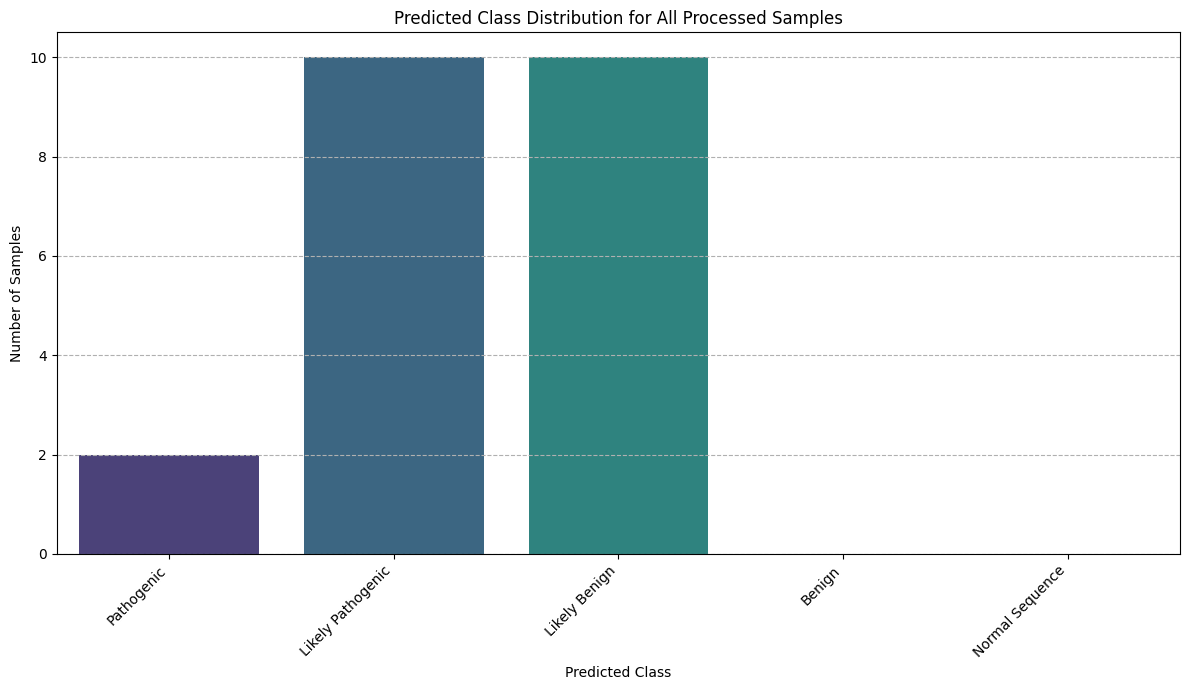


Summary of predictions for all processed samples:
    Predicted as 'Pathogenic' (Original value: -2): 2 samples
    Predicted as 'Likely Pathogenic' (Original value: -1): 10 samples
    Predicted as 'Likely Benign' (Original value: 1): 10 samples
    Predicted as 'Benign' (Original value: 2): 0 samples
    Predicted as 'Normal Sequence' (Original value: 3): 0 samples

Plotting probability score distributions for each predicted class...


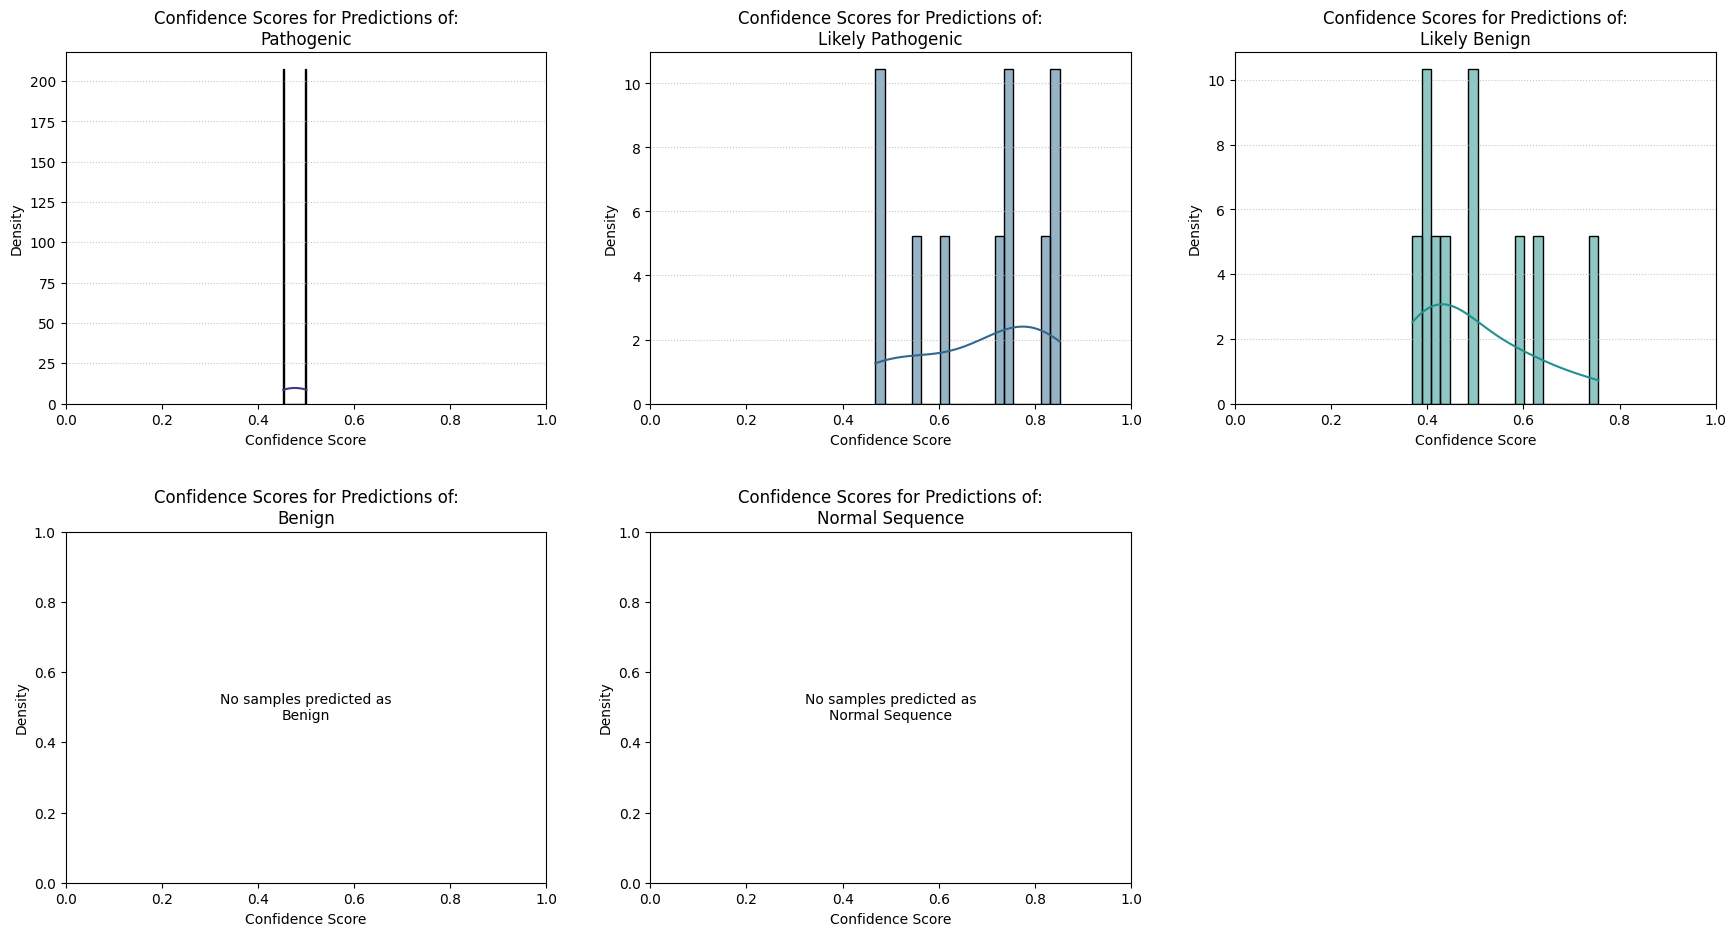


--- Prediction and Probability Plotting Complete ---


In [155]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import gc

# --- 1. Ensure Model is Loaded ---
if 'model' not in locals() or 'best_model_state' not in locals():
    raise NameError("The 'model' or 'best_model_state' is not available.")

if best_model_state:
    print("Loading best model state into model...")
    model.load_state_dict(best_model_state)
else:
    print("Warning: best_model_state is None.")

if 'device' not in locals():
    device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
    print(f"Device not found, setting to: {device}")

model.to(device)
model.eval()

# --- 2. Prepare All Samples for Prediction ---
print("\nPreprocessing all samples from X_fused for prediction...")

if 'X_fused' not in locals():
    raise NameError("Original 'X_fused' data is not available.")
if 'scaler_dna' not in locals() or 'scaler_esm2' not in locals() or 'dna_embedding_dim' not in locals():
    raise NameError("Scalers 'scaler_dna', 'scaler_esm2' or 'dna_embedding_dim' not available.")

X_to_predict_original_fused = X_fused
print(f"Found {len(X_to_predict_original_fused)} samples in X_fused to process.")

# Split the fused features back to DNA and ESM2 components
X_to_predict_dna = X_to_predict_original_fused[:, :dna_embedding_dim]
X_to_predict_esm2 = X_to_predict_original_fused[:, dna_embedding_dim:]

# Scale features using the same scalers used during training
X_to_predict_dna_scaled = scaler_dna.transform(X_to_predict_dna)
X_to_predict_esm2_scaled = scaler_esm2.transform(X_to_predict_esm2)

# Concatenate scaled features
X_to_predict_fused_scaled = np.concatenate([X_to_predict_dna_scaled, X_to_predict_esm2_scaled], axis=1)
print(f"Processed all features with {X_to_predict_fused_scaled.shape[1]} dimensions using separate DNA and ESM2 scalers.")

if 'input_dim' in locals():
    if X_to_predict_fused_scaled.shape[1] != input_dim:
        print(f"CRITICAL WARNING: Final preprocessed data for ALL samples has {X_to_predict_fused_scaled.shape[1]} features, "
              f"but the model was trained on {input_dim} features.")
else:
    print("Warning: 'input_dim' not found. Cannot verify final feature dimension for ALL samples.")
    
X_to_predict_tensor = torch.tensor(X_to_predict_fused_scaled, dtype=torch.float32).to(device)
print(f"Shape of preprocessed tensor for prediction: {X_to_predict_tensor.shape}")

# --- 3. Perform Classification and Get Probabilities ---
print("\nClassifying samples and calculating probabilities...")
predicted_encoded_labels_list = []
predicted_probabilities_list = []

with torch.no_grad():
    outputs_all = model(X_to_predict_tensor)
    probabilities_all = F.softmax(outputs_all, dim=1)
    max_probabilities, predicted_encoded_labels = torch.max(probabilities_all, 1)
    
    predicted_encoded_labels_list.extend(predicted_encoded_labels.cpu().numpy())
    predicted_probabilities_list.extend(max_probabilities.cpu().numpy())

predicted_encoded_labels_np = np.array(predicted_encoded_labels_list)
predicted_max_probs_np = np.array(predicted_probabilities_list)

# --- 4. Interpret Predictions ---
if 'le' not in locals():
    raise NameError("'LabelEncoder' object 'le' is not available.")
predicted_original_labels_all = le.inverse_transform(predicted_encoded_labels_np)

# --- 5. Plot Predicted Class Distribution ---
print("\nPlotting predicted class distribution for all processed samples...")
unique_predicted_labels, counts = np.unique(predicted_original_labels_all, return_counts=True)
predicted_counts_map = dict(zip(unique_predicted_labels, counts))
known_original_labels = le.classes_

# Define custom label overrides
custom_label_override_map = {
    -2: 'Pathogenic',
    -1: 'Likely Pathogenic',
    1:  'Likely Benign',
    2:  'Benign',
    3:  'Normal Sequence'
}

# Create display names
updated_original_to_display_name_map = {}
for original_label_val in known_original_labels:
    final_name = custom_label_override_map.get(original_label_val, str(original_label_val))
    updated_original_to_display_name_map[original_label_val] = final_name

plot_labels_display_names = [updated_original_to_display_name_map.get(l, str(l)) for l in known_original_labels]
plot_counts = [predicted_counts_map.get(label, 0) for label in known_original_labels]

plt.figure(figsize=(12, 7))
sns.barplot(x=plot_labels_display_names, y=plot_counts, palette="viridis")
plt.title('Predicted Class Distribution for All Processed Samples')
plt.xlabel('Predicted Class')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

print("\nSummary of predictions for all processed samples:")
for i, original_label_val in enumerate(known_original_labels):
    display_name = plot_labels_display_names[i]
    count = plot_counts[i]
    print(f"    Predicted as '{display_name}' (Original value: {original_label_val}): {count} samples")

# --- 6. Plot Probability Score Distributions ---
print("\nPlotting probability score distributions for each predicted class...")
num_known_classes = len(known_original_labels)
if num_known_classes > 0:
    ncols_prob = 3 if num_known_classes > 2 else num_known_classes
    nrows_prob = (num_known_classes + ncols_prob - 1) // ncols_prob
    fig_prob, axes_prob = plt.subplots(nrows_prob, ncols_prob, figsize=(6 * ncols_prob, 5 * nrows_prob), squeeze=False)
    axes_prob_flat = axes_prob.flatten()
    for i, original_label_val_iter in enumerate(known_original_labels):
        current_display_name = updated_original_to_display_name_map.get(original_label_val_iter, str(original_label_val_iter))
        try:
            encoded_equivalent_for_iter = le.transform([original_label_val_iter])[0]
            scores_for_this_predicted_class = predicted_max_probs_np[predicted_encoded_labels_np == encoded_equivalent_for_iter]
        except ValueError:
            scores_for_this_predicted_class = np.array([])
            print(f"Warning: Could not find encoded equivalent for {original_label_val_iter} during probability plotting.")
        ax = axes_prob_flat[i]
        if len(scores_for_this_predicted_class) > 0:
            sns.histplot(scores_for_this_predicted_class, ax=ax, kde=True, bins=20, stat="density", color=sns.color_palette("viridis", num_known_classes)[i])
            ax.set_title(f'Confidence Scores for Predictions of:\n{current_display_name}')
            ax.set_ylabel('Density'); ax.set_xlabel('Confidence Score'); ax.set_xlim(0, 1)
            ax.grid(axis='y', linestyle=':', alpha=0.7)
        else:
            ax.text(0.5, 0.5, f'No samples predicted as\n{current_display_name}', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
            ax.set_title(f'Confidence Scores for Predictions of:\n{current_display_name}')
            ax.set_xlabel('Confidence Score'); ax.set_ylabel('Density'); ax.set_xlim(0, 1)
    for j in range(num_known_classes, len(axes_prob_flat)):
        fig_prob.delaxes(axes_prob_flat[j])
    plt.tight_layout(pad=3.0); plt.show()
else:
    print("No known classes to plot probability distributions for.")
# Create prediction dataframe
import pandas as pd

predictions_df = pd.DataFrame({
    'Predicted_Label': predicted_original_labels_all,
    'Predicted_Encoded': predicted_encoded_labels_np,
    'Confidence_Score': predicted_max_probs_np
})

print("\n--- Prediction and Probability Plotting Complete ---")

In [156]:
predictions_df

,Predicted_Label,Predicted_Encoded,Confidence_Score
0,1,2,0.430256
1,-1,1,0.837108
2,1,2,0.411856
3,-1,1,0.813204
4,-1,1,0.560341
5,1,2,0.399226
6,1,2,0.369146
7,1,2,0.401107
8,1,2,0.756063
9,1,2,0.496654


In [157]:
if len(df_test) != len(predicted_original_labels_all):
    raise ValueError(f"Mismatch in lengths! df_test has {len(df_test)} rows, "
                     f"but there are {len(predicted_original_labels_all)} predictions. "
                     "Ensure df_test corresponds to the data used for X_fused.")

print(f"Length of df_test: {len(df_test)}")
print(f"Number of predictions: {len(predicted_original_labels_all)}")
print(f"Number of probability scores: {len(predicted_max_probs_np)}")

# --- 2. Create the New DataFrame with Selected Columns ---
# Define the columns you want to pull from df_test
# Using 'variant_types' as it appears in your example df_test head for 'variant_type'
# Using 'chrposvariation' for 'pos' as a specific 'pos' column is not shown
columns_from_df_test = {
    'snp_id': 'snp_id',
    'protein_sequence': 'protein_sequence',
    'variant_type': 'variant_type', # Mapping user's request 'variant_type' to 'variant_types'
    'position': 'pos',   # Mapping user's request 'pos' to 'chrposvariation'
    'gene': 'gene',
    'original': 'original',  # Assuming 'original' is a column in df_test
    'mutant': 'mutant',
    'frequency': 'frequency',
    'function_class': 'function_class',  # Assuming 'function_class' is a column in df_test
}

# Check if all required columns exist in df_test
missing_cols = [col for col in columns_from_df_test.values() if col not in df_test.columns]
if missing_cols:
    raise KeyError(f"The following required columns are missing from df_test: {missing_cols}")

# Create the new DataFrame by selecting and renaming columns
predictions_df = df_test[list(columns_from_df_test.values())].copy()
predictions_df.rename(columns={v: k for k, v in columns_from_df_test.items()}, inplace=True)


# --- 3. Add Prediction and Probability Columns ---

predictions_df['Predicted_Label_Original'] = predicted_original_labels_all
predictions_df['Prediction_Confidence'] = predicted_max_probs_np

predictions_df['Predicted_Label_Display'] = None

for index, row in predictions_df.iterrows():
    original_label = row['Predicted_Label_Original']
    display_name = updated_original_to_display_name_map.get(original_label, str(original_label))
    predictions_df.at[index, 'Predicted_Label_Display'] = display_name
# --- 5. Display the Head of the New DataFrame ---
print("\nHead of the new predictions DataFrame:")
print(predictions_df.head())

# --- 6. Display Info about the New DataFrame ---
print("\nInfo for the new predictions DataFrame:")
predictions_df.info()

Length of df_test: 22
Number of predictions: 22
Number of probability scores: 22

Head of the new predictions DataFrame:
  snp_id                                   protein_sequence  variant_type  \
0  E320Q  MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...           NaN   
1  T422A  MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...           NaN   
2   E32K  MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSKPFLIPYLSGPDKNL...           NaN   
3  E110K  MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...           NaN   
4  E110Q  MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...           NaN   

    position     gene original mutant  frequency function_class  \
0  227698755  SLC19A3        C      G        NaN      synthetic   
1  227688214  SLC19A3        T      C        NaN      synthetic   
2  227702223  SLC19A3        C      T        NaN      synthetic   
3  227699385  SLC19A3        C      T        NaN      synthetic   
4  227699385  SLC19A3        C      G        NaN      synthetic   

   Predicted_

In [158]:
predictions_df

,snp_id,protein_sequence,variant_type,position,gene,original,mutant,frequency,function_class,Predicted_Label_Original,Prediction_Confidence,Predicted_Label_Display
0,E320Q,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...,NaN,227698755,SLC19A3,C,G,NaN,synthetic,1,0.430256,Likely Benign
1,T422A,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...,NaN,227688214,SLC19A3,T,C,NaN,synthetic,-1,0.837108,Likely Pathogenic
2,E32K,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSKPFLIPYLSGPDKNL...,NaN,227702223,SLC19A3,C,T,NaN,synthetic,1,0.411856,Likely Benign
3,E110K,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...,NaN,227699385,SLC19A3,C,T,NaN,synthetic,-1,0.813204,Likely Pathogenic
4,E110Q,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...,NaN,227699385,SLC19A3,C,G,NaN,synthetic,-1,0.560341,Likely Pathogenic
5,N297A,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...,NaN,227698824,SLC19A3,GTT,CGC,NaN,synthetic,1,0.399226,Likely Benign
6,F56A,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...,NaN,227699547,SLC19A3,GAA,CGC,NaN,synthetic,1,0.369146,Likely Benign
7,Y151F,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...,NaN,227699262,SLC19A3,T,A,NaN,synthetic,1,0.401107,Likely Benign
8,N45Q,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKQL...,NaN,227702184,SLC19A3,GTT,CTG,NaN,synthetic,1,0.756063,Likely Benign
9,N166Q,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...,NaN,227699217,SLC19A3,GTT,CTG,NaN,synthetic,1,0.496654,Likely Benign



Added 'normal_seq' column to predictions_df.
Number of normal sequences: 0
Number of abnormal sequences: 22


/tmp/ipykernel_1461280/683625457.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=abnormal_predictions_df, x='Predicted_Label_Display', order=abnormal_predictions_df['Predicted_Label_Display'].value_counts().index, palette="viridis")


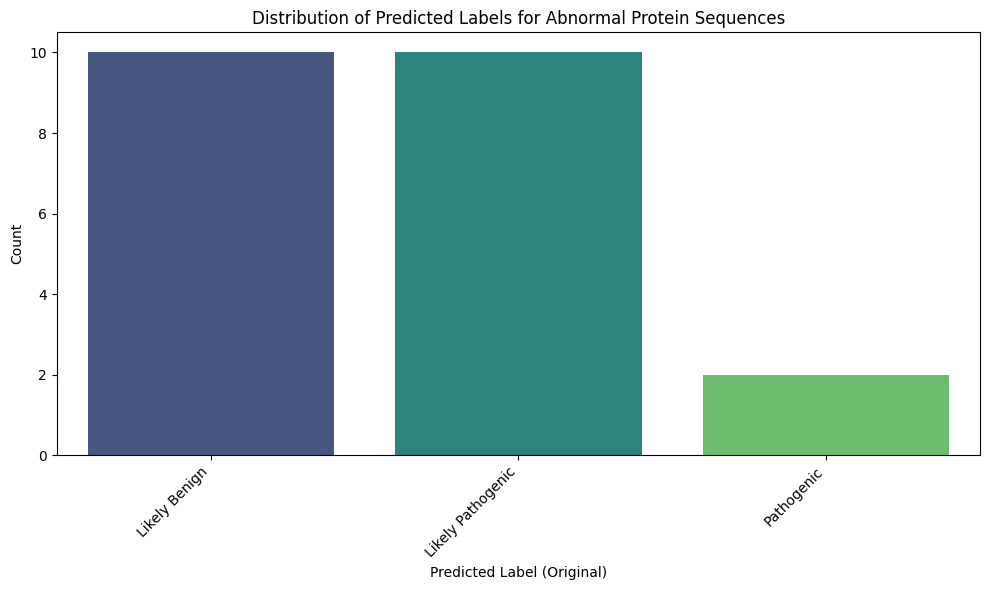

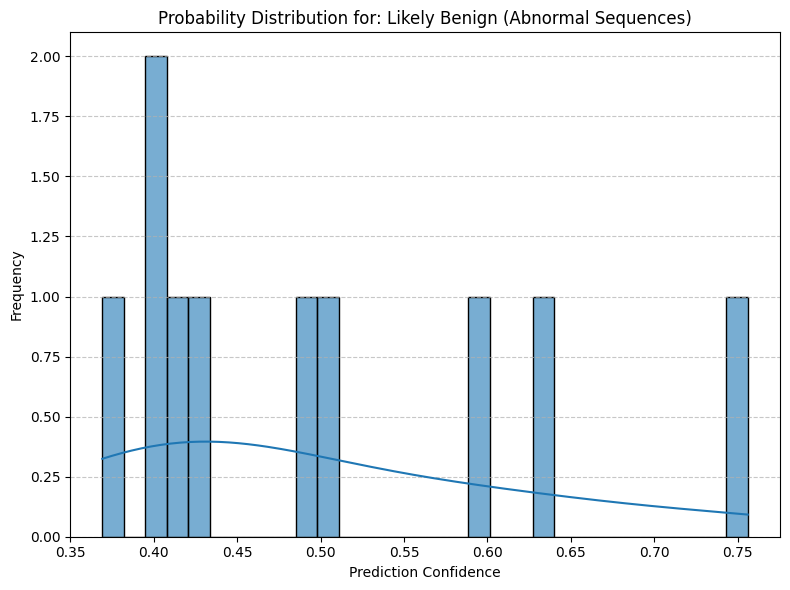

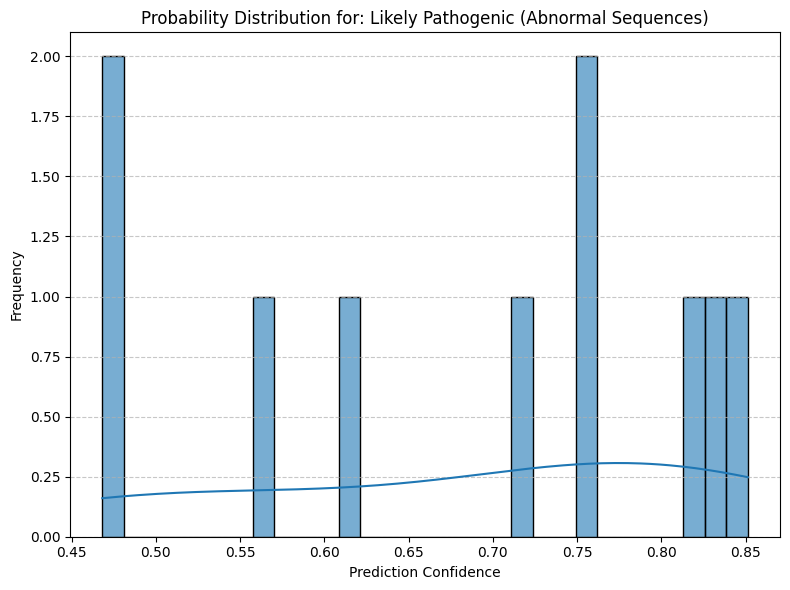

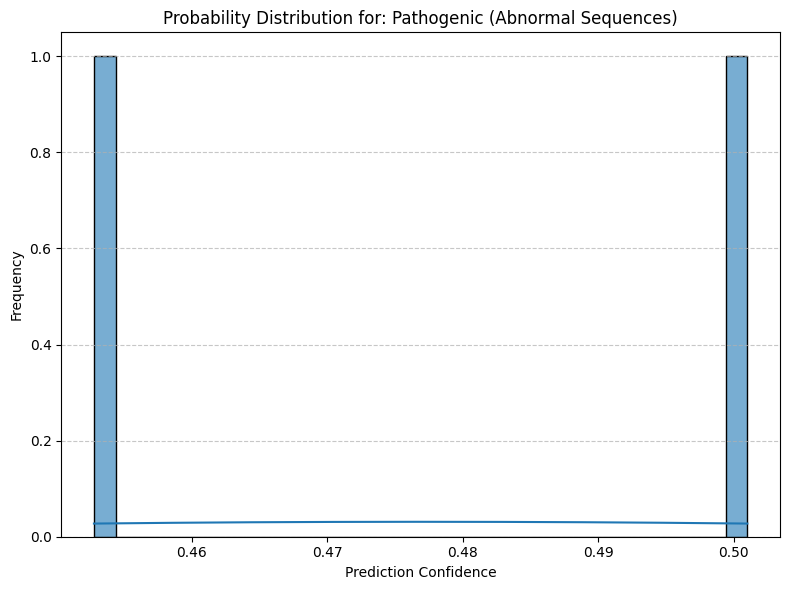

In [159]:
normal_seq = 'MDVPGPVSRRAAAAAATVLLRTARVRRECWFLPTALLCAYGFFASLRPSEPFLTPYLLGPDKNLTEREVFNEIYPVWTYSYLVLLFPVFLATDYLRYKPVVLLQGLSLIVTWFMLLYAQGLLAIQFLEFFYGIATATEIAYYSYIYSVVDLGMYQKVTSYCRSATLVGFTVGSVLGQILVSVAGWSLFSLNVISLTCVSVAFAVAWFLPMPQKSLFFHHIPSTCQRVNGIKVQNGGIVTDTPASNHLPGWEDIESKIPLNMEEPPVEEPEPKPDRLLVLKVLWNDFLMCYSSRPLLCWSVWWALSTCGYFQVVNYTQGLWEKVMPSRYAAIYNGGVEAVSTLLGAVAVFAVGYIKISWSTWGEMTLSLFSLLIAAAVYIMDTVGNIWVCYASYVVFRIIYMLLITIATFQIAANLSMERYALVFGVNTFIALALQTLLTLIVVDASGLGLEITTQFLIYASYFALIAVVFLASGAVSVMKKCRKLEDPQSSSQVTTS'
normal_seq_2 = 'MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNLTSAEITNEIFPVWTYSYLVLLLPVFVLTDYVRYKPVIILQGISFIITWLLLLFGQGVKTMQVVEFFYGMVTAAEVAYYAYIYSVVSPEHYQRVSGYCRSVTLAAYTAGSVLAQLLVSLANMSYFYLNVISLASVSVAFLFSLFLPMPKKSMFFHAKPSREIKKSSSVNPVLEETHEGEAPGCEEQKPTSEILSTSGKLNKGQLNSLKPSNVTVDVFVQWFQDLKECYSSKRLFYWSLWWAFATAGFNQVLNYVQILWDYKAPSQDSSIYNGAVEAIATFGGAVAAFAVGYVKVNWDLLGELALVVFSVVNAGSLFLMHYTANIWACYAGYLIFKSSYMLLITIAVFQIAVNLNVERYALVFGINTFIALVIQTIMTVIVVDQRGLNLPVSIQFLVYGSYFAVIAGIFLMRSMYITYSTKSQKDVQSPAPSENPDVSHPEEESNIIMSTKL'

predictions_df['normal_seq'] = None
normal_ones = 0
abnormal_ones = 0

for i, row in predictions_df.iterrows():
    if row['protein_sequence'] == normal_seq or row['protein_sequence'] == normal_seq_2:
        predictions_df.at[i, 'normal_seq'] = True
        normal_ones += 1
    else:
        predictions_df.at[i, 'normal_seq'] = False
        abnormal_ones += 1  

print("\nAdded 'normal_seq' column to predictions_df.")
print(f"Number of normal sequences: {normal_ones}")
print(f"Number of abnormal sequences: {abnormal_ones}")

# Filter abnormal sequences
abnormal_predictions_df = predictions_df[predictions_df['normal_seq'] == False]

# Plot the distribution of predicted labels for abnormal sequences
plt.figure(figsize=(10, 6))
sns.countplot(data=abnormal_predictions_df, x='Predicted_Label_Display', order=abnormal_predictions_df['Predicted_Label_Display'].value_counts().index, palette="viridis")
plt.title('Distribution of Predicted Labels for Abnormal Protein Sequences')
plt.xlabel('Predicted Label (Original)')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Plot probability distribution for each label in abnormal_predictions_df in separate windows
unique_labels = np.unique(abnormal_predictions_df['Predicted_Label_Display'])

for label in unique_labels:
    plt.figure(figsize=(8, 6))
    label_probs = abnormal_predictions_df[abnormal_predictions_df['Predicted_Label_Display'] == label]['Prediction_Confidence']
    sns.histplot(label_probs, kde=True, bins=30, alpha=0.6)
    plt.title(f'Probability Distribution for: {label} (Abnormal Sequences)')
    plt.xlabel('Prediction Confidence')
    plt.ylabel('Frequency')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

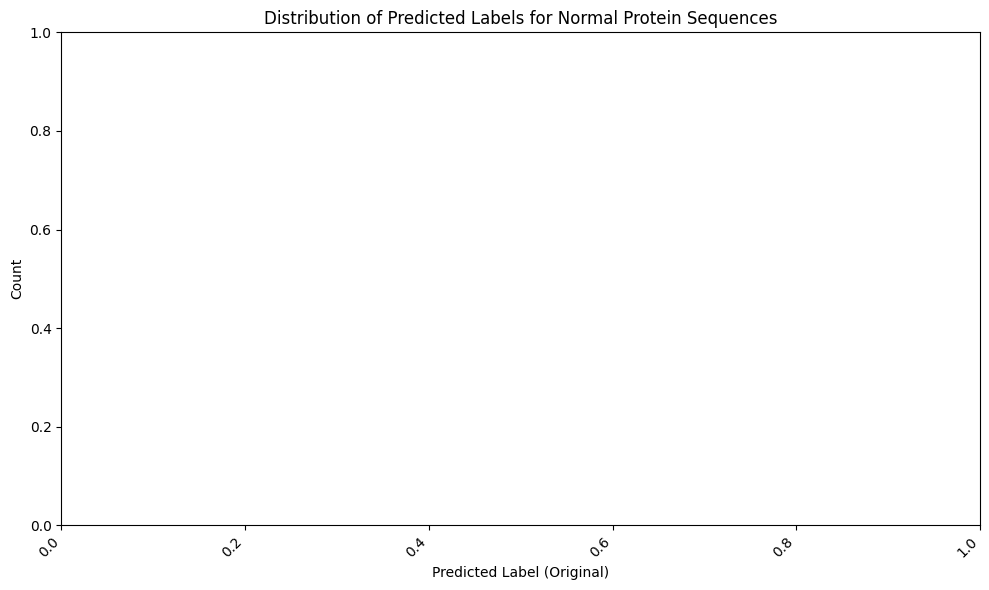

In [161]:
# Filter abnormal sequences
normal_predictions_df = predictions_df[predictions_df['normal_seq'] == True]

# Plot the distribution of predicted labels for abnormal sequences
plt.figure(figsize=(10, 6))
sns.countplot(data=normal_predictions_df, x='Predicted_Label_Display', order=normal_predictions_df['Predicted_Label_Display'].value_counts().index, palette="viridis")
plt.title('Distribution of Predicted Labels for Normal Protein Sequences')
plt.xlabel('Predicted Label (Original)')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
# Plot probability distribution for each label in abnormal_predictions_df in separate windows
unique_labels = np.unique(normal_predictions_df['Predicted_Label_Display'])

for label in unique_labels:
    plt.figure(figsize=(8, 6))
    label_probs = normal_predictions_df[normal_predictions_df['Predicted_Label_Display'] == label]['Prediction_Confidence']
    sns.histplot(label_probs, kde=True, bins=30, alpha=0.6)
    plt.title(f'Probability Distribution for: {label} (Normal Sequences)')
    plt.xlabel('Prediction Confidence')
    plt.ylabel('Frequency')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [162]:
predictions_df.to_csv('results/predictions_with_details_full_reduced_normal.csv', index=False)
print("\nSaved predictions_df to 'predictions_with_details_full_reduced_normal.csv'")


Saved predictions_df to 'predictions_with_details_full_reduced_normal.csv'


### Load Test

In [140]:
import pandas as pd
file_path = "custom_mutation.csv"

df = pd.read_csv(file_path)

# Print the head of the dataframe
print("DataFrame Head:")
# df

DataFrame Head:


In [141]:
df_combined = df


In [142]:
# Drop any rows that contain error-related words (Error, error, fail, etc.)
print(f"Number of rows before cleaning: {len(df_combined)}")

# Convert all values to string and check for error-related terms case-insensitively
error_pattern = '(?i)(error|fail|exception|invalid|timeout|crash)'
mask = df_combined.astype(str).apply(lambda x: x.str.contains(error_pattern)).any(axis=1)
df_clean = df_combined[~mask]

print(f"Number of rows after cleaning: {len(df_clean)}")
print(f"Removed {len(df_combined) - len(df_clean)} rows containing error-related terms")

# Display the first few rows of the cleaned dataframe
df_clean.head()

Number of rows before cleaning: 22
Number of rows after cleaning: 22
Removed 0 rows containing error-related terms


/tmp/ipykernel_1461280/1749372498.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = df_combined.astype(str).apply(lambda x: x.str.contains(error_pattern)).any(axis=1)


,#chr,pos,variation,variant_type,snp_id,clinical_significance,validation_status,function_class,gene,frequency,...,Min_Frequency,Total_Studies,by-frequency,by-alfa,by-cluster,generated_dna,generated_mRNA,protein_sequence,ref,alt
0,2,227698755,C>G,NaN,E320Q,NaN,NaN,synthetic,SLC19A3,NaN,...,0.0,0,0,0,0,CTATGCATGAATGAATGAATTCCTCAATATCTCTCTCTGATTTAGA...,AAGAGCGCCUGGAUCCAUCCGACAGCCGCGGGUGCGUGGUCGUGCG...,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...,C,G
1,2,227688214,T>C,NaN,T422A,NaN,NaN,synthetic,SLC19A3,NaN,...,0.0,0,0,0,0,CTATGCATGAATGAATGAATTCCTCAATATCTCTCTCTGATTTAGA...,AAGAGCGCCUGGAUCCAUCCGACAGCCGCGGGUGCGUGGUCGUGCG...,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...,T,C
2,2,227702223,C>T,NaN,E32K,NaN,NaN,synthetic,SLC19A3,NaN,...,0.0,0,0,0,0,CTATGCATGAATGAATGAATTCCTCAATATCTCTCTCTGATTTAGA...,AAGAGCGCCUGGAUCCAUCCGACAGCCGCGGGUGCGUGGUCGUGCG...,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSKPFLIPYLSGPDKNL...,C,T
3,2,227699385,C>T,NaN,E110K,NaN,NaN,synthetic,SLC19A3,NaN,...,0.0,0,0,0,0,CTATGCATGAATGAATGAATTCCTCAATATCTCTCTCTGATTTAGA...,AAGAGCGCCUGGAUCCAUCCGACAGCCGCGGGUGCGUGGUCGUGCG...,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...,C,T
4,2,227699385,C>G,NaN,E110Q,NaN,NaN,synthetic,SLC19A3,NaN,...,0.0,0,0,0,0,CTATGCATGAATGAATGAATTCCTCAATATCTCTCTCTGATTTAGA...,AAGAGCGCCUGGAUCCAUCCGACAGCCGCGGGUGCGUGGUCGUGCG...,MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...,C,G


In [143]:
df_clean = df_combined.copy()

In [144]:
# Rename the clinical_significance column to original_clinical_sig
if 'clinical_significance' in df_clean.columns and 'original_clinical_sig' not in df_clean.columns:
    df_clean = df_clean.rename(columns={'clinical_significance': 'original_clinical_sig'})
    print("Renamed 'clinical_significance' column to 'original_clinical_sig'")
elif 'original_clinical_sig' in df_clean.columns:
    print("Column 'original_clinical_sig' already exists")
else:
    print("Column 'clinical_significance' not found in the dataframe")

# Rename the generated_dna column to reverse_complement_dna if needed
if 'generated_dna' in df_clean.columns and 'reverse_complement_dna' not in df_clean.columns:
    df_clean = df_clean.rename(columns={'generated_dna': 'reverse_complement_dna'})
    print("Renamed 'generated_dna' column to 'reverse_complement_dna'")
elif 'reverse_complement_dna' in df_clean.columns:
    print("Column 'reverse_complement_dna' already exists")
else:
    print("Column 'generated_dna' not found in the dataframe")


Renamed 'clinical_significance' column to 'original_clinical_sig'
Renamed 'generated_dna' column to 'reverse_complement_dna'


In [145]:
# Identify SNP IDs with labels other than 'normal' and NaN
labeled_snps = df_clean.loc[
    (df_clean['original_clinical_sig'].notna()) & (df_clean['original_clinical_sig'] != 'nan') & (df_clean['original_clinical_sig'] != 'normal'),
    'snp_id'
].unique().tolist()

# Print the number of unique labeled SNP IDs
print(f"Found {len(labeled_snps)} unique SNP IDs with labels other than 'normal' and NaN")

# Filter dataframes based on SNP IDs
snp_id_mask = df_clean['snp_id'].isin(labeled_snps)
df_labeled = df_clean[snp_id_mask].copy()
df_unlabeled = df_clean[~snp_id_mask].copy()

print(f"Labeled data shape: {df_labeled.shape}")
print(f"Unlabeled data shape: {df_unlabeled.shape}")


Found 0 unique SNP IDs with labels other than 'normal' and NaN
Labeled data shape: (0, 88)
Unlabeled data shape: (22, 88)


In [146]:
# Count the number of rows before filtering
print(f"Total rows before filtering: {len(df_unlabeled)}")

# Identify rows with 'normal' clinical significance
normal_mask = df_unlabeled['original_clinical_sig'] == 'normal'
normal_indices = df_unlabeled[normal_mask].index
non_normal_indices = df_unlabeled[~normal_mask].index

# Calculate how many 'normal' samples to keep (10%)
keep_count = int(len(normal_indices) * 0.1)

# Randomly select 10% of 'normal' samples to keep
import random
random.seed(42)  # For reproducibility
indices_to_keep = random.sample(list(normal_indices), keep_count) if len(normal_indices) > 0 else []

# Create a new dataframe with reduced 'normal' samples
filtered_indices = list(indices_to_keep) + list(non_normal_indices)
unlabeled_df = df_unlabeled.loc[filtered_indices]

# Count the number of rows after filtering
print(f"Total rows after filtering: {len(unlabeled_df)}")
print(f"Removed {len(normal_indices) - keep_count} 'normal' samples ({90 if len(normal_indices) > 0 else 0}% of normal samples)")

# Display the first few rows


Total rows before filtering: 22
Total rows after filtering: 22
Removed 0 'normal' samples (0% of normal samples)


In [147]:

df_test = unlabeled_df.copy()
# Rename reverse_complement_dna column to sequence
df_test.rename(columns={'reverse_complement_dna': 'sequence'}, inplace=True)

In [148]:
print(df_test.shape)
df_processed = df_test

(22, 88)


In [149]:
# Load the specific DNA-BERT embeddings file
import os
import numpy as np

# Load the specific file
file_path = "embeddings/dnabert_embeddings_labeling_external1757407509.npy"
X_nn = np.load(file_path)
print(f"Loaded DNA-BERT embeddings from {file_path}")
print(f"Loaded embedding shape: {X_nn.shape}")


Loaded DNA-BERT embeddings from embeddings/dnabert_embeddings_labeling_external1757407509.npy
Loaded embedding shape: (22, 3840)


In [150]:
# Load the previously saved ESM-2 embeddings
import numpy as np
import os

# Path to the saved embeddings
embeddings_path = "embeddings/labeling_external_data_20250909_014714.npy"

# Check if the file exists
if os.path.exists(embeddings_path):
    print(f"Loading ESM-2 embeddings from {embeddings_path}...")
    X_nn_esm2 = np.load(embeddings_path)
    print(f"Loaded ESM-2 embeddings with shape: {X_nn_esm2.shape}")
else:
    print(f"Error: Could not find embeddings file at {embeddings_path}")
    X_nn_esm2 = np.array([])

Loading ESM-2 embeddings from embeddings/labeling_external_data_20250909_014714.npy...
Loaded ESM-2 embeddings with shape: (22, 2560)


In [151]:
import numpy as np

x_3_columns = ['PRJEB37584_freq', 'PRJEB37584_is_mentioned', 'GoNL_freq', 'GoNL_is_mentioned', 'GnomAD_genomes_freq', 'GnomAD_genomes_is_mentioned', 'TOPMED_freq', 'TOPMED_is_mentioned', 'TWINSUK_freq', 'TWINSUK_is_mentioned', 'ALSPAC_freq', 'ALSPAC_is_mentioned', 'Siberian_freq', 'Siberian_is_mentioned', 'SGDP_PRJ_freq', 'SGDP_PRJ_is_mentioned', 'GENOME_DK_freq', 'GENOME_DK_is_mentioned', 'GoESP_freq', 'GoESP_is_mentioned', 'Chileans_freq', 'Chileans_is_mentioned', 'HGDP_Stanford_freq', 'HGDP_Stanford_is_mentioned', 'HapMap_freq', 'HapMap_is_mentioned', 'NorthernSweden_freq', 'NorthernSweden_is_mentioned', 'Korea4K_freq', 'Korea4K_is_mentioned', 'GnomAD_exomes_freq', 'GnomAD_exomes_is_mentioned', 'Vietnamese_freq', 'Vietnamese_is_mentioned', 'ALFA_freq', 'ALFA_is_mentioned', 'Daghestan_freq', 'Daghestan_is_mentioned', 'GENOGRAPHIC_freq', 'GENOGRAPHIC_is_mentioned', 'Korea1K_freq', 'Korea1K_is_mentioned', 'PAGE_STUDY_freq', 'PAGE_STUDY_is_mentioned', 'Estonian_freq', 'Estonian_is_mentioned', 'TOMMO_freq', 'TOMMO_is_mentioned', 'PRJEB36033_freq', 'PRJEB36033_is_mentioned', '1000Genomes_30X_freq', '1000Genomes_30X_is_mentioned', '1000Genomes_freq', '1000Genomes_is_mentioned', 'Qatari_freq', 'Qatari_is_mentioned', 'KOREAN_freq', 'KOREAN_is_mentioned', 'FINRISK_freq', 'FINRISK_is_mentioned', 'ExAC_freq', 'ExAC_is_mentioned', 'MGP_freq', 'MGP_is_mentioned', 'Avg_Frequency', 'Max_Frequency', 'Min_Frequency', 'Total_Studies', 'by-frequency', 'by-alfa', 'by-cluster']
x_3 = df_processed.values[:, df_processed.columns.isin(x_3_columns)]
# Ensure x_3 is a NumPy array of type float32
x_3 = np.array(x_3, dtype=np.float32)
print("x_3 type:", type(x_3))
print("x_3 dtype:", x_3.dtype)
print("x_3 shape:", x_3.shape)
x_3[0:32,:]


x_3 type: <class 'numpy.ndarray'>
x_3 dtype: float32
x_3 shape: (22, 71)


array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [152]:
# Ensure that the number of embeddings from both methods match
if X_nn.shape[0] != X_nn_esm2.shape[0]:
    raise ValueError("Mismatch in number of embeddings: DNA embeddings have shape {} while ESM-2 embeddings have shape {}.".format(X_nn.shape, X_nn_esm2.shape))

# Fuse the embeddings by concatenating along the feature dimension (axis=1)
X_fused = np.concatenate((X_nn, X_nn_esm2,x_3), axis=1)

# Print the shape of the fused embeddings
print("Fused embeddings shape:", X_fused.shape)


Fused embeddings shape: (22, 6471)
